# [GSE57409](https://www.ncbi.nlm.nih.gov/geo/query/acc.cgi?acc=GSE57409)

> - Author: Cao Qiang
> - Email: qiangcao2014@gmail.com
> - Created: 2020-09-17
> - Modified: 2025-01-11

# 1. Experimental Design

> Epigenomic comparison of distinct pluripotent stem cell states reveals a new class of enhancers with roles throughout mammalian development.
> - Factor DC, Corradin O, Zentner GE, Saiakhova A, Song L, Chenoweth JG, McKay RD, Crawford GE, Scacheri PC, Tesar PJ. Epigenomic comparison reveals activation of "seed" enhancers during transition from naive to primed pluripotency. Cell Stem Cell. 2014 Jun 5;14(6):854-63. doi: 10.1016/j.stem.2014.05.005.
> - polyA RNA-seq
> - Illumina HiSeq 2000, PE100
> - mm10

| Sample | Organism | Cell | Source | Strain | Treatment | Replicate |
| - | - | - | - | - | - | - |
| mESC | Mus musculus | mESC | Embryionic stem cell | - | - | rep1~4 |
| mEpiSC | Mus musculus | mESC | Epiblast stem cells | - | - | rep1~4 |

# 2. Preprocessing

In [1]:
library(tidyverse)
suppressPackageStartupMessages(library(limma))
suppressPackageStartupMessages(library(edgeR))
suppressPackageStartupMessages(library(DESeq2))
suppressPackageStartupMessages(library(ggrepel))
suppressPackageStartupMessages(library(patchwork))
suppressPackageStartupMessages(library(pheatmap))
suppressPackageStartupMessages(library(RColorBrewer))

── Attaching core tidyverse packages ──────────────────────── tidyverse 2.0.0 ──
✔ dplyr     1.2.1     ✔ readr     2.2.0
✔ forcats   1.0.1     ✔ stringr   1.6.0
✔ ggplot2   4.0.3     ✔ tibble    3.3.1
✔ lubridate 1.9.5     ✔ tidyr     1.3.2
✔ purrr     1.2.2     
── Conflicts ────────────────────────────────────────── tidyverse_conflicts() ──
✖ dplyr::filter() masks stats::filter()
✖ dplyr::lag()    masks stats::lag()
ℹ Use the conflicted package (<http://conflicted.r-lib.org/>) to force all conflicts to become errors


## 1). Import Data

In [2]:
data_dir <- "~/dataset_1/bulk_omics/rnaseq_Mm_mESC_mEpiSC_GSE57409/02_output"

### a). FeatureCounts

In [3]:
raw_counts <- file.path(data_dir, "04_counts", "featureCounts.tsv") |>
    read.table(header = TRUE, sep = "\t", check.names = FALSE)

colnames(raw_counts) <- colnames(raw_counts) |> 
    sub("^02_output/03_align/(.*?).Aligned.out.bam", "\\1", x = _) |> 
    gsub(pattern = "-", replacement = "_")

dim(raw_counts)
head(raw_counts)

[1] 55335    16

,Geneid,Chr,Start,End,Strand,Length,gene_name,gene_type,mEpiSC_rep1,mEpiSC_rep2,mEpiSC_rep3,mEpiSC_rep4,mESC_rep1,mESC_rep2,mESC_rep3,mESC_rep4
,<chr>,<chr>,<chr>,<chr>,<chr>,<int>,<chr>,<chr>,<int>,<int>,<int>,<int>,<int>,<int>,<int>,<int>
1,ENSMUSG00000102693.1,chr1,3073253,3074322,+,1070,4933401J01Rik,TEC,0,0,0,0,1,2,8,0
2,ENSMUSG00000064842.1,chr1,3102016,3102125,+,110,Gm26206,snRNA,0,0,0,0,0,0,0,0
3,ENSMUSG00000051951.5,chr1;chr1;chr1;chr1;chr1;chr1;chr1,3205901;3206523;3213439;3213609;3214482;3421702;3670552,3207317;3207317;3215632;3216344;3216968;3421901;3671498,-;-;-;-;-;-;-,6094,Xkr4,protein_coding,519,342,359,154,28,174,7,8
4,ENSMUSG00000102851.1,chr1,3252757,3253236,+,480,Gm18956,processed_pseudogene,0,1,1,0,0,0,1,0
5,ENSMUSG00000103377.1,chr1,3365731,3368549,-,2819,Gm37180,TEC,2,0,2,0,0,0,0,0
6,ENSMUSG00000104017.1,chr1,3375556,3377788,-,2233,Gm37363,TEC,0,1,1,0,0,1,0,0


In [4]:
coldata <- colnames(raw_counts) |>
    tibble(sample = _) |>
    filter(str_detect(sample, fixed("rep"))) |>
    separate(
        col = sample, into = c("Cell", "Replicate"), 
        sep = "_", fill = "right", extra = "drop", remove = FALSE) |> 
    mutate( 
        Cell = factor(Cell, levels = c("mESC", "mEpiSC")), 
        Replicate = factor(Replicate)) |> 
    arrange(Cell, Replicate) |>
    column_to_rownames("sample")

coldata

,Cell,Replicate
,<fct>,<fct>
mESC_rep1,mESC,rep1
mESC_rep2,mESC,rep2
mESC_rep3,mESC,rep3
mESC_rep4,mESC,rep4
mEpiSC_rep1,mEpiSC,rep1
mEpiSC_rep2,mEpiSC,rep2
mEpiSC_rep3,mEpiSC,rep3
mEpiSC_rep4,mEpiSC,rep4


In [5]:
anno_gene <- raw_counts |> 
    select(
        Geneid, symbol = gene_name, type = gene_type, 
        basepairs = Length) |>
    column_to_rownames(var = "Geneid") |> 
    DataFrame()

anno_gene

DataFrame with 55335 rows and 3 columns
                            symbol                 type basepairs
                       <character>          <character> <integer>
ENSMUSG00000102693.1 4933401J01Rik                  TEC      1070
ENSMUSG00000064842.1       Gm26206                snRNA       110
ENSMUSG00000051951.5          Xkr4       protein_coding      6094
ENSMUSG00000102851.1       Gm18956 processed_pseudogene       480
ENSMUSG00000103377.1       Gm37180                  TEC      2819
...                            ...                  ...       ...
ENSMUSG00000064368.1        mt-Nd6       protein_coding       519
ENSMUSG00000064369.1         mt-Te              Mt_tRNA        69
ENSMUSG00000064370.1       mt-Cytb       protein_coding      1144
ENSMUSG00000064371.1         mt-Tt              Mt_tRNA        67
ENSMUSG00000064372.1         mt-Tp              Mt_tRNA        67

In [6]:
raw_counts <- raw_counts |>
    column_to_rownames("Geneid") |>
    select(matches("rep")) |>
    select(any_of(rownames(coldata))) |>
    as.matrix()

head(raw_counts)

,mESC_rep1,mESC_rep2,mESC_rep3,mESC_rep4,mEpiSC_rep1,mEpiSC_rep2,mEpiSC_rep3,mEpiSC_rep4
ENSMUSG00000102693.1,1,2,8,0,0,0,0,0
ENSMUSG00000064842.1,0,0,0,0,0,0,0,0
ENSMUSG00000051951.5,28,174,7,8,519,342,359,154
ENSMUSG00000102851.1,0,0,1,0,0,1,1,0
ENSMUSG00000103377.1,0,0,0,0,2,0,2,0
ENSMUSG00000104017.1,0,1,0,0,0,1,1,0


In [7]:
DESeqDataSetFromMatrix(
    countData = raw_counts, rowData = anno_gene,
    colData = coldata, design = ~ Cell)

class: DESeqDataSet 
dim: 55335 8 
metadata(1): version
assays(1): counts
rownames(55335): ENSMUSG00000102693.1 ENSMUSG00000064842.1 ...
  ENSMUSG00000064371.1 ENSMUSG00000064372.1
rowData names(3): symbol type basepairs
colnames(8): mESC_rep1 mESC_rep2 ... mEpiSC_rep3 mEpiSC_rep4
colData names(2): Cell Replicate

### b). HTseq-count

In [8]:
htseq_files <- file.path(data_dir, "04_counts") |>
    list.files(pattern = ".tsv") |>
    str_subset(pattern = "featureCounts", negate = TRUE)

htseq_files |> cat(sep = "\n")

mEpiSC_rep1.tsv
mEpiSC_rep2.tsv
mEpiSC_rep3.tsv
mEpiSC_rep4.tsv
mESC_rep1.tsv
mESC_rep2.tsv
mESC_rep3.tsv
mESC_rep4.tsv


In [9]:
coldata <- tibble(
    sampleName = sub("(.*?).tsv", "\\1", htseq_files),
    fileName = htseq_files) |> 
    separate(
        col = sampleName, into = c("Cell", "Replicate"), 
        sep = "_", fill = "right", extra = "drop", remove = FALSE) |> 
    mutate( 
        Cell = factor(Cell, levels = c("mESC", "mEpiSC")), 
        Replicate = factor(Replicate)) |> 
    arrange(Cell, Replicate) |>
    select("sampleName", "fileName", "Cell", "Replicate") |>
    as.data.frame()

coldata

sampleName,fileName,Cell,Replicate
<chr>,<chr>,<fct>,<fct>
mESC_rep1,mESC_rep1.tsv,mESC,rep1
mESC_rep2,mESC_rep2.tsv,mESC,rep2
mESC_rep3,mESC_rep3.tsv,mESC,rep3
mESC_rep4,mESC_rep4.tsv,mESC,rep4
mEpiSC_rep1,mEpiSC_rep1.tsv,mEpiSC,rep1
mEpiSC_rep2,mEpiSC_rep2.tsv,mEpiSC,rep2
mEpiSC_rep3,mEpiSC_rep3.tsv,mEpiSC,rep3
mEpiSC_rep4,mEpiSC_rep4.tsv,mEpiSC,rep4


In [10]:
DESeqDataSetFromHTSeqCount(
    sampleTable = coldata, design = ~ Cell,
    directory = file.path(data_dir, "04_counts"))

class: DESeqDataSet 
dim: 55335 8 
metadata(1): version
assays(1): counts
rownames(55335): ENSMUSG00000000001.4 ENSMUSG00000000003.15 ...
  ENSMUSG00000118577.1 ENSMUSG00000118578.1
rowData names(0):
colnames(8): mESC_rep1 mESC_rep2 ... mEpiSC_rep3 mEpiSC_rep4
colData names(2): Cell Replicate

### c). Salmon

#### tximport

In [11]:
gtf <- rtracklayer::import(
    "~/reference/Mus_musculus/mm10/gencode.vM23.annotation.gtf")

tx2gene <- gtf |> 
    subset(
        type == "transcript", 
        select = c("transcript_id", "gene_id")) |> 
    mcols()

tx2gene

DataFrame with 142351 rows and 2 columns
              transcript_id              gene_id
                <character>          <character>
1      ENSMUST00000193812.1 ENSMUSG00000102693.1
2      ENSMUST00000082908.1 ENSMUSG00000064842.1
3      ENSMUST00000162897.1 ENSMUSG00000051951.5
4      ENSMUST00000159265.1 ENSMUSG00000051951.5
5      ENSMUST00000070533.4 ENSMUSG00000051951.5
...                     ...                  ...
142347 ENSMUST00000082419.1 ENSMUSG00000064368.1
142348 ENSMUST00000082420.1 ENSMUSG00000064369.1
142349 ENSMUST00000082421.1 ENSMUSG00000064370.1
142350 ENSMUST00000082422.1 ENSMUSG00000064371.1
142351 ENSMUST00000082423.1 ENSMUSG00000064372.1

In [12]:
salmon_dir <- file.path(data_dir, "05_salmon")
salmon_files <- list.dirs(salmon_dir, recursive = FALSE, full.names = FALSE)
salmon_quants <- setNames(
    file.path(salmon_dir, salmon_files, "quant.sf"),
    salmon_files)

paste(names(salmon_quants), salmon_quants, sep = ": ") |> cat(sep = "\n")

mEpiSC_rep1: ~/dataset_1/bulk_omics/rnaseq_Mm_mESC_mEpiSC_GSE57409/02_output/05_salmon/mEpiSC_rep1/quant.sf
mEpiSC_rep2: ~/dataset_1/bulk_omics/rnaseq_Mm_mESC_mEpiSC_GSE57409/02_output/05_salmon/mEpiSC_rep2/quant.sf
mEpiSC_rep3: ~/dataset_1/bulk_omics/rnaseq_Mm_mESC_mEpiSC_GSE57409/02_output/05_salmon/mEpiSC_rep3/quant.sf
mEpiSC_rep4: ~/dataset_1/bulk_omics/rnaseq_Mm_mESC_mEpiSC_GSE57409/02_output/05_salmon/mEpiSC_rep4/quant.sf
mESC_rep1: ~/dataset_1/bulk_omics/rnaseq_Mm_mESC_mEpiSC_GSE57409/02_output/05_salmon/mESC_rep1/quant.sf
mESC_rep2: ~/dataset_1/bulk_omics/rnaseq_Mm_mESC_mEpiSC_GSE57409/02_output/05_salmon/mESC_rep2/quant.sf
mESC_rep3: ~/dataset_1/bulk_omics/rnaseq_Mm_mESC_mEpiSC_GSE57409/02_output/05_salmon/mESC_rep3/quant.sf
mESC_rep4: ~/dataset_1/bulk_omics/rnaseq_Mm_mESC_mEpiSC_GSE57409/02_output/05_salmon/mESC_rep4/quant.sf


In [13]:
coldata <- tibble(sample = names(salmon_quants)) |> 
    separate(
        col = sample, into = c("Cell", "Replicate"), 
        sep = "_", fill = "right", extra = "drop", remove = FALSE) |> 
    mutate( 
        Cell = factor(Cell, levels = c("mESC", "mEpiSC")), 
        Replicate = factor(Replicate)) |> 
    arrange(Cell, Replicate) |>
    column_to_rownames("sample")

salmon_quants <- salmon_quants[rownames(coldata)]

coldata

,Cell,Replicate
,<fct>,<fct>
mESC_rep1,mESC,rep1
mESC_rep2,mESC,rep2
mESC_rep3,mESC,rep3
mESC_rep4,mESC,rep4
mEpiSC_rep1,mEpiSC,rep1
mEpiSC_rep2,mEpiSC,rep2
mEpiSC_rep3,mEpiSC,rep3
mEpiSC_rep4,mEpiSC,rep4


In [14]:
# suppressPackageStartupMessages(library(tximport))
txi <- tximport::tximport(
    salmon_quants, type = "salmon", tx2gene = tx2gene, 
    ignoreAfterBar = TRUE, ignoreTxVersion = FALSE)

reading in files with read_tsv

1 
2 
3 
4 
5 
6 
7 
8 


summarizing abundance

summarizing counts

summarizing length



In [15]:
DESeqDataSetFromTximport(txi, colData = coldata, design = ~ Cell)

using counts and average transcript lengths from tximport



class: DESeqDataSet 
dim: 54281 8 
metadata(1): version
assays(2): counts avgTxLength
rownames(54281): ENSMUSG00000000001.4 ENSMUSG00000000003.15 ...
  ENSMUSG00000118577.1 ENSMUSG00000118578.1
rowData names(0):
colnames(8): mESC_rep1 mESC_rep2 ... mEpiSC_rep3 mEpiSC_rep4
colData names(2): Cell Replicate

#### tximeta

In [16]:
salmon_dirs <- file.path(data_dir, "05_salmon") |>
    list.dirs(recursive = FALSE, full.names = FALSE)

salmon_dirs |> cat(sep = "\n")

mEpiSC_rep1
mEpiSC_rep2
mEpiSC_rep3
mEpiSC_rep4
mESC_rep1
mESC_rep2
mESC_rep3
mESC_rep4


In [17]:
coldata <- tibble(
    names = salmon_dirs, 
    files = file.path(data_dir, "05_salmon", salmon_dirs, "quant.sf")) |> 
    separate(
        col = names, into = c("Cell", "Replicate"), 
        sep = "_", fill = "right", extra = "drop", remove = FALSE) |> 
    mutate( 
        Cell = factor(Cell, levels = c("mESC", "mEpiSC")), 
        Replicate = factor(Replicate)) |> 
    arrange(Cell, Replicate) |>
    select("names", "files", "Cell", "Replicate") |>
    as.data.frame()

coldata

names,files,Cell,Replicate
<chr>,<chr>,<fct>,<fct>
mESC_rep1,~/dataset_1/bulk_omics/rnaseq_Mm_mESC_mEpiSC_GSE57409/02_output/05_salmon/mESC_rep1/quant.sf,mESC,rep1
mESC_rep2,~/dataset_1/bulk_omics/rnaseq_Mm_mESC_mEpiSC_GSE57409/02_output/05_salmon/mESC_rep2/quant.sf,mESC,rep2
mESC_rep3,~/dataset_1/bulk_omics/rnaseq_Mm_mESC_mEpiSC_GSE57409/02_output/05_salmon/mESC_rep3/quant.sf,mESC,rep3
mESC_rep4,~/dataset_1/bulk_omics/rnaseq_Mm_mESC_mEpiSC_GSE57409/02_output/05_salmon/mESC_rep4/quant.sf,mESC,rep4
mEpiSC_rep1,~/dataset_1/bulk_omics/rnaseq_Mm_mESC_mEpiSC_GSE57409/02_output/05_salmon/mEpiSC_rep1/quant.sf,mEpiSC,rep1
mEpiSC_rep2,~/dataset_1/bulk_omics/rnaseq_Mm_mESC_mEpiSC_GSE57409/02_output/05_salmon/mEpiSC_rep2/quant.sf,mEpiSC,rep2
mEpiSC_rep3,~/dataset_1/bulk_omics/rnaseq_Mm_mESC_mEpiSC_GSE57409/02_output/05_salmon/mEpiSC_rep3/quant.sf,mEpiSC,rep3
mEpiSC_rep4,~/dataset_1/bulk_omics/rnaseq_Mm_mESC_mEpiSC_GSE57409/02_output/05_salmon/mEpiSC_rep4/quant.sf,mEpiSC,rep4


In [18]:
# suppressPackageStartupMessages(library(tximeta))
tximeta::makeLinkedTxome(
    indexDir = "~/reference/Mus_musculus/mm10/index/salmon_index", 
    source = "GENCODE", organism = "Mus musculus", 
    release = "M23", genome = "GRCm38",
    fasta = "~/reference/Mus_musculus/mm10/gencode.vM23.transcripts.fa", 
    gtf = "~/reference/Mus_musculus/mm10/index/genome.gtf", 
    write = FALSE)

reading digest from indexDir: ~/reference/Mus_musculus/mm10/index/salmon_index

NOTE: linkedTxome with source='GENCODE', set useHub=FALSE in tximeta
to avoid download of reference txome from AnnotationHub.
alternatively use a different string for source argument, e.g. LocalGENCODE

saving linkedTxome in bfc (first time)



In [19]:
# There is a network problem
se <- tximeta::tximeta(coldata, useHub = FALSE)
gse <- tximeta::summarizeToGene(se)

importing salmon quantification files

reading in files with read_tsv

1 
2 
3 
4 
5 
6 
7 
8 


found matching linkedTxome:
[ GENCODE - Mus musculus - release M23 ]

building TxDb with 'txdbmaker' package

Import genomic features from the file as a GRanges object ... 
OK

Prepare the 'metadata' data frame ... 
OK

Make the TxDb object ... 
Warning message in .get_cds_IDX(mcols0$type, mcols0$phase):
"The "phase" metadata column contains non-NA values for features of type
  stop_codon. This information was ignored."
Warning message in .makeTxDb_normarg_chrominfo(chrominfo):
"genome version information is not available for this TxDb object"
OK

generating transcript ranges

fetching genome info for GENCODE

loading existing TxDb created: 2026-06-10 05:12:25

Loading required package: GenomicFeatures

Loading required package: AnnotationDbi


Attaching package: 'AnnotationDbi'


The following object is masked from 'package:dplyr':

    select


obtaining transcript-to-gene mapping from da

In [20]:
DESeqDataSet(gse, design = ~ Cell)

using counts and average transcript lengths from tximeta



class: DESeqDataSet 
dim: 54281 8 
metadata(8): tximetaInfo quantInfo ... assignRanges version
assays(3): counts abundance avgTxLength
rownames(54281): ENSMUSG00000000001.4 ENSMUSG00000000003.15 ...
  ENSMUSG00000118577.1 ENSMUSG00000118578.1
rowData names(2): gene_id tx_ids
colnames(8): mESC_rep1 mESC_rep2 ... mEpiSC_rep3 mEpiSC_rep4
colData names(3): names Cell Replicate

### d). kallisto

#### tximport

In [21]:
kallisto_dir <- file.path(data_dir, "05_kallisto")
kallisto_files <- list.dirs(kallisto_dir, recursive = FALSE, full.names = FALSE)
kallisto_quants <- setNames(
    file.path(kallisto_dir, kallisto_files, "abundance.h5"),
    kallisto_files)

paste(names(kallisto_quants), kallisto_quants, sep = ": ") |> cat(sep = "\n")

mEpiSC_rep1: ~/dataset_1/bulk_omics/rnaseq_Mm_mESC_mEpiSC_GSE57409/02_output/05_kallisto/mEpiSC_rep1/abundance.h5
mEpiSC_rep2: ~/dataset_1/bulk_omics/rnaseq_Mm_mESC_mEpiSC_GSE57409/02_output/05_kallisto/mEpiSC_rep2/abundance.h5
mEpiSC_rep3: ~/dataset_1/bulk_omics/rnaseq_Mm_mESC_mEpiSC_GSE57409/02_output/05_kallisto/mEpiSC_rep3/abundance.h5
mEpiSC_rep4: ~/dataset_1/bulk_omics/rnaseq_Mm_mESC_mEpiSC_GSE57409/02_output/05_kallisto/mEpiSC_rep4/abundance.h5
mESC_rep1: ~/dataset_1/bulk_omics/rnaseq_Mm_mESC_mEpiSC_GSE57409/02_output/05_kallisto/mESC_rep1/abundance.h5
mESC_rep2: ~/dataset_1/bulk_omics/rnaseq_Mm_mESC_mEpiSC_GSE57409/02_output/05_kallisto/mESC_rep2/abundance.h5
mESC_rep3: ~/dataset_1/bulk_omics/rnaseq_Mm_mESC_mEpiSC_GSE57409/02_output/05_kallisto/mESC_rep3/abundance.h5
mESC_rep4: ~/dataset_1/bulk_omics/rnaseq_Mm_mESC_mEpiSC_GSE57409/02_output/05_kallisto/mESC_rep4/abundance.h5


In [22]:
coldata <- tibble(sample = names(kallisto_quants)) |> 
    separate(
        col = sample, into = c("Cell", "Replicate"), 
        sep = "_", fill = "right", extra = "drop", remove = FALSE) |> 
    mutate( 
        Cell = factor(Cell, levels = c("mESC", "mEpiSC")), 
        Replicate = factor(Replicate)) |> 
    arrange(Cell, Replicate) |>
    column_to_rownames("sample")

kallisto_quants <- kallisto_quants[rownames(coldata)]

coldata

,Cell,Replicate
,<fct>,<fct>
mESC_rep1,mESC,rep1
mESC_rep2,mESC,rep2
mESC_rep3,mESC,rep3
mESC_rep4,mESC,rep4
mEpiSC_rep1,mEpiSC,rep1
mEpiSC_rep2,mEpiSC,rep2
mEpiSC_rep3,mEpiSC,rep3
mEpiSC_rep4,mEpiSC,rep4


In [23]:
# suppressPackageStartupMessages(library(tximport))
txi <- tximport::tximport(
    kallisto_quants, type = "kallisto", tx2gene = tx2gene, 
    ignoreAfterBar = TRUE, ignoreTxVersion = FALSE)

1 
2 
3 
4 
5 
6 
7 
8 


summarizing abundance

summarizing counts

summarizing length



In [24]:
DESeqDataSetFromTximport(txi, colData = coldata, design = ~ Cell)

using counts and average transcript lengths from tximport



class: DESeqDataSet 
dim: 55335 8 
metadata(1): version
assays(2): counts avgTxLength
rownames(55335): ENSMUSG00000000001.4 ENSMUSG00000000003.15 ...
  ENSMUSG00000118577.1 ENSMUSG00000118578.1
rowData names(0):
colnames(8): mESC_rep1 mESC_rep2 ... mEpiSC_rep3 mEpiSC_rep4
colData names(2): Cell Replicate

## 2). Object Construction

### a). SummarizedExperiment

In [25]:
eSet <- SummarizedExperiment(
    assays = list(counts = raw_counts), 
    rowData = anno_gene, colData = coldata)

eSet

class: SummarizedExperiment 
dim: 55335 8 
metadata(0):
assays(1): counts
rownames(55335): ENSMUSG00000102693.1 ENSMUSG00000064842.1 ...
  ENSMUSG00000064371.1 ENSMUSG00000064372.1
rowData names(3): symbol type basepairs
colnames(8): mESC_rep1 mESC_rep2 ... mEpiSC_rep3 mEpiSC_rep4
colData names(2): Cell Replicate

### b). DESeqDataSet

In [26]:
dds <- DESeqDataSetFromMatrix(
    countData = raw_counts, rowData = anno_gene,
    colData = coldata, design = ~ Cell)

dds

class: DESeqDataSet 
dim: 55335 8 
metadata(1): version
assays(1): counts
rownames(55335): ENSMUSG00000102693.1 ENSMUSG00000064842.1 ...
  ENSMUSG00000064371.1 ENSMUSG00000064372.1
rowData names(3): symbol type basepairs
colnames(8): mESC_rep1 mESC_rep2 ... mEpiSC_rep3 mEpiSC_rep4
colData names(2): Cell Replicate

### c). DGEList

In [27]:
dgel <- DGEList(
    counts = raw_counts, genes = anno_gene, 
    samples = coldata, group = coldata$Cell)

lapply(dgel, head)

$counts
                     mESC_rep1 mESC_rep2 mESC_rep3 mESC_rep4 mEpiSC_rep1
ENSMUSG00000102693.1         1         2         8         0           0
ENSMUSG00000064842.1         0         0         0         0           0
ENSMUSG00000051951.5        28       174         7         8         519
ENSMUSG00000102851.1         0         0         1         0           0
ENSMUSG00000103377.1         0         0         0         0           2
ENSMUSG00000104017.1         0         1         0         0           0
                     mEpiSC_rep2 mEpiSC_rep3 mEpiSC_rep4
ENSMUSG00000102693.1           0           0           0
ENSMUSG00000064842.1           0           0           0
ENSMUSG00000051951.5         342         359         154
ENSMUSG00000102851.1           1           1           0
ENSMUSG00000103377.1           0           2           0
ENSMUSG00000104017.1           1           1           0

$samples
             group lib.size norm.factors   Cell Replicate
mESC_rep1     mESC 36650586            1   mESC      rep1
mESC_rep2     mESC 51748776            1   mESC      rep2
mESC_rep3     mESC 34469012            1   mESC      rep3
mESC_rep4     mESC 34650973            1   mESC      rep4
mEpiSC_rep1 mEpiSC 49067869            1 mEpiSC      rep1
mEpiSC_rep2 mEpiSC 38767727            1 mEpiSC      rep2

$genes
                            symbol                 type basepairs
ENSMUSG00000102693.1 4933401J01Rik                  TEC      1070
ENSMUSG00000064842.1       Gm26206                snRNA       110
ENSMUSG00000051951.5          Xkr4       protein_coding      6094
ENSMUSG00000102851.1       Gm18956 processed_pseudogene       480
ENSMUSG00000103377.1       Gm37180                  TEC      2819
ENSMUSG00000104017.1       Gm37363                  TEC      2233

## 3). Low-Count Filtering

> - Filter low expressed genes to reduce the size of the object and increase the speed of the function

In [28]:
keep <- rowSums(assay(eSet) >= 10) >= 4
# keep <- rowSums(counts(dds) >= 10) >= 4

tab <- table(keep)

cat(
    "Filtered genes summary:\n",
    "Pass:", tab["TRUE"], "\n",
    "Remove:", tab["FALSE"], "\n",
    "Retention rate:", round(tab["TRUE"]/sum(tab)*100, 2), "%\n"
)

eSet <- eSet[keep, ]
dds <- dds[keep, ]

Filtered genes summary:
 Pass: 18636 
 Remove: 36699 
 Retention rate: 33.68 %


In [29]:
keep <- filterByExpr(dgel, Cell = dgel$samples$Cell)

tab <- table(keep)

cat(
    "Filtered genes summary:\n",
    "Pass:", tab["TRUE"], "\n",
    "Remove:", tab["FALSE"], "\n",
    "Retention rate:", round(tab["TRUE"]/sum(tab)*100, 2), "%\n"
)

dgel <- dgel[keep, , keep.lib.sizes = FALSE]
# Normalize Library Sizes
dgel <- normLibSizes(dgel)

Filtered genes summary:
 Pass: 18250 
 Remove: 37085 
 Retention rate: 32.98 %


# 3. Normalization

| Functional group | Method | Normalizes for sequencing depth? | Normalizes for gene length? | Corrects for RNA composition bias? | Application |
| :-: | :-: | :-: | :-: | :-: | :- |
| **Simple Normalization** | CPM (Counts per million) | Yes | No | No | Gene expression comparison (heatmaps, clustering) |
| | FPKM / RPKM (Fragments/Reads per kilobase per million) | Yes | Yes | No | Gene expression comparison (heatmaps, clustering) |
| | TPM (Transcripts per million) | Yes | Yes | No | Gene expression comparison (heatmaps, clustering) |
| **Statistical Normalization** | TMM (Trimmed mean of M‑values, *edgeR*) | Yes | No | Yes | Differential expression analysis (raw counts input) |
| | Median‑of‑ratios (DESeq2 size factors) | Yes | No | Yes | Differential expression analysis (raw counts input) |
| **Variance stabilization** | VST (Variance stabilizing transformation, *DESeq2*) | Yes | No | No | Sample‑level visualization (PCA, clustering) |
| | rlog (Regularized log transformation, *DESeq2*) | Yes | No | No | Sample‑level visualization (PCA, clustering) |

> - RNA Composition, a small number of genes account for a large number of reads

## Simple

> Transformation for exploration and visualization

### 1). CPM

> Counts Per Million (CPM) is a widely used method in RNA-seq data analysis to normalize gene expression levels. CPM aims to adjust for differences in sequencing depths across samples and provide relative expression values on a comparable scale by scaling the raw read counts of each gene by a sample-specific sequencing depth (total counts) and multiplying by a scaling factor of one million (to obtain counts per million).
> - Pros:
>    - Relatively simple and intuitive to implement.
>    - Allows for direct comparisons of gene expression levels between samples.
> - Cons:
>    - Does not account for gene length, potentially leading to biases in gene expression estimation.
>    - May be sensitive to extreme values or outliers.

<span style="font-size: 150%">

$$ \text{CPM} = \frac {Count_i} {\sum_{i=1}^{n}(Count_i)} \ *\ 10^6 $$
</span>

In [30]:
cpm <- sweep(assay(eSet), 2, colSums(assay(eSet)), FUN = "/") * 1e6
# cpm <- cpm(dgel, normalized.lib.sizes = FALSE, log = FALSE)
cpm |> head()

,mESC_rep1,mESC_rep2,mESC_rep3,mESC_rep4,mEpiSC_rep1,mEpiSC_rep2,mEpiSC_rep3,mEpiSC_rep4
ENSMUSG00000051951.5,0.7649336,3.3656791,0.2033783,0.2310618,10.5895010,8.8305715,10.7066496,3.1089362
ENSMUSG00000025902.13,0.1912334,1.8762694,0.2324323,0.3177100,74.9630571,11.3867896,32.5971254,7.8127162
ENSMUSG00000098104.1,0.2458715,0.2901447,0.2905404,0.1732964,0.1428256,0.2582038,0.2385883,0.2220669
ENSMUSG00000103922.1,1.6391434,1.4700667,5.2587817,3.7836375,4.8560717,5.8354069,4.1156480,3.0281846
ENSMUSG00000033845.13,137.1143492,129.7720735,155.7296693,207.5801741,82.4716050,93.2632293,81.8357842,107.9648744
ENSMUSG00000102275.1,1.6937816,1.0445211,1.6851345,0.4043582,0.9997795,0.8520727,0.7157649,0.2624427


### 2). FPKM/RPKM

> The most basic RNA-Seq normalization method is Reads Per Kilobase of transcript per Million mapped reads (RPKM) or its closely related method, Fragments Per Kilobase of transcript per Million mapped reads (FPKM). These techniques normalize for both the length of the gene and the total number of reads (i.e., the library size), making expression level comparisons between genes in the same sample possible.
> - Pros:
>    - Widely used and established/incorporated in several software tools.
>    - Makes it possible to compare gene expression levels within the same sample and between different samples.
> - Cons:
>    - Assumes that the total number of reads is the same across all samples, which isn't always accurate, particularly when comparing different conditions or tissues.
>    - Can be biased by highly expressed genes or transcripts, making it less reliable for datasets with a high level of expression variation.
>    - It cannot be used for differential expression analysis.

<span style="font-size: 150%">

$$ \text{FPKM} = \frac{Count_i}{\left(\frac{Length_i}{10^3}\right) \times \left(\frac{\sum_{i=1}^{n}(Count_i)}{10^6}\right)} = \frac{Count_i}{{Length_i} \times {\sum_{i=1}^{n}(Count_i)}} \times 10^9 $$
</span>

In [31]:
fpkm <- assay(eSet) |>
    sweep(1, rowData(eSet)$basepairs / 1e3, FUN = "/") |>
    sweep(2, colSums(assay(eSet)) / 1e6, FUN = "/")
# fpkm <- fpkm(dds, robust = FALSE)
# fpkm <- rpkm(
#     dgel, gene.length = "basepairs", 
#     normalized.lib.sizes = FALSE)
fpkm |> head()

,mESC_rep1,mESC_rep2,mESC_rep3,mESC_rep4,mEpiSC_rep1,mEpiSC_rep2,mEpiSC_rep3,mEpiSC_rep4
ENSMUSG00000051951.5,0.12552242,0.5522939,0.03337353,0.03791628,1.7376930,1.4490600,1.7569166,0.5101635
ENSMUSG00000025902.13,0.04007406,0.3931830,0.04870753,0.06657796,15.7089390,2.3861671,6.8309148,1.6371995
ENSMUSG00000098104.1,0.16725954,0.1973774,0.19764655,0.11788869,0.0971603,0.1756489,0.1623050,0.1510659
ENSMUSG00000103922.1,1.53334279,1.3751793,4.91934681,3.53941769,4.5426303,5.4587530,3.8499982,2.8327265
ENSMUSG00000033845.13,16.15580879,15.2906885,18.34920105,24.45860422,9.7174037,10.9889513,9.6424867,12.7212059
ENSMUSG00000102275.1,1.47285353,0.9082792,1.46533433,0.35161583,0.8693735,0.7409328,0.6224042,0.2282110


### 3). TPM

> Transcripts Per Kilobase Million (TPM) is an improvement over RPKM/FPKM. TPM first normalizes for gene length, then for sequencing depth, making the sum of all TPMs in each sample identical. This allows for a more accurate comparison of gene expression between samples.
> - Pros:
>    - More accurate than RPKM/FPKM for comparing gene expression levels between samples.
>    - Accounts for the total sum of normalized expression levels, allowing for a more balanced comparison.
> - Cons:
>    - Can be affected by highly expressed genes and depends on accurate estimates of gene lengths and accurate read mapping.
>    - Cannot be used for differential expression analysis.

<span style="font-size: 150%">

$$ \text{TPM} = \frac{\frac{Count_i} {Length_i}}{\sum_{i=1}^{n}(\frac{Count_i}{Length_i})} \times 10^6 = \frac{FPKM}{\sum_{i=1}^{n}(FPKM)} \times 10^6 $$
</span>

In [32]:
tpm <- assay(eSet) |>
    sweep(1, rowData(eSet)$basepairs, FUN = "/") |>
    (\(rpk) sweep(rpk, 2, colSums(rpk), FUN = "/") * 1e6)()
# tpm <- sweep(fpkm, 2, colSums(fpkm), FUN = "/") * 1e6
tpm |> head()

,mESC_rep1,mESC_rep2,mESC_rep3,mESC_rep4,mEpiSC_rep1,mEpiSC_rep2,mEpiSC_rep3,mEpiSC_rep4
ENSMUSG00000051951.5,0.4455951,1.9283550,0.1167150,0.1245082,6.591803,5.1930484,6.4704678,1.6899221
ENSMUSG00000025902.13,0.1422599,1.3728133,0.1703416,0.2186264,59.590640,8.5513931,25.1572640,5.4232416
ENSMUSG00000098104.1,0.5937588,0.6891506,0.6912161,0.3871188,0.368570,0.6294792,0.5977455,0.5004075
ENSMUSG00000103922.1,5.4432517,4.8014905,17.2041039,11.6226178,17.232115,19.5627295,14.1789824,9.3834378
ENSMUSG00000033845.13,57.3519074,53.3880152,64.1714386,80.3163215,36.862216,39.3815002,35.5118736,42.1391354
ENSMUSG00000102275.1,5.2285194,3.1712911,5.1246162,1.1546240,3.297901,2.6553075,2.2922241,0.7559515


## Statistical

> Statistical normalization for differential expression analysis

### 1). DESeq2

> DESeq, a normalization method designed for differential gene expression analysis, uses a more robust negative binomial distribution model. It estimates size factors from the geometric mean of each gene's counts across all samples, effectively scaling for library size and accounting for differences in gene expression variability.
> - Pros:
>    - Robust to outliers and can handle large variations in expression levels.
>    - Ideal for datasets with substantial differences in library sizes or where some genes are only expressed in a subset of samples.
> - Cons:
>    - Assumption that **most genes are not differentially expressed** may not hold in certain experimental conditions.
>    - Relies on the assumption of having a sufficient number of samples to accurately estimate dispersion.

**DESeq2-normalized counts: Median of ratios method**

> 1. Calculate the geometric mean of gene 𝑖:

<span style="font-size: 150%">

$$ g_i = \left(\prod_{j=1}^{n} \mathrm{Count}_{ij}\right)^{1/n} = \exp\left(\frac{1}{n}\sum_{j=1}^{n}\ln(\mathrm{Count}_{ij})\right) $$
</span>

> 2. Calculate the gene ratios:

<span style="font-size: 150%">

$$ r_{ij} = \frac{\mathrm{counts}_{ij}}{g_i} \qquad (g_i>0) $$
</span>

> 3. Calculate the size factor for sample 𝑗 (take the median of all gene ratios):

<span style="font-size: 150%">

$$ s_j = \operatorname{median}_{i}\; r_{ij} \qquad (g_i>0) $$
</span>

> 4. Normalize the counts using the size factor:

<span style="font-size: 150%">

$$ \mathrm{counts}^{(\mathrm{norm})}_{ij} = \frac{\mathrm{counts}_{ij}}{s_j} $$
</span>

> - https://hbctraining.github.io/DGE_workshop/lessons/02_DGE_count_normalization.html

In [33]:
dds <- estimateSizeFactors(dds)
# Calculation of count expression matrix adjusted by normalization factor using the DESeq2 method.
norm_count <- counts(dds, normalized = TRUE)
norm_count |> head()

# Calculation of fpkm expression matrix adjusted by normalization factor using the DESeq2 method.
norm_fpkm <- fpkm(dds, robust = TRUE)
norm_fpkm |> head()

,mESC_rep1,mESC_rep2,mESC_rep3,mESC_rep4,mEpiSC_rep1,mEpiSC_rep2,mEpiSC_rep3,mEpiSC_rep4
ENSMUSG00000051951.5,30.709988,132.50909,8.161538,10.842253,409.57183,328.998322,398.2925,125.252902
ENSMUSG00000025902.13,7.677497,73.87001,9.327472,14.908097,2899.35820,424.234679,1212.6288,314.758916
ENSMUSG00000098104.1,9.871068,11.42320,11.659340,8.131689,5.52409,9.619834,8.8756,8.946636
ENSMUSG00000103922.1,65.807117,57.87753,211.034057,177.541885,187.81907,217.408248,153.1041,121.999580
ENSMUSG00000033845.13,5504.765365,5109.21554,6249.406322,9740.408619,3189.76751,3474.684037,3044.3306,4349.691682
ENSMUSG00000102275.1,68.000688,41.12351,67.624173,18.973942,38.66863,31.745452,26.6268,10.573297


,mESC_rep1,mESC_rep2,mESC_rep3,mESC_rep4,mEpiSC_rep1,mEpiSC_rep2,mEpiSC_rep3,mEpiSC_rep4
ENSMUSG00000051951.5,0.12470865,0.5380995,0.03314278,0.04402876,1.66320970,1.3360128,1.6174062,0.5086332
ENSMUSG00000025902.13,0.03981426,0.3830779,0.04837076,0.07731098,15.03560186,2.2000123,6.2884964,1.6322887
ENSMUSG00000098104.1,0.16617518,0.1923046,0.19627999,0.13689350,0.09299569,0.1619458,0.1494169,0.1506128
ENSMUSG00000103922.1,1.52340207,1.3398362,4.88533356,4.11000643,4.34791807,5.0328929,3.5442837,2.8242297
ENSMUSG00000033845.13,16.05107002,14.8977061,18.22233135,28.40157035,9.30088356,10.1316574,8.8768115,12.6830484
ENSMUSG00000102275.1,1.46330496,0.8849357,1.45520274,0.40829974,0.83210923,0.6831295,0.5729814,0.2275265


### 2). edgeR' TMM

> Trimmed Mean of M-values (TMM) normalization, implemented in edgeR, calculates scaling factors based on a weighted trimmed mean of the log-expression ratios. This method is robust against high-count genes and differences in RNA composition.
> - Pros:
>    - Deals well with datasets containing different RNA compositions.
>    - Suitable for datasets with a few highly expressed genes or when comparing different conditions or tissues.
> - Cons:
>    - Like DESeq, it assumes that most genes are not differentially expressed, which may not always hold.
>    - Susceptible to the influence of extreme expression values or outliers.

**edgeR-normalized counts: Trimmed Mean of M-values (TMM) normalization Method**

> 1. For gene 𝑖, first calculate the M-value (logarithmic fold change) and A-value (average expression) between sample 𝑗 and reference sample 𝑟:

<span style="font-size: 150%">

$$ M_i = \log_2 \left( \frac{\frac{\text{counts}_{ij}}{N_j}}{\frac{\text{counts}_{ir}}{N_r}} \right) $$
$$ A_i = \frac{1}{2} \log_2 \left( \frac{\text{counts}_{ij}}{N_j} \times \frac{\text{counts}_{ir}}{N_r} \right) $$
</span>

> 2. Deradicalize

> 3. Weighted average


<span style="font-size: 150%">

$$ \text{TMM}_j = \exp \left( \frac{\sum_{i \in S} w_i M_i}{\sum_{i \in S} w_i} \right) $$
$$ w_i = \frac{N_j - \frac{\text{counts}_{ij}}{N_j}}{N_j} + \frac{N_r - \frac{\text{counts}_{ir}}{N_r}}{N_r} $$
</span>

> 4. Calculate the normalization factor for sample 𝑗:

<span style="font-size: 150%">

$$ \frac{1}{\text{TMM}_j} $$
</span>

In [34]:
# Calculation of cpm expression matrix adjusted by normalization factor using the TMM method.
norm_cpm <- cpm(
    dgel, normalized.lib.sizes = TRUE, log = FALSE)
norm_cpm |> head()

# Calculation of rpkm expression matrix adjusted by normalization factor using the TMM method.
norm_fpkm <- rpkm(
    dgel, gene.length = "basepairs",
    normalized.lib.sizes = TRUE)
norm_fpkm |> head()

,mESC_rep1,mESC_rep2,mESC_rep3,mESC_rep4,mEpiSC_rep1,mEpiSC_rep2,mEpiSC_rep3,mEpiSC_rep4
ENSMUSG00000051951.5,0.7593439,3.347602,0.2039876,0.2583979,10.3257926,8.474823,10.1389464,3.1707386
ENSMUSG00000025902.13,0.1898360,1.866192,0.2331287,0.3552971,73.0962656,10.928061,30.8687142,7.9680248
ENSMUSG00000103922.1,1.6271656,1.462171,5.2745363,4.2312658,4.7351419,5.600321,3.8974223,3.0883817
ENSMUSG00000033845.13,136.1123988,129.075055,156.1962131,232.1382230,80.4178295,89.506021,77.4965707,110.1111025
ENSMUSG00000102275.1,1.6814044,1.038911,1.6901829,0.4521963,0.9748821,0.817746,0.6778126,0.2676597
ENSMUSG00000025903.14,105.3318504,97.811534,89.4631295,92.6679507,89.7886355,65.419683,59.6757485,56.0644226


,mESC_rep1,mESC_rep2,mESC_rep3,mESC_rep4,mEpiSC_rep1,mEpiSC_rep2,mEpiSC_rep3,mEpiSC_rep4
ENSMUSG00000051951.5,0.12460517,0.5493275,0.03347351,0.04240202,1.6944195,1.3906831,1.6637588,0.5203050
ENSMUSG00000025902.13,0.03978122,0.3910712,0.04885345,0.07445455,15.3177422,2.2900379,6.4687163,1.6697453
ENSMUSG00000103922.1,1.52213803,1.3677931,4.93408447,3.95815321,4.4295060,5.2388413,3.6458581,2.8890381
ENSMUSG00000033845.13,16.03775171,15.2085607,18.40417262,27.35221197,9.4754129,10.5462496,9.1312090,12.9740901
ENSMUSG00000102275.1,1.46209079,0.9034007,1.46972426,0.39321421,0.8477236,0.7110835,0.5894022,0.2327476
ENSMUSG00000025903.14,14.74203644,13.6895078,12.52108180,12.96962221,12.5666390,9.1560088,8.3520992,7.8466652


### 3). limma's voom

> Quantile normalization, used in Limma-Voom (mean-variance modeling at the observational level), transforms the data so that the distribution of gene expression is the same across all samples. It’s particularly useful when comparing many samples.
> - Pros:
>    - Reduces technical variation and is suitable for datasets with complex experimental designs.
>    - Can account for unwanted variation due to hidden confounding factors.
> - Cons:
>    - Assumes that the observed differences in gene expression between samples are due to technical factors, which could ignore biological variation.
>    - Does not account for library size or sequencing depth differences.

In [35]:
design <- model.matrix(~ Cell, data = dgel$samples)
norm_v <- voom(dgel, design, plot = FALSE)
norm_v$E |> head()

,mESC_rep1,mESC_rep2,mESC_rep3,mESC_rep4,mEpiSC_rep1,mEpiSC_rep2,mEpiSC_rep3,mEpiSC_rep4
ENSMUSG00000051951.5,-0.3716396,1.74726757,-2.1939111,-1.864871,3.36956980,3.0852908,3.3438437,1.669495
ENSMUSG00000025902.13,-2.2976390,0.90751466,-2.0133388,-1.428772,6.19192209,3.4516002,4.9487333,2.996085
ENSMUSG00000103922.1,0.7143336,0.55757219,2.4030241,2.086585,2.24643531,2.4886978,1.9677379,1.631652
ENSMUSG00000033845.13,7.0887984,7.01217389,7.2873502,7.858941,6.32962192,6.4841125,6.2763234,6.782951
ENSMUSG00000102275.1,0.7612547,0.06836867,0.7695631,-1.094353,-0.02205352,-0.2685802,-0.5312944,-1.847080
ENSMUSG00000025903.14,6.7189836,6.61207454,6.4834562,6.534250,6.48862075,6.0319260,5.8994142,5.809279


## Variance Stabilization

> Transformation for visualization

### 1). rlog

> Regularized-logarithm transformation: the rlog tends to work well on small datasets (n < 30)

In [36]:
rld <- rlog(dds, blind = FALSE)
assay(rld) |> head()

,mESC_rep1,mESC_rep2,mESC_rep3,mESC_rep4,mEpiSC_rep1,mEpiSC_rep2,mEpiSC_rep3,mEpiSC_rep4
ENSMUSG00000051951.5,5.447885,6.942531,4.476744,4.676005,8.231867,7.974934,8.196883,6.880069
ENSMUSG00000025902.13,4.463528,6.419326,4.596178,4.947184,10.825572,8.451787,9.736239,8.094135
ENSMUSG00000098104.1,3.226880,3.291045,3.297894,3.152185,3.021961,3.216519,3.184441,3.187340
ENSMUSG00000103922.1,6.344636,6.212927,7.563371,7.373964,7.436866,7.596925,7.214606,6.972593
ENSMUSG00000033845.13,12.389730,12.300408,12.542159,13.079470,11.740728,11.841754,11.685874,12.108257
ENSMUSG00000102275.1,5.682033,5.242598,5.676112,4.660114,5.190960,5.030729,4.895969,4.284307


### 2). VST

> Variance stabilizing transformation: the VST is much faster to compute and is less sensitive to high count outliers than the rlog.

In [37]:
vsd <- vst(dds, blind = FALSE)
assay(vsd) |> head()

,mESC_rep1,mESC_rep2,mESC_rep3,mESC_rep4,mEpiSC_rep1,mEpiSC_rep2,mEpiSC_rep3,mEpiSC_rep4
ENSMUSG00000051951.5,6.419811,7.608409,5.798357,5.902159,8.894129,8.624577,8.859327,7.551887
ENSMUSG00000025902.13,5.777767,7.063198,5.845444,6.035978,11.535101,8.938139,10.322365,8.571138
ENSMUSG00000098104.1,5.866326,5.922775,5.930993,5.797106,5.676635,5.856753,5.827587,5.830426
ENSMUSG00000103922.1,6.966444,6.863304,8.105553,7.914894,7.976224,8.139064,7.757107,7.525756
ENSMUSG00000033845.13,12.444299,12.338087,12.625229,13.259886,11.669809,11.790768,11.603919,12.109212
ENSMUSG00000102275.1,6.993516,6.610846,6.988911,6.150933,6.568725,6.440401,6.334364,5.892414


## Summary

In [38]:
suppressPackageStartupMessages(library(vsn))

In [39]:
common_theme <- theme_classic() +
    theme(
        plot.title = element_text(size = 20, face = "bold", hjust = 0.5), 
        legend.title = element_text(size = 18), 
        legend.text = element_text(size = 16),
        axis.title = element_text(size = 18), 
        axis.text = element_text(size = 16))

In [40]:
p1 <- meanSdPlot(log2(counts(dds) + 1), ranks = FALSE, plot = FALSE)$gg + 
    labs(title = expression(-log[2](Count+1))) + 
    common_theme
p2 <- meanSdPlot(log2(cpm + 1), ranks = FALSE, plot = FALSE)$gg + 
    labs(title = expression(-log[2](CPM+1))) + 
    common_theme
p3 <- meanSdPlot(log2(fpkm + 1), ranks = FALSE, plot = FALSE)$gg + 
    labs(title = expression(-log[2](FPKM+1))) + 
    common_theme
p4 <- meanSdPlot(log2(tpm + 1), ranks = FALSE, plot = FALSE)$gg + 
    labs(title = expression(-log[2](TPM+1))) + 
    common_theme
p5 <- meanSdPlot(assay(rld), ranks = FALSE, plot = FALSE)$gg + 
    labs(title = "rlog") + 
    common_theme
p6 <- meanSdPlot(assay(vsd), ranks = FALSE, plot = FALSE)$gg + 
    labs(title = "VST") + 
    common_theme
p7 <- meanSdPlot(log2(norm_count + 1), ranks = FALSE, plot = FALSE)$gg + 
    labs(title = "DESeq2") + 
    common_theme
p8 <- meanSdPlot(log2(norm_cpm + 1), ranks = FALSE, plot = FALSE)$gg + 
    labs(title = "edgeR's TMM") + 
    common_theme
p9 <- meanSdPlot(norm_v$E, ranks = FALSE, plot = FALSE)$gg + 
    labs(title = "limma's voom") + 
    common_theme

Warning message:
"`aes_string()` was deprecated in ggplot2 3.0.0.
ℹ Please use tidy evaluation idioms with `aes()`.
ℹ See also `vignette("ggplot2-in-packages")` for more information.
ℹ The deprecated feature was likely used in the vsn package.
  Please report the issue to the authors."


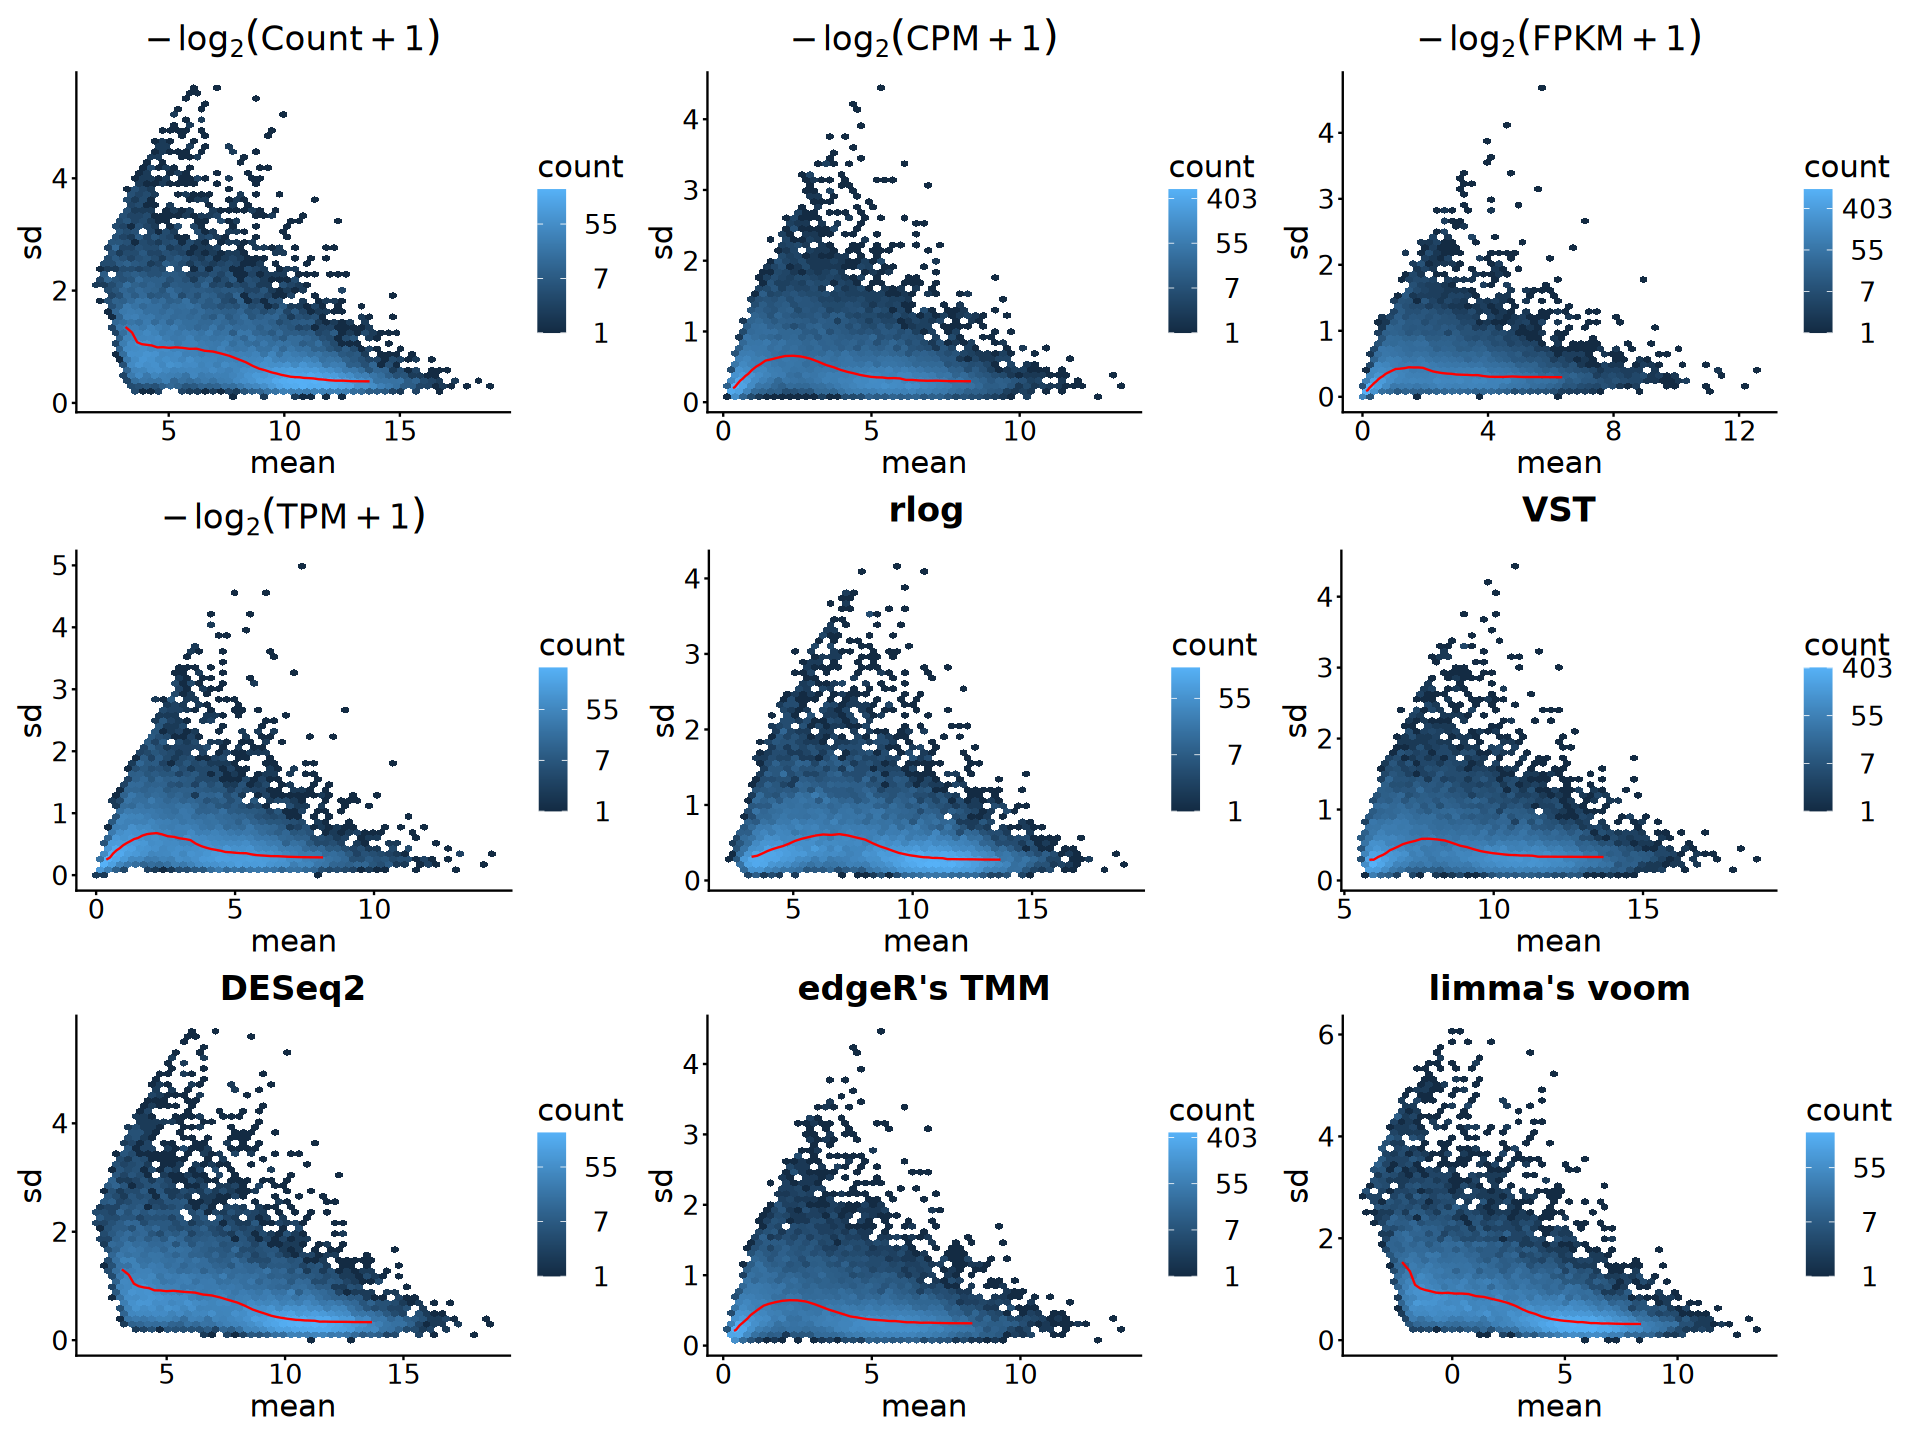

In [41]:
options(repr.plot.width = 16, repr.plot.height = 12)
(p1 + p2 + p3) / (p4 + p5 + p6) / (p7 + p8 + p9)

# 4. Exploration

In [42]:
norm_mat <- log2(tpm + 1)
norm_vs <- assay(rld)

## 1). Overview

In [43]:
plot_df <- colData(eSet) |> as.data.frame() |>
    arrange(Cell, Replicate) |> 
    rownames_to_column(var = "Sample") |>
    mutate(
        librarySize = colSums(assay(eSet))[Sample], 
        Sample = gsub("_", "\n", Sample), 
        Sample = factor(Sample, levels = Sample))

plot_df

Sample,Cell,Replicate,librarySize
<fct>,<fct>,<fct>,<dbl>
mESC rep1,mESC,rep1,36604484
mESC rep2,mESC,rep2,51698334
mESC rep3,mESC,rep3,34418618
mESC rep4,mESC,rep4,34622767
mEpiSC rep1,mEpiSC,rep1,49010808
mEpiSC rep2,mEpiSC,rep2,38729090
mEpiSC rep3,mEpiSC,rep3,33530564
mEpiSC rep4,mEpiSC,rep4,49534629


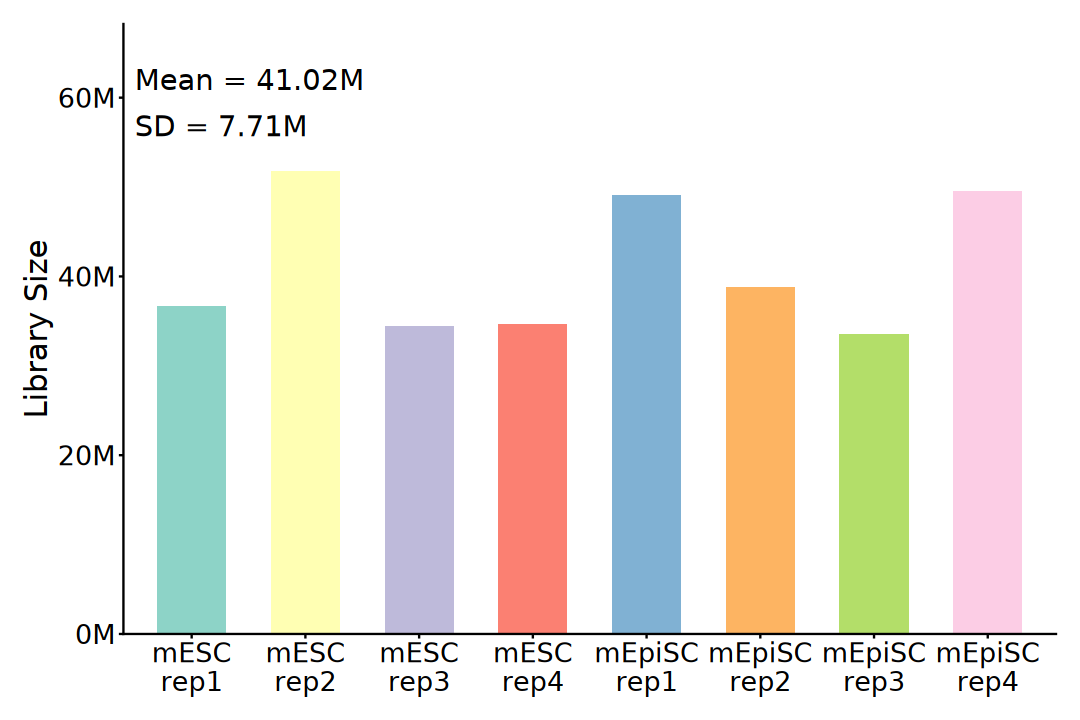

In [44]:
options(repr.plot.width = 9, repr.plot.height = 6)

ggplot(plot_df, aes(x = Sample, y = librarySize)) +
    geom_col(aes(fill = Sample), width = 0.6) +
    annotate(
        geom = "text", x = 0.5, y = max(plot_df$librarySize) * 1.2,
        label = paste0("Mean = ", round(
            mean(plot_df$librarySize) / 1e6 , 2), "M"),
        hjust = 0, size = 6) +
    annotate(
        geom = "text", x = 0.5, y = max(plot_df$librarySize) * 1.1,
        label = paste0("SD = ", round(
            sd(plot_df$librarySize) * 1e-6 , 2), "M"),
        hjust = 0, size = 6) +
    scale_y_continuous(
        labels = scales::label_number(scale = 1e-6, suffix = "M"),
        expand = expansion(mult = c(0, 0.1))) +
    scale_fill_brewer(palette = "Set3") +
    labs(x = NULL, y = "Library Size") +
    theme_classic() +
    theme(
        plot.title = element_text(size = 20, face = "bold", hjust = 0.5), 
        plot.margin = unit(c(1, 1, 1, 1), "line"),
        legend.position = "none",
        axis.title = element_text(size = 18), 
        axis.text = element_text(size = 16))

In [45]:
# remotes::install_github("psyteachr/introdataviz")
suppressPackageStartupMessages(library(introdataviz))

Warning message:
"Using the `size` aesthetic with geom_polygon was deprecated in ggplot2 3.4.0.
ℹ Please use the `linewidth` aesthetic instead."


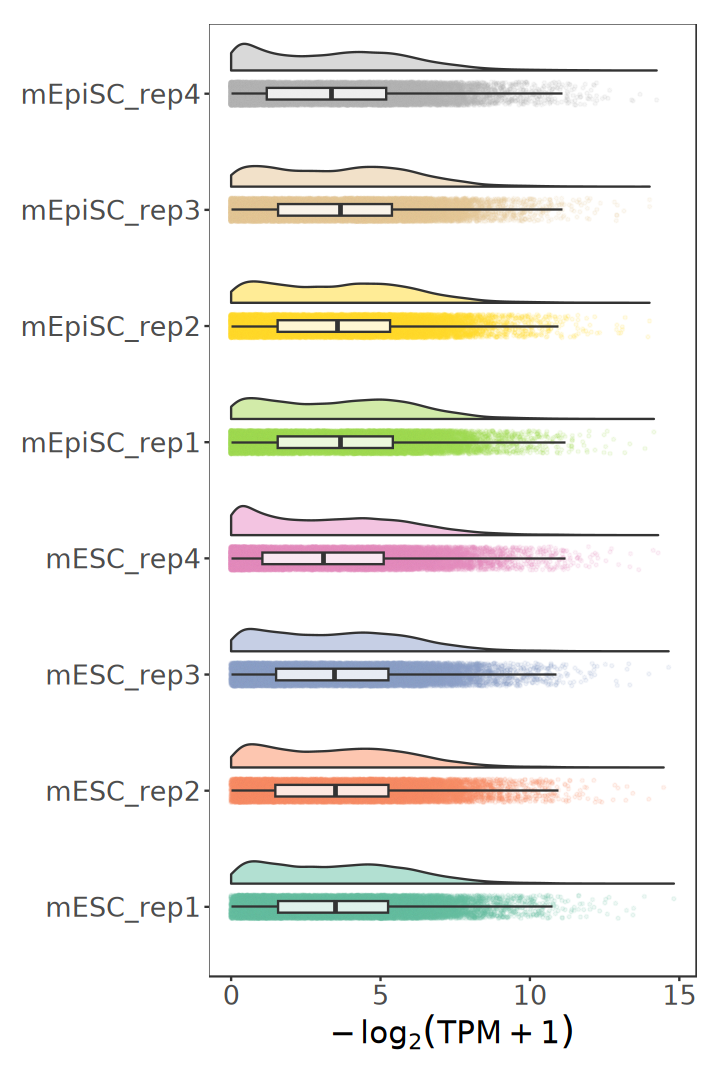

In [46]:
options(repr.plot.width = 6, repr.plot.height = 9)

norm_mat |> as.data.frame() |> 
    pivot_longer(
        cols = everything(), names_to = "Sample", 
        values_to = "Value") |>
    mutate(
        Sample = factor(Sample, levels = colnames(norm_mat))) |>
    ggplot(aes(x = Sample, y = Value)) +
        geom_flat_violin(
            aes(fill = Sample), width = 0.5, alpha = 0.5,
            position = position_nudge(x = 0.2, y = 0)) +
        geom_point(
            aes(color = Sample), size = 0.5, alpha = 0.1,
            position = position_jitter(width = 0.1)) + 
        geom_boxplot(
            width = 0.1, alpha = 0.8, outlier.shape = NA) +
        scale_fill_brewer(palette = "Set2") +
        scale_colour_brewer(palette = "Set2") +
        coord_flip() +
        labs(x = NULL, y = expression(-log[2](TPM+1))) +
        theme_test() +
        theme(
            plot.title = element_text(size = 20, face = "bold", hjust = 0.5), 
            plot.margin = unit(c(1, 1, 1, 1), "line"),
            legend.position = "none",
            axis.title = element_text(size = 18), 
            axis.text = element_text(size = 16))

## 2). PCA

In [47]:
top_var_idx <- norm_mat |>
    rowSds() |>
    # (\(m) rowSds(m) / rowMeans2(m))() |> # CV
    tibble::enframe(name = "row", value = "sd") |>
    slice_max(order_by = sd, n = 2000) |>
    pull(row)
# CV can eliminate the bias that "high abundance tends to have large variance".

In [48]:
pca_res <- norm_mat[top_var_idx, ] |> t() |> 
    prcomp(center = TRUE, scale. = FALSE)

per_var <- round(100 * pca_res$sdev^2 / sum(pca_res$sdev^2), 2)

pca_df <- merge(pca_res$x, colData(eSet), by = "row.names")

head(pca_df)

,Row.names,PC1,PC2,PC3,PC4,PC5,PC6,PC7,PC8,Cell,Replicate
,<chr>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<fct>,<fct>
1,mEpiSC_rep1,68.03645,-17.849055,-19.261669,22.971661,-5.322951,-1.9226924,-0.9397677,-5.466547e-15,mEpiSC,rep1
2,mEpiSC_rep2,57.88554,-5.378177,-2.008599,-12.861521,4.079296,5.4203533,13.5583016,-8.076873e-15,mEpiSC,rep2
3,mEpiSC_rep3,62.67976,-3.173382,-2.786343,-20.733591,-1.241767,0.9894964,-11.7603327,-2.128853e-14,mEpiSC,rep3
4,mEpiSC_rep4,45.20958,36.406153,22.858818,10.430113,6.787643,-5.0594138,-0.5592616,1.121325e-14,mEpiSC,rep4
5,mESC_rep1,-57.73078,-25.728795,12.249580,7.926145,12.379368,10.1006902,-3.5385828,-1.167122e-14,mESC,rep1
6,mESC_rep2,-41.68937,-17.489002,20.809249,-2.783361,-18.073997,-5.1986317,2.3026618,-3.125278e-14,mESC,rep2


In [49]:
p1 <- ggplot(pca_df, aes(PC1, PC2)) +
    geom_point(aes(color = Cell, shape = Replicate), size = 5) +
    scale_color_brewer(palette = "Set1") +
    labs(
        title = bquote("PCA for" ~ -log[2](TPM+1)), 
        x = paste0("PC1: ", per_var[1], "% variance"),
        y = paste0("PC2: ", per_var[2], "% variance")) +
    guides(
        color = guide_legend(override.aes = list(size = 5)), 
        shape = guide_legend(override.aes = list(size = 5))) +
    theme_test() +
    theme(
        plot.title = element_text(size = 20, face = "bold", hjust = 0.5), 
        plot.margin = unit(c(1, 1, 1, 1), "line"),
        legend.title = element_text(size = 18), 
        legend.text = element_text(size = 16),
        axis.title = element_text(size = 18), 
        axis.text = element_text(size = 16))

In [50]:
pca_res <- plotPCA(
    rld, intgroup = c("Cell", "Replicate"), 
    ntop = 2000, returnData = TRUE)

per_var <- round(100 * attr(pca_res, "percentVar"))

using ntop=2000 top features by variance



In [51]:
p2 <- ggplot(pca_res, aes(PC1, PC2)) +
    geom_point(aes(color = Cell, shape = Replicate), size = 5) +
    scale_color_brewer(palette = "Set1") +
    labs(
        title = "PCA for rlog", 
        x = paste0("PC1: ", per_var[1], "% variance"),
        y = paste0("PC2: ", per_var[2], "% variance")) +
    guides(
        color = guide_legend(override.aes = list(size = 5)), 
        shape = guide_legend(override.aes = list(size = 5))) +
    theme_test() +
    theme(
        plot.title = element_text(size = 20, face = "bold", hjust = 0.5), 
        plot.margin = unit(c(1, 1, 1, 1), "line"),
        legend.title = element_text(size = 18), 
        legend.text = element_text(size = 16),
        axis.title = element_text(size = 18), 
        axis.text = element_text(size = 16))

In [52]:
# Generalized principal component analysis (GLM-PCA)
# suppressPackageStartupMessages(library(glmpca))
gpca <- glmpca::glmpca(assay(eSet)[top_var_idx, ], L = 2)

gpca_df <- merge(gpca$factors, colData(eSet), by = "row.names")

gpca_df

DataFrame with 8 rows and 5 columns
    Row.names      dim1      dim2     Cell Replicate
  <character> <numeric> <numeric> <factor>  <factor>
1 mEpiSC_rep1  -6.57196   58.1732   mEpiSC      rep1
2 mEpiSC_rep2  53.59735   45.5491   mEpiSC      rep2
3 mEpiSC_rep3  62.18890   48.8989   mEpiSC      rep3
4 mEpiSC_rep4 147.19799   31.5052   mEpiSC      rep4
5   mESC_rep1 -59.07199  -45.5589   mESC        rep1
6   mESC_rep2 -50.51162  -40.4344   mESC        rep2
7   mESC_rep3 -72.36105  -46.4020   mESC        rep3
8   mESC_rep4 -74.46762  -51.7311   mESC        rep4

In [53]:
p3 <- ggplot(gpca_df, aes(dim1, dim2)) +
    geom_point(aes(color = Cell, shape = Replicate), size = 5) +
    scale_color_brewer(palette = "Set1") +
    labs(title = "GLM-PCA for raw count", x = "PC1", y = "PC2") +
    guides(
        color = guide_legend(override.aes = list(size = 5)), 
        shape = guide_legend(override.aes = list(size = 5))) +
    theme_test() +
    theme(
        plot.title = element_text(size = 20, face = "bold", hjust = 0.5), 
        plot.margin = unit(c(1, 1, 1, 1), "line"),
        legend.title = element_text(size = 18), 
        legend.text = element_text(size = 16),
        axis.title = element_text(size = 18), 
        axis.text = element_text(size = 16))

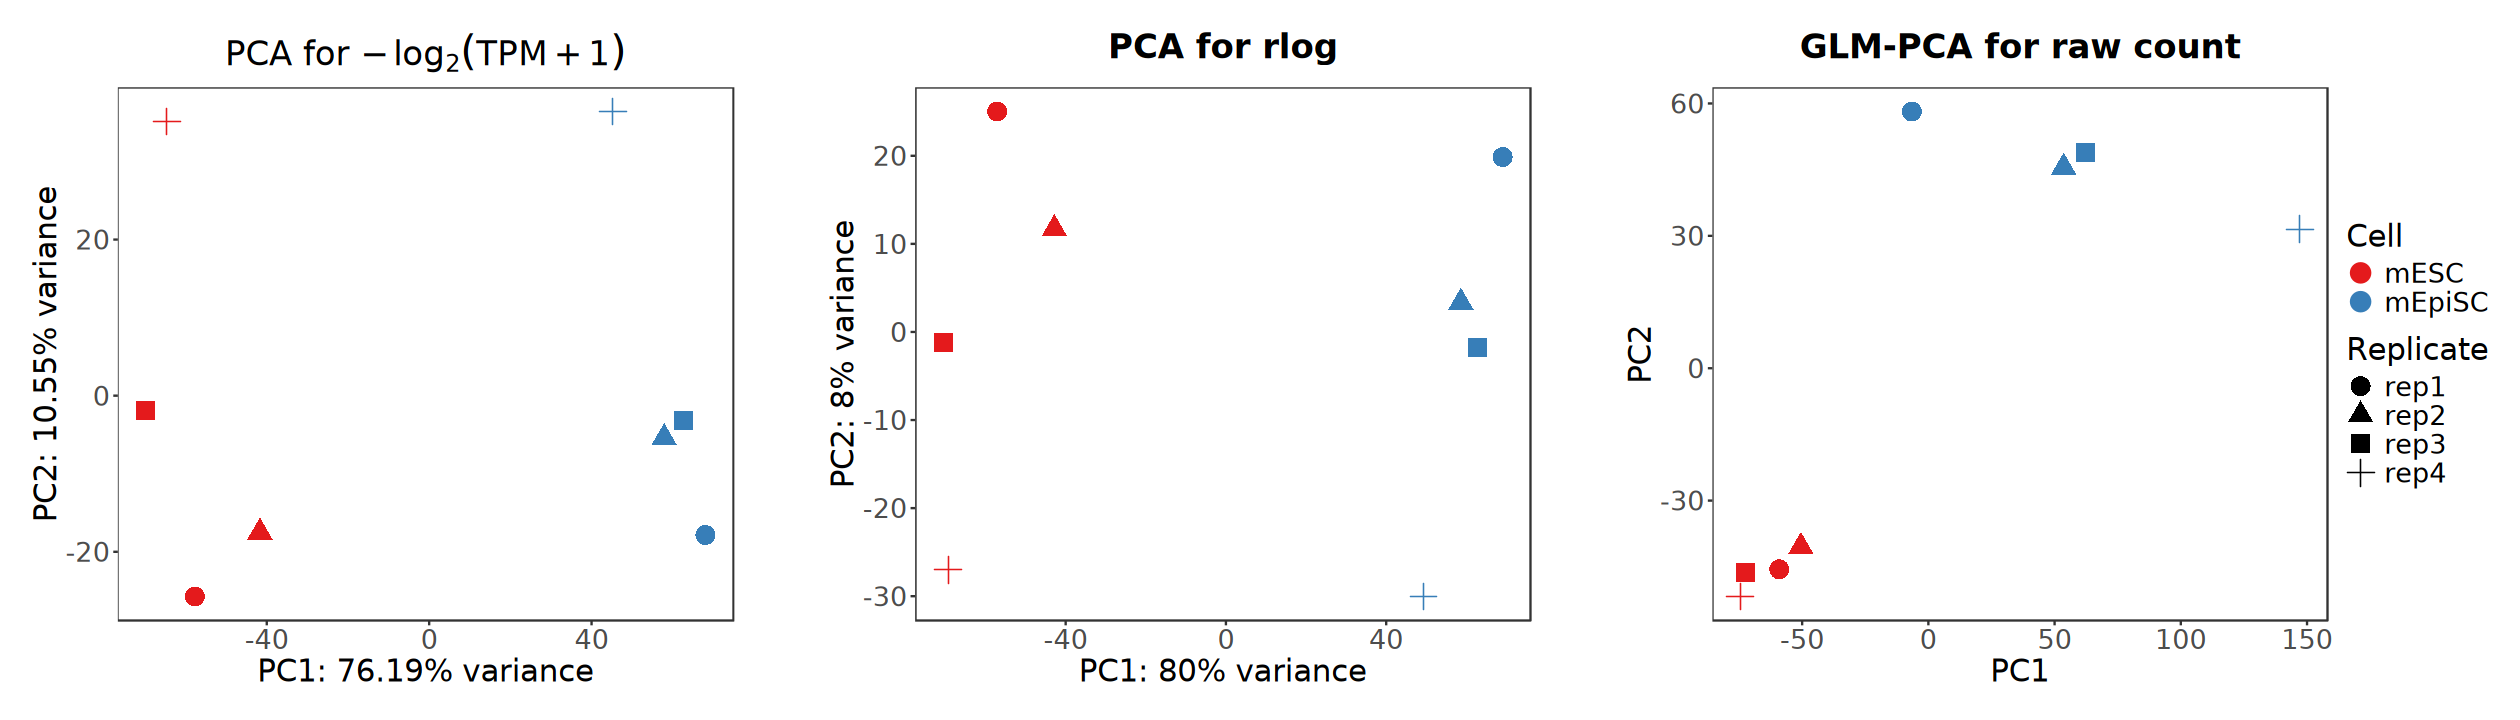

In [54]:
options(repr.plot.width = 21, repr.plot.height = 6)

p1 + plot_spacer() + p2 + plot_spacer() + p3 +
    plot_layout(nrow = 1, guides = "collect", 
                widths = c(1, 0.05, 1, 0.05, 1))

## 3). MDS

> Multidimensional scaling

In [55]:
dist_mat <- norm_vs[top_var_idx, ] |> t() |> dist()

mds <- colData(eSet) |> as.data.frame() |>
    cbind(cmdscale(as.matrix(dist_mat)))

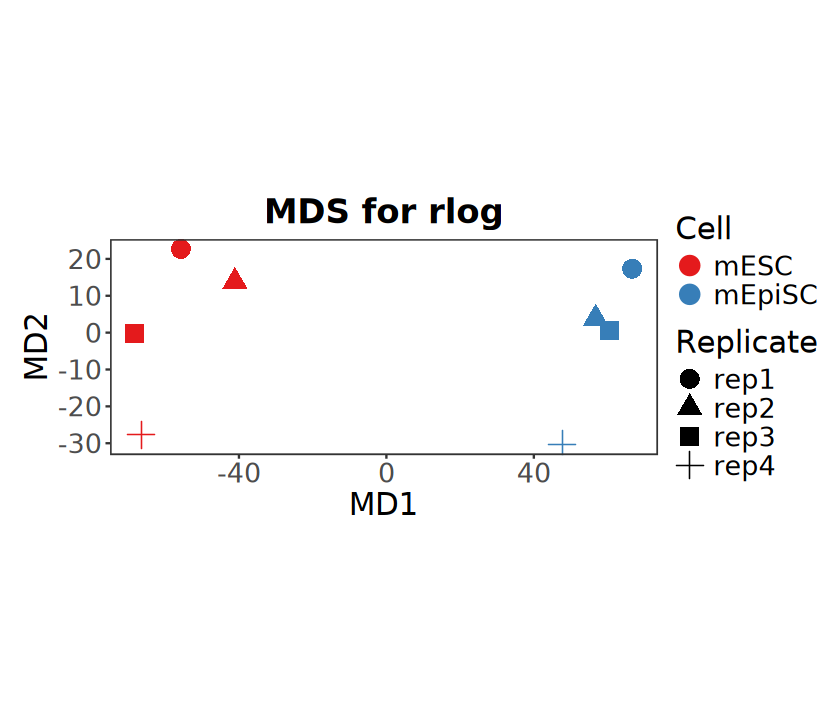

In [56]:
options(repr.plot.width = 7, repr.plot.height = 6)

ggplot(mds, aes(x = `1`, y = `2`)) +
    geom_point(aes(color = Cell, shape = Replicate), size = 5) +
    scale_color_brewer(palette = "Set1") +
    coord_fixed() + 
    # ggtitle(bquote("MDS for" ~ -log[2](TPM+1))) + 
    ggtitle("MDS for rlog") + 
    labs(x = "MD1", y = "MD2") +
    guides(
        color = guide_legend(override.aes = list(size = 5)), 
        shape = guide_legend(override.aes = list(size = 5))) +
    theme_test() +
    theme(
        plot.title = element_text(size = 20, face = "bold", hjust = 0.5), 
        plot.margin = unit(c(1, 1, 1, 1), "line"),
        legend.title = element_text(size = 18), 
        legend.text = element_text(size = 16),
        axis.title = element_text(size = 18), 
        axis.text = element_text(size = 16))

## 4). PCoA

> Principal coordinate analysis

In [57]:
# 1. Calculate Bray-Curtis distance on the transposed count matrix
dist_mat <- norm_vs[top_var_idx, ] |> t() |> 
    vegan::vegdist(method = "bray")

# 2. Run PCoA
pcoa_res <- cmdscale(dist_mat, k = 2, eig = TRUE)

# 3. Prepare data for plot
pcoa_df <- merge(pcoa_res$points, colData(eSet), by = "row.names")

head(pcoa_df)

,Row.names,V1,V2,Cell,Replicate
,<chr>,<dbl>,<dbl>,<fct>,<fct>
1,mEpiSC_rep1,0.08728511,0.020920164,mEpiSC,rep1
2,mEpiSC_rep2,0.07443376,0.008968821,mEpiSC,rep2
3,mEpiSC_rep3,0.07943004,0.002914671,mEpiSC,rep3
4,mEpiSC_rep4,0.06276873,-0.043611068,mEpiSC,rep4
5,mESC_rep1,-0.07075622,0.025994564,mESC,rep1
6,mESC_rep2,-0.05194138,0.011131747,mESC,rep2


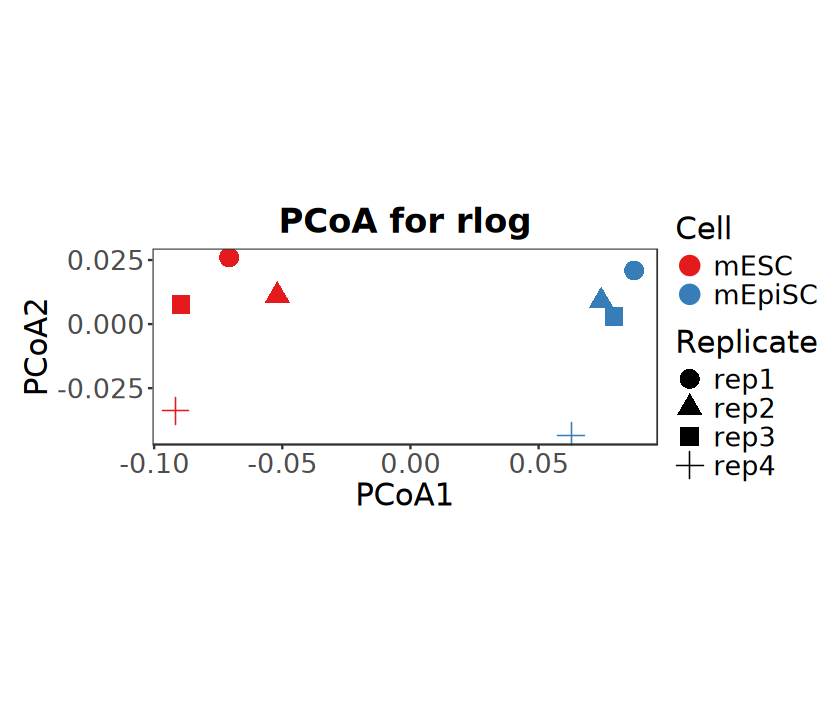

In [58]:
options(repr.plot.width = 7, repr.plot.height = 6)

ggplot(pcoa_df, aes(x = V1, y = V2)) +
    geom_point(aes(color = Cell, shape = Replicate), size = 5) +
    scale_color_brewer(palette = "Set1") +
    coord_fixed() + 
    # ggtitle(bquote("PCoA for" ~ -log[2](TPM+1))) + 
    ggtitle("PCoA for rlog") + 
    labs(x = "PCoA1", y = "PCoA2") +
    guides(
        color = guide_legend(override.aes = list(size = 5)), 
        shape = guide_legend(override.aes = list(size = 5))) +
    theme_test() +
    theme(
        plot.title = element_text(size = 20, face = "bold", hjust = 0.5), 
        plot.margin = unit(c(1, 1, 1, 1), "line"),
        legend.title = element_text(size = 18), 
        legend.text = element_text(size = 16),
        axis.title = element_text(size = 18), 
        axis.text = element_text(size = 16))

## 5). Sample Distance

In [59]:
ac <- colData(eSet) |> as.data.frame() |>
    dplyr::select(Replicate, Cell)

In [60]:
group_colors <- setNames(
    scales::brewer_pal(palette = "Set1")(nlevels(eSet$Cell)),
    levels(eSet$Cell))
replicate_colors <- setNames(
    scales::brewer_pal(palette = "Set2")(nlevels(eSet$Replicate)),
    levels(eSet$Replicate))

anno_colors <- list(
    Cell = group_colors,
    Replicate = replicate_colors)

colors <- colorRampPalette(brewer.pal(9, "Blues"))(255)

In [61]:
dist_mat <- norm_vs[top_var_idx, ] |> t() |> dist()

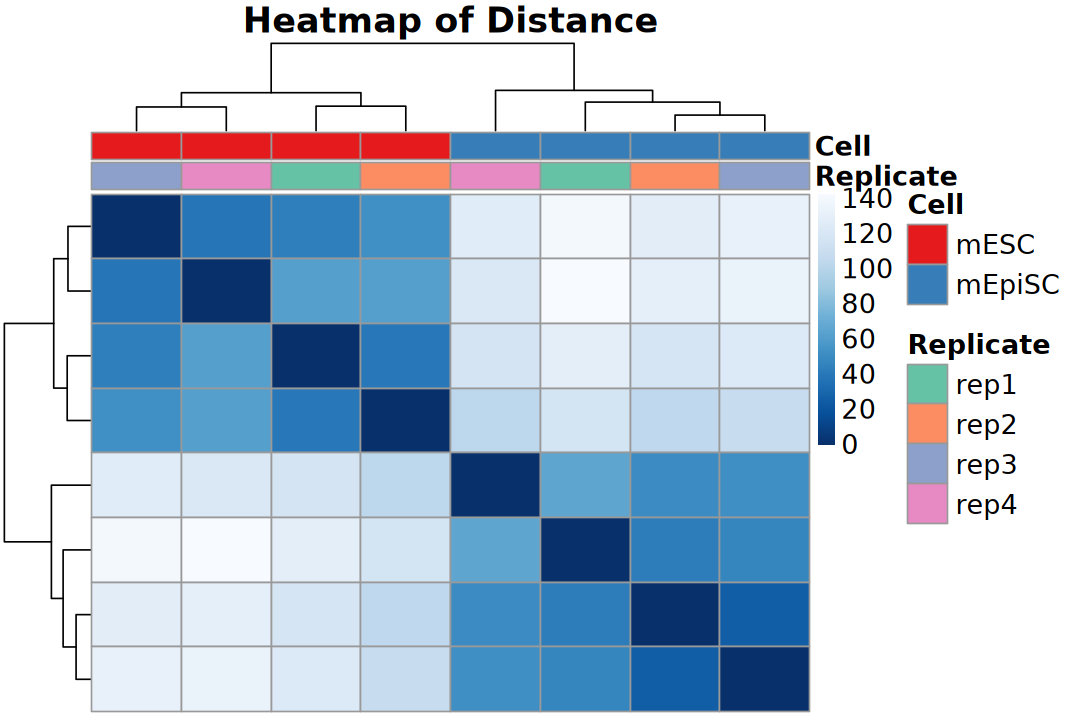

In [62]:
options(repr.plot.width = 9, repr.plot.height = 6)

pheatmap::pheatmap(
    as.matrix(dist_mat),
    clustering_distance_rows = dist_mat,
    clustering_distance_cols = dist_mat,
    annotation_col = ac, col = rev(colors), 
    annotation_colors = anno_colors,
    main = "Heatmap of Distance", fontsize = 16, 
    show_colnames = FALSE, show_rownames = FALSE)

In [63]:
# This measure of dissimilarity between counts also takes the inherent variance structure 
# of counts into consideration when calculating the distances between samples. 
# The PoissonDistance function takes the original count matrix (not normalized) with samples
# as rows instead of columns, so we need to transpose the counts in dds.
# Calculating sample distances is to use the Poisson Distance

# suppressPackageStartupMessages(library(PoiClaClu))
poisd <- assay(eSet)[top_var_idx, ] |> t() |> 
    PoiClaClu::PoissonDistance()

dist_mat <- poisd$dd |> as.matrix()

colnames(dist_mat) <- colnames(eSet)

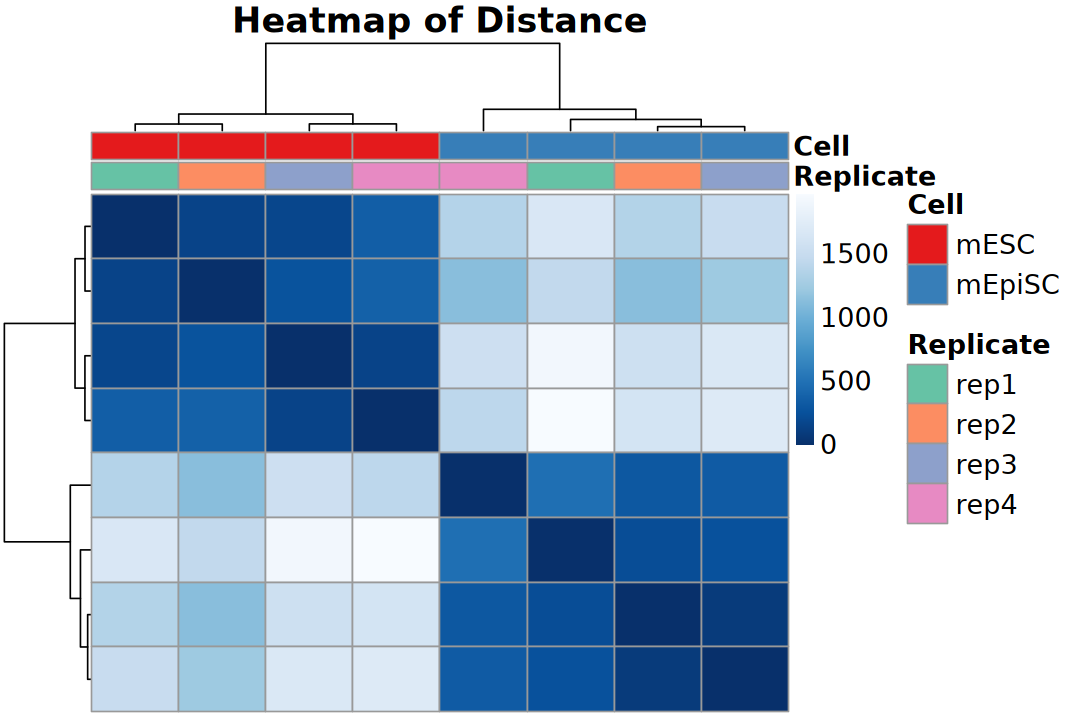

In [64]:
options(repr.plot.width = 9, repr.plot.height = 6)

pheatmap::pheatmap(
    as.matrix(dist_mat),
    clustering_distance_rows = poisd$dd,
    clustering_distance_cols = poisd$dd,
    annotation_col = ac, col = rev(colors), 
    annotation_colors = anno_colors,
    main = "Heatmap of Distance", fontsize = 16, 
    show_colnames = FALSE, show_rownames = FALSE)

## 6). Sample Correlation

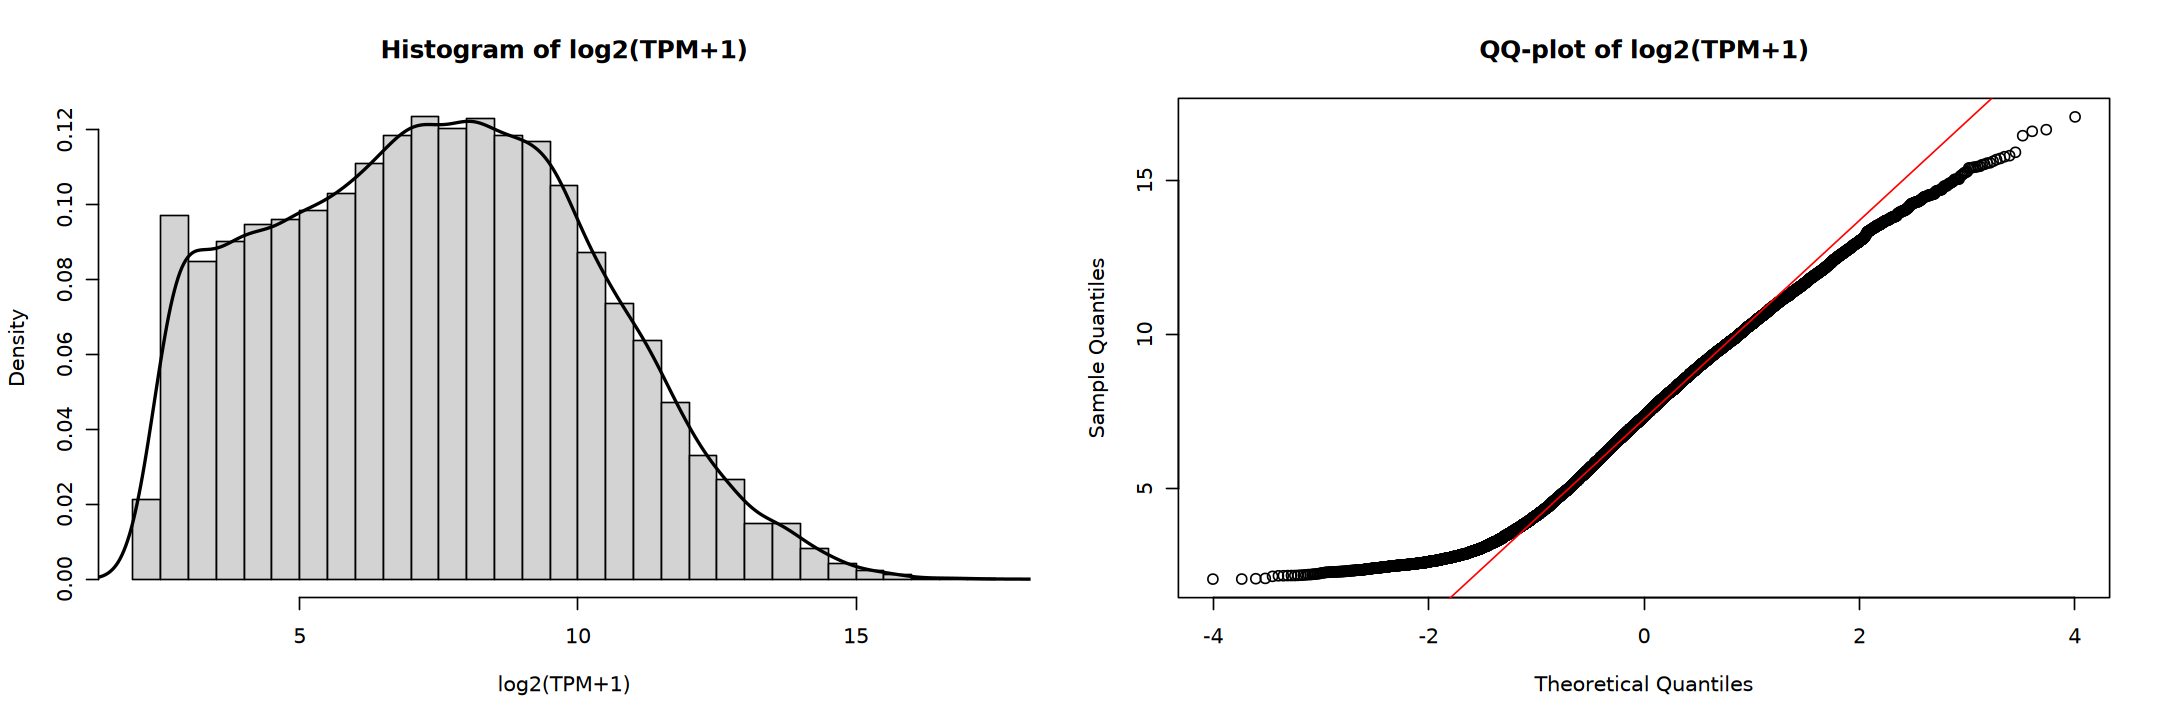

In [65]:
options(repr.plot.width = 18, repr.plot.height = 6)

par(mfrow = c(1, 2))
hist(
    norm_vs[top_var_idx, ], breaks = 50, probability = TRUE, 
    main = "Histogram of log2(TPM+1)", xlab = "log2(TPM+1)")
lines(density(norm_vs[top_var_idx, ]), lwd = 2)

qqnorm(
    norm_vs[top_var_idx, ], 
    main = "QQ-plot of log2(TPM+1)")
qqline(
    norm_vs[top_var_idx, ], col = "red")

par(mfrow = c(1, 1))

In [66]:
# cor_mat <- cor(norm_vs[top_var_idx, ], method = "pearson")
cor_mat <- cor(norm_vs[top_var_idx, ], method = "spearman")

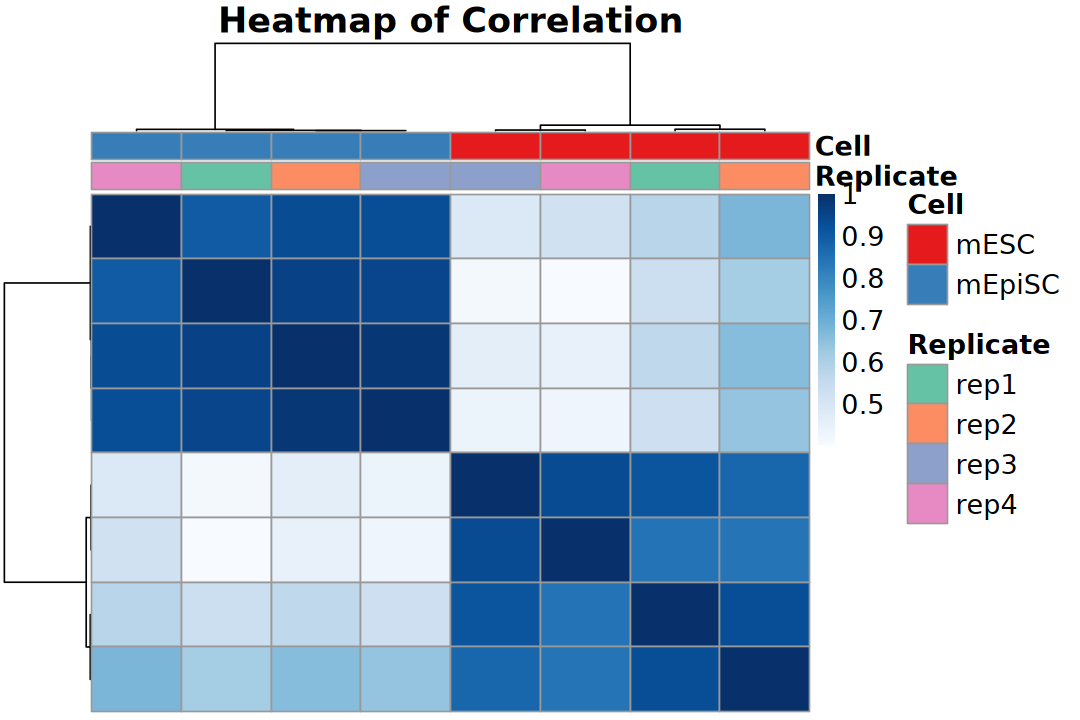

In [67]:
options(repr.plot.width = 9, repr.plot.height = 6)

pheatmap::pheatmap(
    as.matrix(cor_mat), 
    clustering_distance_rows = "correlation",
    clustering_distance_cols = "correlation",
    annotation_col = ac, col = colors, 
    annotation_colors = anno_colors,
    main = "Heatmap of Correlation", fontsize = 16, 
    show_colnames = FALSE, show_rownames = FALSE)

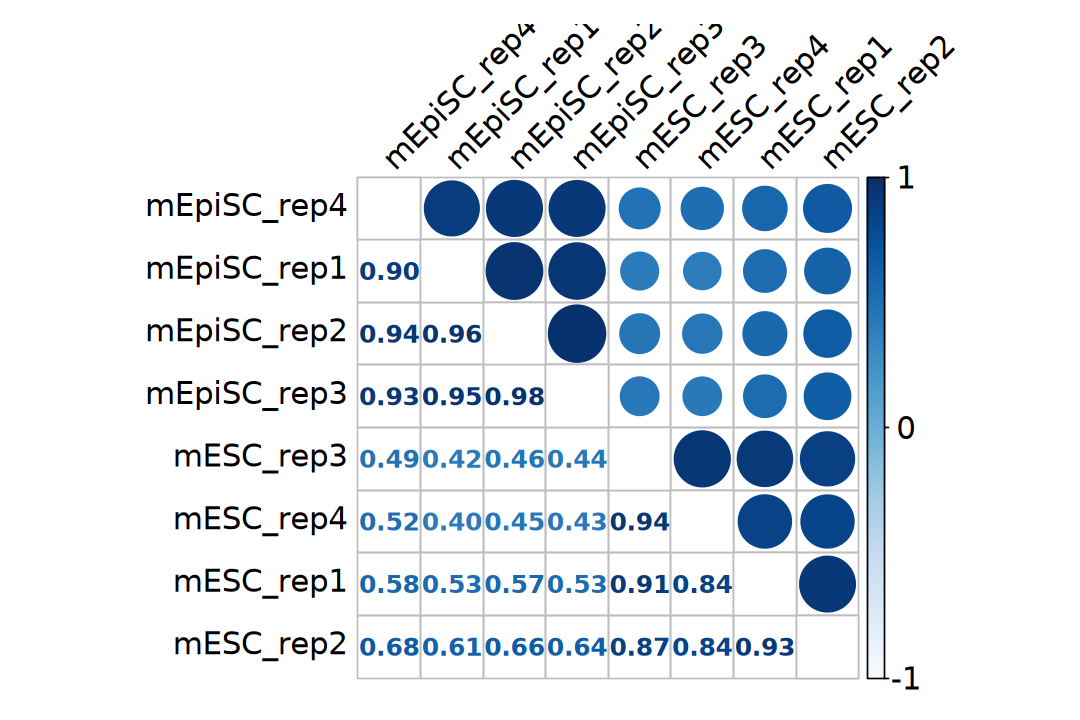

In [68]:
# suppressPackageStartupMessages(library(corrplot))
options(repr.plot.width = 9, repr.plot.height = 6)

corrplot::corrplot.mixed(
    cor_mat, order = 'hclust', upper.col = colors, 
    tl.pos = "lt", tl.cex = 1.5, tl.col = "black", tl.srt = 45, 
    number.cex = 1.2, diag = "n", col.lim = c(-1, 1), 
    lower.col = colors, rect.col = "grey50", 
    cl.cex = 1.5, cl.length = 3, mar = c(1, 0, 1, 0))

## 7). Heatmap

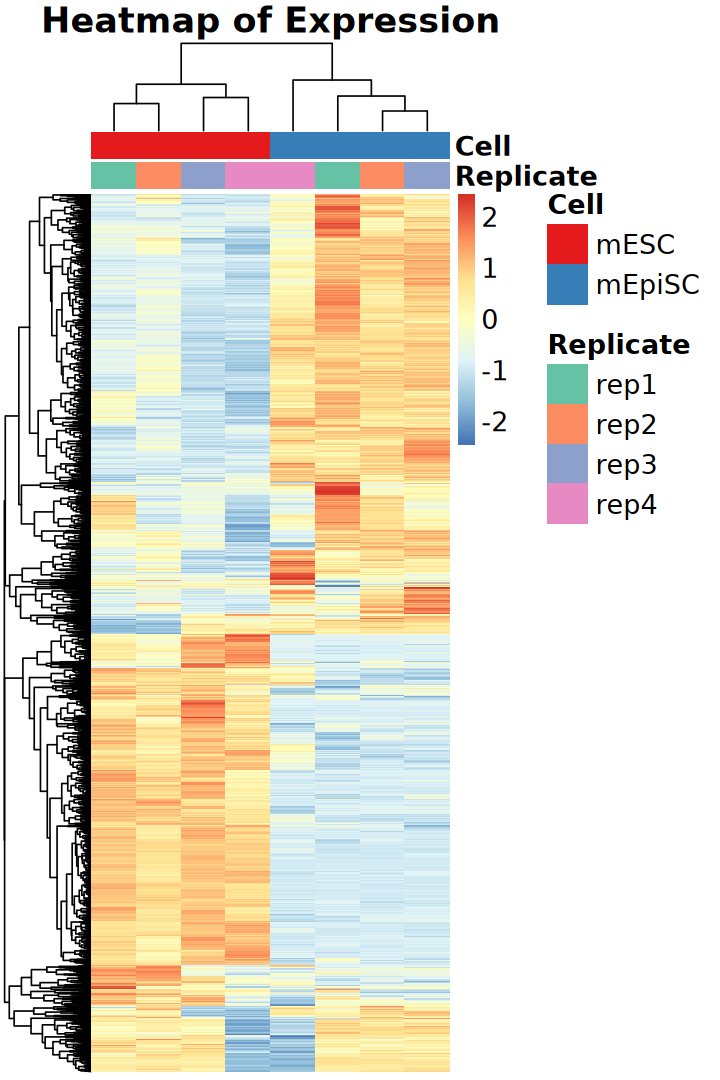

In [69]:
options(repr.plot.width = 6, repr.plot.height = 9)

pheatmap::pheatmap(
    norm_mat[top_var_idx, ], scale = "row", 
    annotation_col = ac, 
    annotation_colors = anno_colors, 
    main = "Heatmap of Expression", fontsize = 16, 
    show_colnames = FALSE, show_rownames = FALSE)

# 5. DEGs

In [70]:
logfc_cutoff <- log2(4)
p_cutoff <- 0.05

## 1). DESeq2

> median of ratios for normalization

In [71]:
design(dds)

~Cell

In [72]:
dds <- DESeq(dds)

using pre-existing size factors

estimating dispersions

gene-wise dispersion estimates

mean-dispersion relationship

final dispersion estimates

fitting model and testing



In [73]:
resultsNames(dds)

[1] "Intercept"           "Cell_mEpiSC_vs_mESC"

### a). Standard

In [74]:
res <- results(dds, lfcThreshold = logfc_cutoff, alpha = p_cutoff)
# res <- results(
#     dds, name = "Cell_mEpiSC_vs_mESC", 
#     lfcThreshold = logfc_cutoff, alpha = p_cutoff)
# res <- results(
#     dds, contrast = c("Cell", "mEpiSC", "mESC"), 
#     lfcThreshold = logfc_cutoff, alpha = p_cutoff)
summary(res)


out of 18636 with nonzero total read count
adjusted p-value < 0.05
LFC > 2.00 (up)    : 186, 1%
LFC < -2.00 (down) : 653, 3.5%
outliers [1]       : 101, 0.54%
low counts [2]     : 0, 0%
(mean count < 6)
[1] see 'cooksCutoff' argument of ?results
[2] see 'independentFiltering' argument of ?results



In [75]:
deseq2_result <- res |> as.data.frame() |> 
    rownames_to_column("gene_id") |>
    dplyr::rename(logFC = log2FoldChange) |>
    mutate(
        result = case_when(
            padj < p_cutoff & logFC >  logfc_cutoff ~ "Up",
            padj < p_cutoff & logFC < -logfc_cutoff ~ "Down",
            TRUE ~ "NS") |> 
            factor(levels = c("Up", "Down", "NS"))) |>
    left_join(
        rowData(dds) |> 
            as.data.frame() |> 
            dplyr::select(symbol, type, basepairs) |>
            rownames_to_column("gene_id"), 
        by = "gene_id") |>
    column_to_rownames("gene_id")

table(deseq2_result$result)
head(deseq2_result)


   Up  Down    NS 
  186   653 17797 

,baseMean,logFC,lfcSE,stat,pvalue,padj,result,symbol,type,basepairs
,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<fct>,<chr>,<chr>,<int>
ENSMUSG00000051951.5,180.542307,2.7798698,0.7725028,3.5985237,1.563587e-01,1.0000000000,NS,Xkr4,protein_coding,6094
ENSMUSG00000025902.13,619.595457,5.5035153,0.8154601,6.7489691,8.681039e-06,0.0003148788,Up,Sox17,protein_coding,4772
ENSMUSG00000098104.1,9.256432,-0.3348140,0.5679080,-0.5895568,9.983365e-01,1.0000000000,NS,Gm6085,processed_pseudogene,1470
ENSMUSG00000103922.1,149.073948,0.4136691,0.4675490,0.8847609,9.996543e-01,1.0000000000,NS,Gm6123,processed_pseudogene,1069
ENSMUSG00000033845.13,5082.783715,-0.9199697,0.2608899,-3.5262762,9.999826e-01,1.0000000000,NS,Mrpl15,protein_coding,8487
ENSMUSG00000102275.1,37.917062,-0.8654053,0.5547891,-1.5598817,9.795772e-01,1.0000000000,NS,Gm37144,TEC,1150


### b). LFC Shrink

> Shrinkage of effect size (LFC estimates) is useful for visualization and ranking of genes.

In [76]:
res_lfc <- lfcShrink(dds, coef = "Cell_mEpiSC_vs_mESC", type = "apeglm")
summary(res_lfc)

using 'apeglm' for LFC shrinkage. If used in published research, please cite:
    Zhu, A., Ibrahim, J.G., Love, M.I. (2018) Heavy-tailed prior distributions for
    sequence count data: removing the noise and preserving large differences.
    Bioinformatics. https://doi.org/10.1093/bioinformatics/bty895




out of 18636 with nonzero total read count
adjusted p-value < 0.1
LFC > 0 (up)       : 4016, 22%
LFC < 0 (down)     : 4101, 22%
outliers [1]       : 101, 0.54%
low counts [2]     : 0, 0%
(mean count < 6)
[1] see 'cooksCutoff' argument of ?results
[2] see 'independentFiltering' argument of ?results



In [77]:
deseq2_lfc_result <- res_lfc |> as.data.frame() |> 
    rownames_to_column("gene_id") |>
    dplyr::rename(logFC = log2FoldChange) |>
    mutate(
        result = case_when(
            padj < p_cutoff & logFC >  logfc_cutoff ~ "Up",
            padj < p_cutoff & logFC < -logfc_cutoff ~ "Down",
            TRUE ~ "NS") |> 
            factor(levels = c("Up", "Down", "NS"))) |>
    left_join(
        rowData(dds) |> 
            as.data.frame() |> 
            dplyr::select(symbol, type, basepairs) |>
            rownames_to_column("gene_id"), 
        by = "gene_id") |>
    column_to_rownames("gene_id")

table(deseq2_lfc_result$result)
head(deseq2_lfc_result)


   Up  Down    NS 
  893  1141 16602 

,baseMean,logFC,lfcSE,pvalue,padj,result,symbol,type,basepairs
,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<fct>,<chr>,<chr>,<int>
ENSMUSG00000051951.5,180.542307,2.4171565,0.8064600,3.200286e-04,1.517455e-03,Up,Xkr4,protein_coding,6094
ENSMUSG00000025902.13,619.595457,5.2737239,0.8311222,1.488993e-11,3.118473e-10,Up,Sox17,protein_coding,4772
ENSMUSG00000098104.1,9.256432,-0.2553383,0.5002902,5.554878e-01,6.900581e-01,NS,Gm6085,processed_pseudogene,1470
ENSMUSG00000103922.1,149.073948,0.3447474,0.4306024,3.762856e-01,5.294105e-01,NS,Gm6123,processed_pseudogene,1069
ENSMUSG00000033845.13,5082.783715,-0.8764312,0.2580623,4.214472e-04,1.931156e-03,NS,Mrpl15,protein_coding,8487
ENSMUSG00000102275.1,37.917062,-0.6945105,0.5174921,1.187878e-01,2.232542e-01,NS,Gm37144,TEC,1150


### Evaluate DEGs

In [78]:
suppressPackageStartupMessages(library(ggVennDiagram))

In [79]:
genes_up <- list(
    raw = deseq2_result |> filter(result == "Up") |> 
        pull(symbol) |> unique(),
    lfc = deseq2_lfc_result |> filter(result == "Up") |> 
        pull(symbol) |> unique())

genes_down <- list(
    raw = deseq2_result |> filter(result == "Down") |> 
        pull(symbol) |> unique(),
    lfc = deseq2_lfc_result |> filter(result == "Down") |> 
        pull(symbol) |> unique())

In [80]:
p1 <- ggVennDiagram(
    genes_up, set_color = "grey", set_size = 6, 
    label_color = "firebrick", label_size = 5) +
    scale_fill_distiller(palette = "Reds", direction = 1)

p2 <- ggVennDiagram(
    genes_down, set_color = "grey", set_size = 6, 
    label_color = "firebrick", label_size = 5) +
    scale_fill_distiller(palette = "Reds", direction = 1)

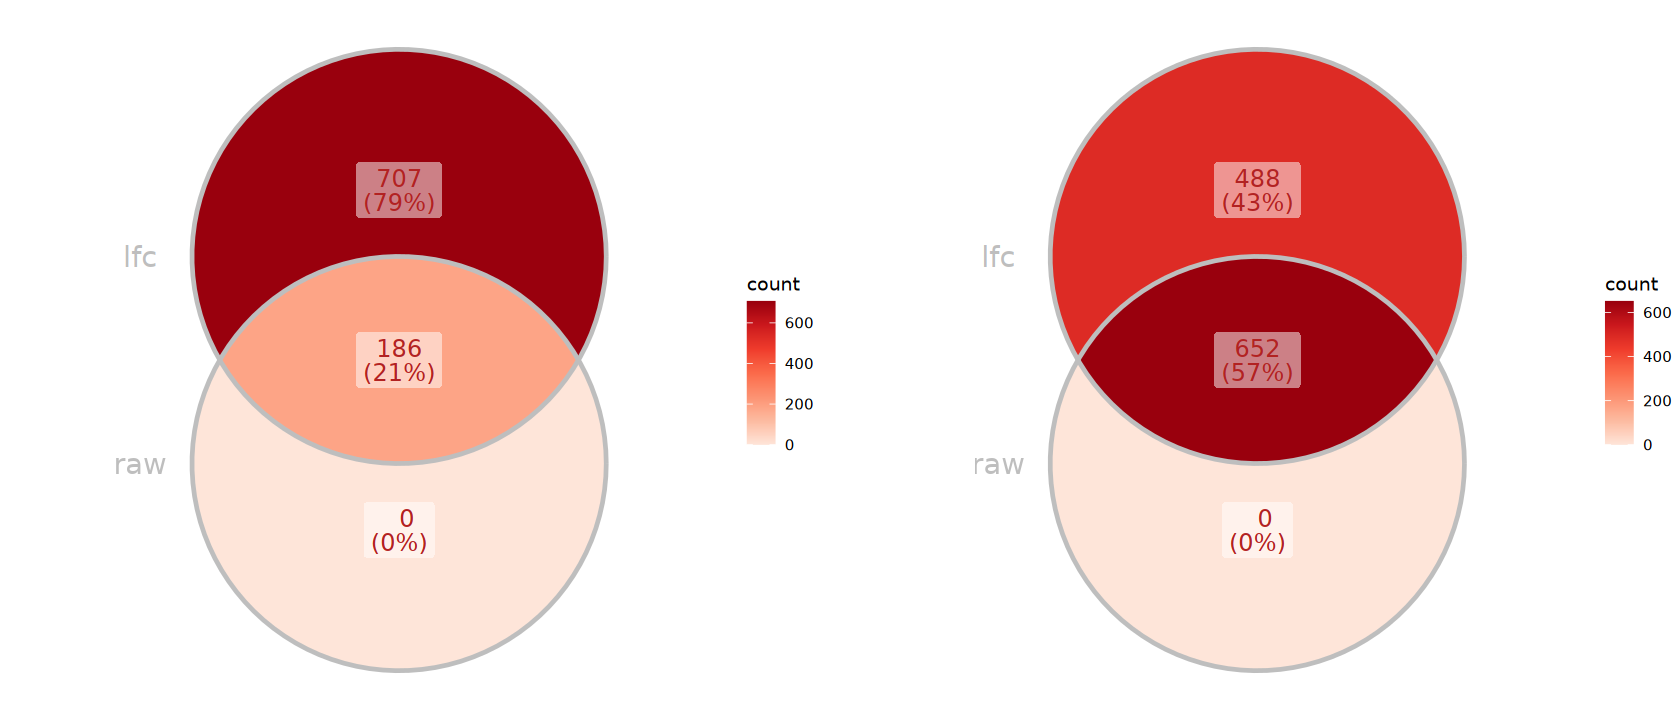

In [81]:
options(repr.plot.width = 14, repr.plot.height = 6)

p1 + plot_spacer() + p2 +
    plot_layout(nrow = 1, widths = c(1, 0.05, 1))

## 2). edgeR

> Trimmed Mean of M-values (TMM)

| Pipeline | Advantages | Application | Estimating dispersions | Fitting model | Testing methods | Notes |
| - | - | - | - | - | - | - |
| Classic pipeline (edgeR v1) | - | Single factor design | quantile-adjusted conditional maximum likelihood (qCML) method | Negative binomial model | Exact test (like Fisher’s exact test) | - |
| Negative binomial GLM framework (edgeR v2) | - | Multiple factors design | Cox-Reid profile-adjusted likelihood (CR) method | Negative binomial - Generalized linear model (NB GLM) | Likelihood ratio test (LRT) | - |
| Quasi-likelihood pipeline (edgeR v3) | Robustness and highly reliable false discovery rate (FDR) control | Multiple factors design | Cox-Reid profile-adjusted likelihood (CR) method | only the trended NB dispersions are used in fitting the QL GLM | Quasi-likelihood F-test (QLF) | - |
| Quasi-likelihood pipeline (edgeR v4) | Robustness and highly reliable false discovery rate (FDR) control | Multiple factors design | Estimates a constant NB dispersion based on the most highly expressed genes | only the trended NB dispersions are used in fitting the QL GLM | Quasi-likelihood F-test (QLF) | Default and Recommended approach in edgeR |

### a). Classic pipeline

In [82]:
dgel_classic <- estimateDisp(dgel)
# # 1. Estimate common dispersion
# dgel <- estimateCommonDisp(dgel)
# # 2. Estimate tagwise dispersions
# dgel <- estimateTagwiseDisp(dgel)

Using classic mode.



In [83]:
# exact test
et <- exactTest(dgel_classic, pair = c("mESC", "mEpiSC"))

In [84]:
edger_classic_result <- topTags(et, n = Inf) |> 
    as.data.frame() |> 
    dplyr::rename(padj = FDR, pvalue = PValue) |>
    mutate(
        result = case_when(
            padj < p_cutoff & logFC >  logfc_cutoff ~ "Up",
            padj < p_cutoff & logFC < -logfc_cutoff ~ "Down",
            TRUE ~ "NS") |> 
            factor(levels = c("Up", "Down", "NS")))

table(edger_classic_result$result)
head(edger_classic_result)


   Up  Down    NS 
 1104  1195 15951 

,symbol,type,basepairs,logFC,logCPM,pvalue,padj,result
,<chr>,<chr>,<int>,<dbl>,<dbl>,<dbl>,<dbl>,<fct>
ENSMUSG00000072419.5,Dppa2,protein_coding,2447,-8.619347,5.765700,3.783789e-104,6.905415e-100,Down
ENSMUSG00000058550.15,Dppa4,protein_coding,1662,-8.316375,6.182920,1.663643e-103,1.518074e-99,Down
ENSMUSG00000073894.1,Rbmxl2,protein_coding,1472,-10.872009,4.596308,2.728667e-101,1.659939e-97,Down
ENSMUSG00000022652.7,Morc1,protein_coding,6479,-8.671280,5.833449,2.613349e-91,1.192341e-87,Down
ENSMUSG00000090744.7,Gm6871,protein_coding,1892,-7.589999,4.392286,7.315128e-86,2.670022e-82,Down
ENSMUSG00000010342.16,Tex14,protein_coding,5014,-9.003630,4.609258,9.717642e-85,2.955783e-81,Down


### b). Negative binomial GLM framework

In [85]:
design <- model.matrix(~ group, data = dgel$samples) # include intercept
design

,(Intercept),groupmEpiSC
mESC_rep1,1,0
mESC_rep2,1,0
mESC_rep3,1,0
mESC_rep4,1,0
mEpiSC_rep1,1,1
mEpiSC_rep2,1,1
mEpiSC_rep3,1,1
mEpiSC_rep4,1,1


In [86]:
dgel_nbglm <- estimateDisp(dgel, design)
# # Estimate common dispersion
# dgel <- estimateGLMCommonDisp(dge, design)
# # Estimate trended dispersions
# dgel <- estimateGLMTrendedDisp(dgel, design)
# # Estimate tagwise dispersions
# dgel <- estimateGLMTagwiseDisp(dgel, design)

In [87]:
# likelihood ratio test
fit <- glmFit(dgel_nbglm, design)
lrt <- glmLRT(fit, coef = 2)

In [88]:
edger_glm_lrt_result <- topTags(lrt, n = Inf) |>
    as.data.frame() |> 
    dplyr::rename(padj = FDR, pvalue = PValue) |>
    mutate(
        result = case_when(
            padj < p_cutoff & logFC >  logfc_cutoff ~ "Up",
            padj < p_cutoff & logFC < -logfc_cutoff ~ "Down",
            TRUE ~ "NS") |> 
            factor(levels = c("Up", "Down", "NS")))

table(edger_glm_lrt_result$result)
head(edger_glm_lrt_result)


   Up  Down    NS 
 1112  1204 15934 

,symbol,type,basepairs,logFC,logCPM,LR,pvalue,padj,result
,<chr>,<chr>,<int>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<fct>
ENSMUSG00000072419.5,Dppa2,protein_coding,2447,-8.619331,5.765699,473.9183,4.499179e-105,8.211002e-101,Down
ENSMUSG00000073894.1,Rbmxl2,protein_coding,1472,-10.872010,4.596307,463.1339,9.997805e-103,7.841198e-99,Down
ENSMUSG00000058550.15,Dppa4,protein_coding,1662,-8.316141,6.182919,462.6269,1.288964e-102,7.841198e-99,Down
ENSMUSG00000022652.7,Morc1,protein_coding,6479,-8.671301,5.833448,416.9417,1.130129e-92,5.156214e-89,Down
ENSMUSG00000090744.7,Gm6871,protein_coding,1892,-7.590008,4.392285,390.0138,8.220027e-87,3.000310e-83,Down
ENSMUSG00000010342.16,Tex14,protein_coding,5014,-9.003634,4.609257,386.8338,4.047343e-86,1.231067e-82,Down


### c). Quasi-likelihood pipeline (edgeR v3)

In [89]:
design <- model.matrix(~ group, data = dgel$samples) # include intercept

In [90]:
dgel_nbglm <- estimateDisp(dgel, design)

In [91]:
# quasi-likelihood (QL) F-test
fit <- glmQLFit(dgel_nbglm, design)
qlf <- glmQLFTest(fit, coef = 2)

In [92]:
edger_glm_qlf_result <- topTags(qlf, n = Inf) |>
    as.data.frame() |> 
    dplyr::rename(padj = FDR, pvalue = PValue) |>
    mutate(
        result = case_when(
            padj < p_cutoff & logFC >  logfc_cutoff ~ "Up",
            padj < p_cutoff & logFC < -logfc_cutoff ~ "Down",
            TRUE ~ "NS") |> 
            factor(levels = c("Up", "Down", "NS")))

table(edger_glm_qlf_result$result)
head(edger_glm_qlf_result)


   Up  Down    NS 
 1067  1185 15998 

,symbol,type,basepairs,logFC,logCPM,F,pvalue,padj,result
,<chr>,<chr>,<int>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<fct>
ENSMUSG00000074832.11,2410141K09Rik,protein_coding,3325,-10.075363,5.026667,637.3182,2.037434e-13,2.511978e-09,Down
ENSMUSG00000091490.3,Triml2,protein_coding,3693,-11.089593,6.169485,658.4765,2.752852e-13,2.511978e-09,Down
ENSMUSG00000096966.2,Gm18336,protein_coding,2298,-9.839414,4.107065,485.5730,1.052743e-12,5.865390e-09,Down
ENSMUSG00000036743.4,Psma8,protein_coding,2494,-9.731180,3.999692,471.1670,1.304712e-12,5.865390e-09,Down
ENSMUSG00000060499.7,Rpl10l,protein_coding,1023,-10.610269,5.416470,449.5457,1.606956e-12,5.865390e-09,Down
ENSMUSG00000010342.16,Tex14,protein_coding,5014,-9.003579,4.609257,713.8577,2.057682e-12,6.258782e-09,Down


### d). Quasi-likelihood pipeline (edgeR v4)

In [93]:
design <- model.matrix(~ group, data = dgel$samples) # include intercept

In [94]:
# quasi-likelihood (QL) F-test
fit <- glmQLFit(dgel, design)
qlf <- glmQLFTest(fit, coef = 2)

In [95]:
edger_glm_qlf_v4_result <- topTags(qlf, n = Inf) |>
    as.data.frame() |> 
    dplyr::rename(padj = FDR, pvalue = PValue) |>
    mutate(
        result = case_when(
            padj < p_cutoff & logFC >  logfc_cutoff ~ "Up",
            padj < p_cutoff & logFC < -logfc_cutoff ~ "Down",
            TRUE ~ "NS") |> 
            factor(levels = c("Up", "Down", "NS")))

table(edger_glm_qlf_v4_result$result)
head(edger_glm_qlf_v4_result)


   Up  Down    NS 
 1068  1184 15998 

,symbol,type,basepairs,logFC,logCPM,F,pvalue,padj,result
,<chr>,<chr>,<int>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<fct>
ENSMUSG00000074832.11,2410141K09Rik,protein_coding,3325,-10.075136,5.025079,634.5871,1.559255e-13,1.760159e-09,Down
ENSMUSG00000091490.3,Triml2,protein_coding,3693,-11.089328,6.168585,657.5386,1.928941e-13,1.760159e-09,Down
ENSMUSG00000010342.16,Tex14,protein_coding,5014,-9.003457,4.607091,715.7420,1.320362e-12,6.295734e-09,Down
ENSMUSG00000060499.7,Rpl10l,protein_coding,1023,-10.609862,5.414755,443.4172,1.488101e-12,6.295734e-09,Down
ENSMUSG00000096966.2,Gm18336,protein_coding,2298,-9.839181,4.103415,468.2689,1.794736e-12,6.295734e-09,Down
ENSMUSG00000036743.4,Psma8,protein_coding,2494,-9.731003,3.995900,458.8103,2.069830e-12,6.295734e-09,Down


### Evaluate DEGs

In [96]:
suppressPackageStartupMessages(library(ggVennDiagram))

In [97]:
genes_up <- list(
    classic = edger_classic_result |> filter(result == "Up") |> 
        pull(symbol) |> unique(),
    glm_lrt = edger_glm_lrt_result |> filter(result == "Up") |> 
        pull(symbol) |> unique(),
    glm_qlf = edger_glm_qlf_result |> filter(result == "Up") |> 
        pull(symbol) |> unique(),
    glm_v4 = edger_glm_qlf_v4_result |> filter(result == "Up") |> 
        pull(symbol) |> unique())

genes_down <- list(
    classic = edger_classic_result |> filter(result == "Down") |> 
        pull(symbol) |> unique(),
    glm_lrt = edger_glm_lrt_result |> filter(result == "Down") |> 
        pull(symbol) |> unique(),
    glm_qlf = edger_glm_qlf_result |> filter(result == "Down") |> 
        pull(symbol) |> unique(),
    glm_v4 = edger_glm_qlf_v4_result |> filter(result == "Down") |> 
        pull(symbol) |> unique())

In [98]:
p1 <- ggVennDiagram(
    genes_up, set_color = "grey", set_size = 6, 
    label_color = "firebrick", label_size = 5) +
    scale_fill_distiller(palette = "Reds", direction = 1)

p2 <- ggVennDiagram(
    genes_down, set_color = "grey", set_size = 6, 
    label_color = "firebrick", label_size = 5) +
    scale_fill_distiller(palette = "Reds", direction = 1)

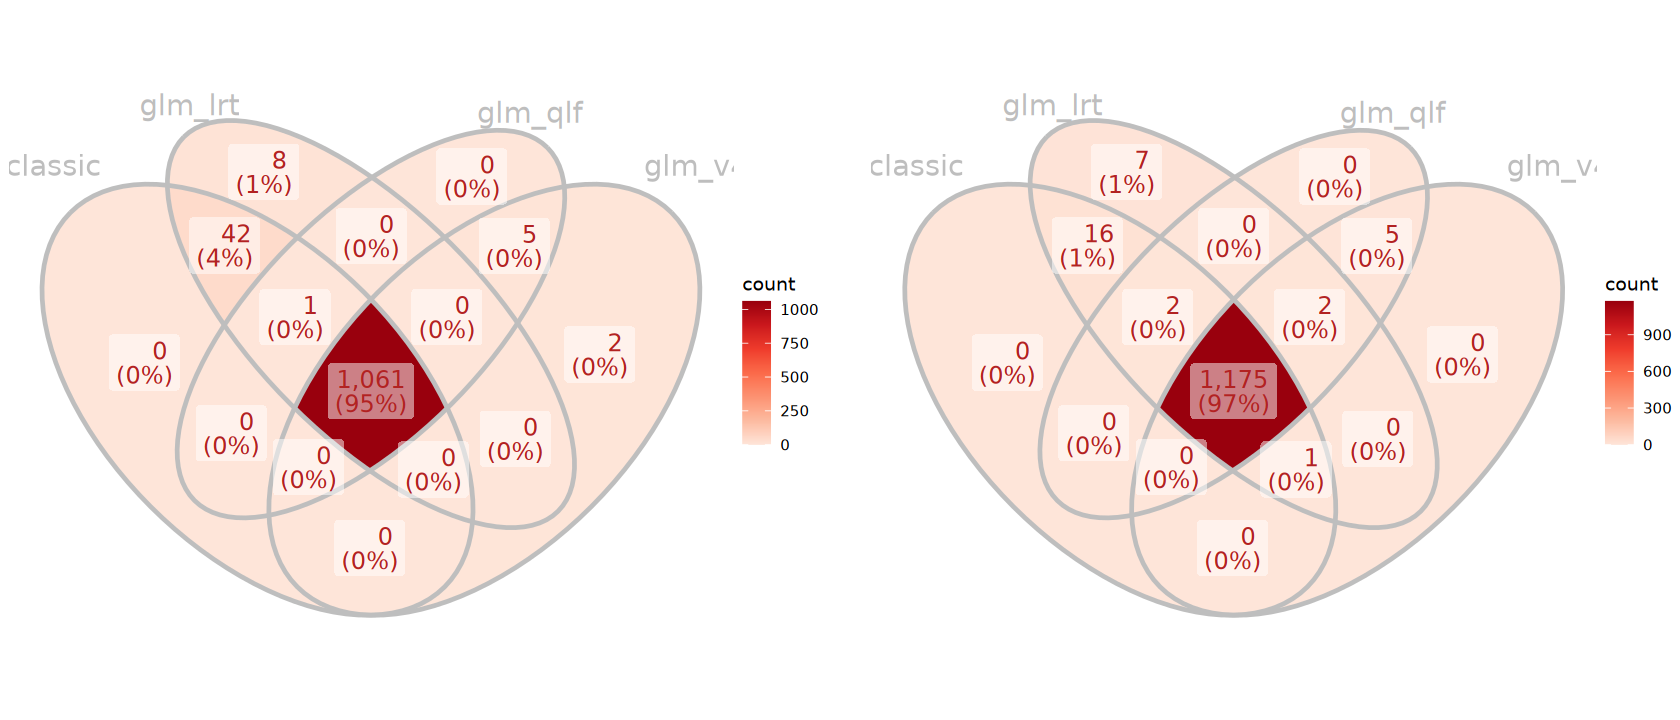

In [99]:
options(repr.plot.width = 14, repr.plot.height = 6)

p1 + plot_spacer() + p2 +
    plot_layout(nrow = 1, widths = c(1, 0.05, 1))

## 3). limma

> In the limma approach to RNA-seq, read counts are converted to log2-counts-per-million (logCPM), and the mean-variance relationship is modeled either with precision weights or with an empirical Bayes prior trend. The precision weights approach is called “voom,” and the prior trend approach is called “limma-trend.”

### a). limma-trend

> If the sequencing depth is fairly consistent across the RNA samples, then the simplest and most reliable method for differential expression is to use limma-trend. This method usually works well if the ratio of the largest library size to the smallest is no more than about 3-fold. Few literature uses.

In [100]:
design <- model.matrix(~ group, data = dgel$samples)
design

,(Intercept),groupmEpiSC
mESC_rep1,1,0
mESC_rep2,1,0
mESC_rep3,1,0
mESC_rep4,1,0
mEpiSC_rep1,1,1
mEpiSC_rep2,1,1
mEpiSC_rep3,1,1
mEpiSC_rep4,1,1


In [101]:
logCPM <- cpm(dgel, normalized.lib.sizes = TRUE, log = TRUE)
head(logCPM)

,mESC_rep1,mESC_rep2,mESC_rep3,mESC_rep4,mEpiSC_rep1,mEpiSC_rep2,mEpiSC_rep3,mEpiSC_rep4
ENSMUSG00000051951.5,-0.3075420,1.7639532,-1.9847254,-1.7033546,3.37496503,3.0914451,3.3487450,1.686797
ENSMUSG00000025902.13,-2.0678823,0.9372426,-1.8272461,-1.3076782,6.19268600,3.4563768,4.9503464,3.003008
ENSMUSG00000103922.1,0.7448834,0.5953548,2.4122963,2.0975902,2.25816154,2.4979940,1.9804258,1.649411
ENSMUSG00000033845.13,7.0891704,7.0126102,7.2876650,7.8591426,6.33031629,6.4846970,6.2769663,6.783454
ENSMUSG00000102275.1,0.7908368,0.1211270,0.7981386,-0.9974928,0.03358924,-0.2068626,-0.4609933,-1.660484
ENSMUSG00000025903.14,6.7194643,6.6126503,6.4840059,6.5347560,6.48924267,6.0327257,5.9002489,5.810265


In [102]:
# Linear Model for Series of Arrays
fit <- lmFit(logCPM, design)
# Empirical Bayes Statistics for Differential Expression
efit <- eBayes(fit, trend = TRUE)

In [ ]:
limma_trend_result <- topTable(efit, coef = 2, number = Inf) |> 
# limma_trend_result <- topTable(efit, coef = "groupmEpiSC", number = Inf) |> 
    as.data.frame() |> 
    rownames_to_column("gene_id") |>
    dplyr::rename(padj = adj.P.Val, pvalue = P.Value) |>
    mutate(
        result = case_when(
            padj < p_cutoff & logFC >  logfc_cutoff ~ "Up",
            padj < p_cutoff & logFC < -logfc_cutoff ~ "Down",
            TRUE ~ "NS") |> 
            factor(levels = c("Up", "Down", "NS"))) |>
    left_join(
        dgel$genes |> rownames_to_column("gene_id"), 
        by = "gene_id") |>
    column_to_rownames("gene_id")

table(limma_trend_result$result)
head(limma_trend_result)


   Up  Down    NS 
 1048  1159 16043 

,logFC,AveExpr,t,pvalue,padj,B,result,symbol,type,basepairs
,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<fct>,<chr>,<chr>,<int>
ENSMUSG00000072419.5,-8.400203,2.5220760,-29.51729,7.620938e-11,7.476065e-07,14.84548,Down,Dppa2,protein_coding,2447
ENSMUSG00000091490.3,-10.275031,1.9304710,-28.25130,1.162016e-10,7.476065e-07,14.52947,Down,Triml2,protein_coding,3693
ENSMUSG00000022652.7,-8.396055,2.5681364,-28.08730,1.228942e-10,7.476065e-07,14.48686,Down,Morc1,protein_coding,6479
ENSMUSG00000028109.14,-9.830282,1.1187199,-25.92791,2.650613e-10,7.991939e-07,13.88716,Down,Hormad1,protein_coding,1729
ENSMUSG00000073894.1,-9.516817,0.8168085,-25.79350,2.786194e-10,7.991939e-07,13.84730,Down,Rbmxl2,protein_coding,1472
ENSMUSG00000058550.15,-8.237538,3.0428682,-25.36979,3.266133e-10,7.991939e-07,13.71957,Down,Dppa4,protein_coding,1662


### b). limma-voom

> When library sizes vary significantly between samples, the voom approach is technically more powerful than limma-trend.

In [104]:
design <- model.matrix(~ group, data = dgel$samples)

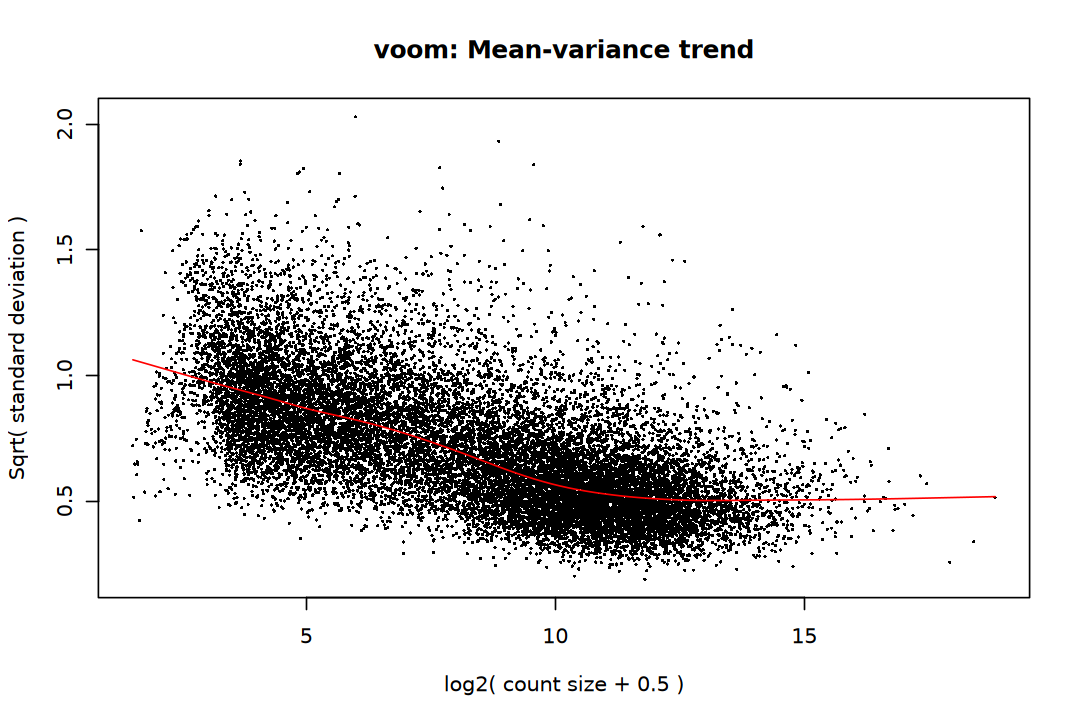

In [105]:
options(repr.plot.width = 9, repr.plot.height = 6)

norm_v <- voom(dgel, design, plot = TRUE)

In [106]:
# Linear Model for Series of Arrays
fit <- lmFit(norm_v, design)
# Empirical Bayes Statistics for Differential Expression
efit <- eBayes(fit)

In [ ]:
limma_voom_result <- topTable(efit, coef = 2, number = Inf) |> 
# limma_voom_result <- topTable(efit, coef = "groupmEpiSC", number = Inf) |> 
    as.data.frame() |> 
    dplyr::rename(padj = adj.P.Val, pvalue = P.Value) |>
    mutate(
        result = case_when(
            padj < p_cutoff & logFC >  logfc_cutoff ~ "Up",
            padj < p_cutoff & logFC < -logfc_cutoff ~ "Down",
            TRUE ~ "NS") |> 
            factor(levels = c("Up", "Down", "NS")))

table(limma_voom_result$result)
head(limma_voom_result)


   Up  Down    NS 
 1035  1213 16002 

,symbol,type,basepairs,logFC,AveExpr,t,pvalue,padj,B,result
,<chr>,<chr>,<int>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<fct>
ENSMUSG00000031714.9,Gab1,protein_coding,5082,-3.653855,6.8742794,-19.52789,4.652287e-09,1.640757e-05,11.57031,Down
ENSMUSG00000058550.15,Dppa4,protein_coding,1662,-8.384577,2.9779818,-20.76925,2.604795e-09,1.198138e-05,11.27111,Down
ENSMUSG00000085860.1,2410003L11Rik,lncRNA,1144,-7.843544,0.8222365,-22.16372,1.410926e-09,1.198138e-05,10.95920,Down
ENSMUSG00000090744.7,Gm6871,protein_coding,1892,-7.593326,1.5775691,-20.75134,2.626056e-09,1.198138e-05,10.92869,Down
ENSMUSG00000062353.6,Gm15772,processed_pseudogene,438,-5.025078,5.9411885,-17.94971,1.025538e-08,1.640757e-05,10.78398,Down
ENSMUSG00000043439.5,Epop,protein_coding,2314,-3.177048,6.3663320,-17.67561,1.184350e-08,1.652075e-05,10.62804,Down


### c). voomLmFit

> In recent versions of limma and edgeR, we now recommend voomLmFit as the preferred interface for RNA-seq analyses, replacing voom, lmFit, and voomWithQualityWeights. voomLmFit ensures unbiased estimation of the residual variances, even for genes that have no counts at all in some experimental conditions.
> - voomLmFit = voom transform + lmFit with weights

In [108]:
design <- model.matrix(~ group, data = dgel$samples)

In [109]:
# sample.weights = TRUE: estimating the empirical sample quality weights
fit <- voomLmFit(dgel, design = design, sample.weights = TRUE)
efit <- eBayes(fit)

First sample weights (min/max) 0.2196238/3.4277691

Final sample weights (min/max) 0.2186537/3.4340107



In [ ]:
limma_voomLmFit_result <- topTable(efit, coef = 2, number = Inf) |> 
# limma_voomLmFit_result <- topTable(efit, coef = "groupmEpiSC", number = Inf) |> 
    as.data.frame() |> 
    dplyr::rename(padj = adj.P.Val, pvalue = P.Value) |>
    mutate(
        result = case_when(
            padj < p_cutoff & logFC >  logfc_cutoff ~ "Up",
            padj < p_cutoff & logFC < -logfc_cutoff ~ "Down",
            TRUE ~ "NS") |> 
            factor(levels = c("Up", "Down", "NS")))

table(limma_voomLmFit_result$result)
head(limma_voomLmFit_result)


   Up  Down    NS 
 1094  1307 15849 

,symbol,type,basepairs,logFC,AveExpr,t,pvalue,padj,B,result
,<chr>,<chr>,<int>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<fct>
ENSMUSG00000028164.15,Manba,protein_coding,6971,-4.059765,5.352156,-25.66169,2.534939e-10,7.478371e-07,14.43593,Down
ENSMUSG00000031714.9,Gab1,protein_coding,5082,-3.651669,6.874279,-24.83461,3.480417e-10,7.478371e-07,14.12208,Down
ENSMUSG00000058126.7,Tpm3-rs7,protein_coding,2147,4.548234,5.134748,24.73075,3.624370e-10,7.478371e-07,14.04976,Up
ENSMUSG00000043439.5,Epop,protein_coding,2314,-3.037269,6.366332,-24.50383,3.962227e-10,7.478371e-07,13.99413,Down
ENSMUSG00000072419.5,Dppa2,protein_coding,2447,-8.560875,2.429553,-27.33354,1.375370e-10,7.478371e-07,13.93334,Down
ENSMUSG00000058550.15,Dppa4,protein_coding,1662,-8.252089,2.977982,-26.19628,2.076186e-10,7.478371e-07,13.93245,Down


### Evaluate DEGs

In [111]:
suppressPackageStartupMessages(library(ggVennDiagram))

In [ ]:
genes_up <- list(
    trend = limma_trend_result |> filter(result == "Up") |> 
        pull(symbol) |> unique(),
    voom = limma_voom_result |> filter(result == "Up") |> 
        pull(symbol) |> unique(),
    voom_wight = limma_voomLmFit_result |> filter(result == "Up") |> 
        pull(symbol) |> unique())

genes_down <- list(
    trend = limma_trend_result |> filter(result == "Down") |> 
        pull(symbol) |> unique(),
    voom = limma_voom_result |> filter(result == "Down") |> 
        pull(symbol) |> unique(),
    voom_wight = limma_voomLmFit_result |> filter(result == "Down") |> 
        pull(symbol) |> unique())

In [113]:
p1 <- ggVennDiagram(
    genes_up, set_color = "grey", set_size = 6, 
    label_color = "firebrick", label_size = 5) +
    scale_fill_distiller(palette = "Reds", direction = 1)

p2 <- ggVennDiagram(
    genes_down, set_color = "grey", set_size = 6, 
    label_color = "firebrick", label_size = 5) +
    scale_fill_distiller(palette = "Reds", direction = 1)

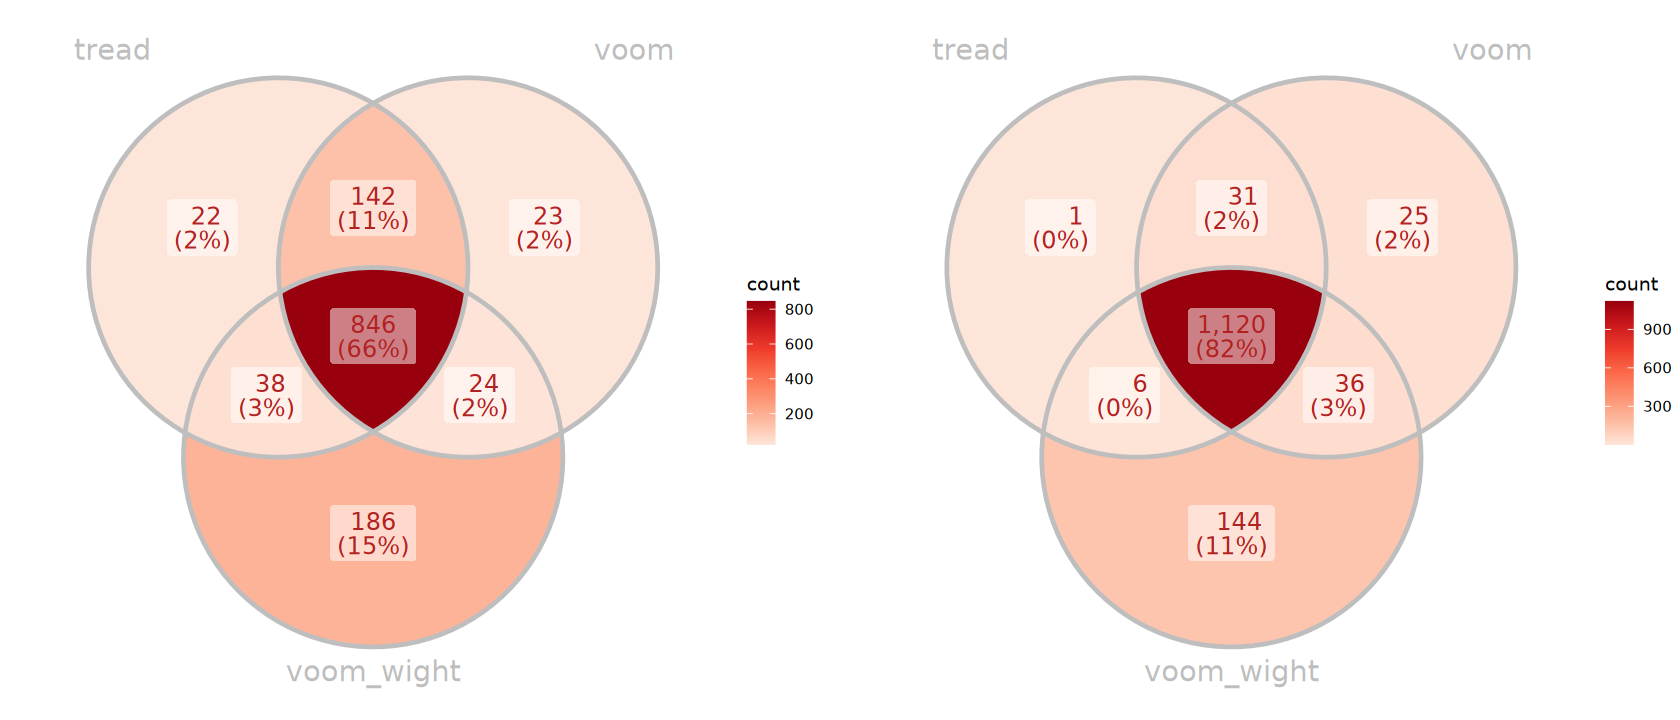

In [114]:
options(repr.plot.width = 14, repr.plot.height = 6)

p1 + plot_spacer() + p2 +
    plot_layout(nrow = 1, widths = c(1, 0.05, 1))

## DEGs Evaluation

In [115]:
add_label <- function(res, symbol_col = "symbol"){
    res |> tibble::rownames_to_column("gene_id") |>
        dplyr::group_by(result) |>
        dplyr::arrange(padj, dplyr::desc(abs(logFC)), .by_group = TRUE) |>
        dplyr::mutate(
            label = dplyr::if_else(
                result %in% c("Up", "Down") & dplyr::row_number() <= 5,
                .data[[symbol_col]], NA_character_)) |>
        dplyr::ungroup() |>
        tibble::column_to_rownames("gene_id")
}

In [116]:
deseq2_result <- add_label(deseq2_lfc_result, symbol_col = "symbol")
edger_result <- add_label(edger_glm_qlf_result, symbol_col = "symbol")
limma_result <- add_label(limma_voom_result, symbol_col = "symbol")

### P-value Histogram

Warning message:
"Removed 101 rows containing non-finite outside the scale range (`stat_bin()`)."


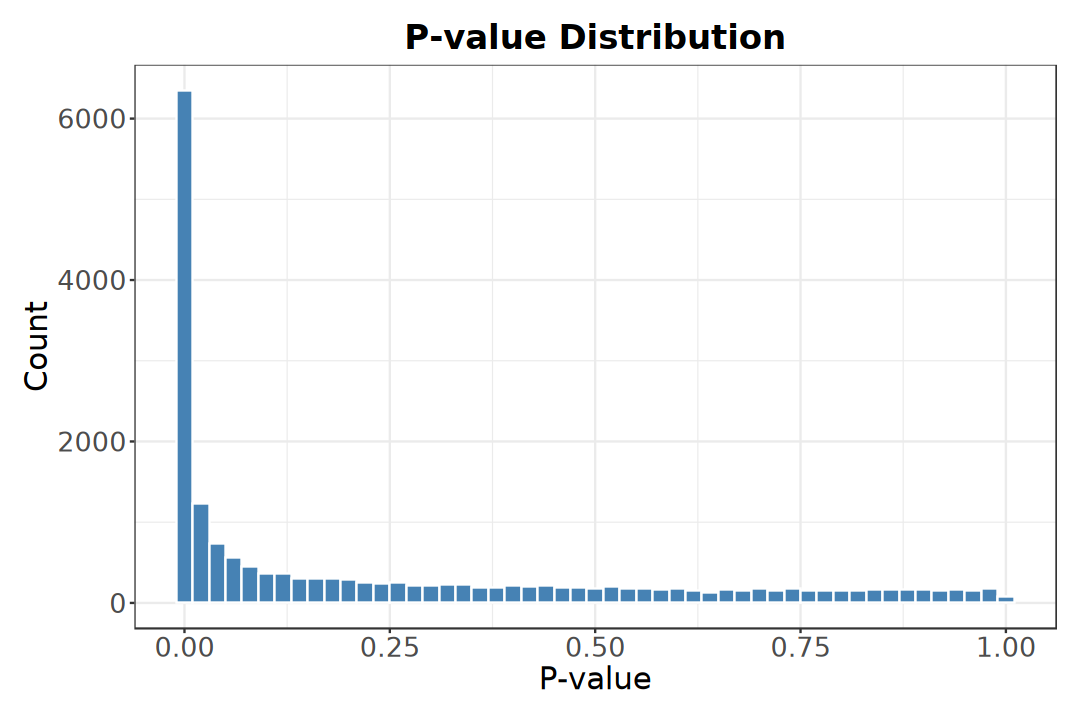

In [117]:
options(repr.plot.width = 9, repr.plot.height = 6)

ggplot(deseq2_result, aes(x = pvalue)) +
    geom_histogram(binwidth = 0.02, fill = "steelblue", color = "white") +
    labs(
        title = "P-value Distribution", 
        x = "P-value", y = "Count") +
    theme_bw() +
    theme(
        plot.title = element_text(size = 20, face = "bold", hjust = 0.5), 
        plot.margin = unit(c(1, 1, 1, 1), "line"),
        legend.title = element_text(size = 18), 
        legend.text = element_text(size = 16),
        axis.title = element_text(size = 18), 
        axis.text = element_text(size = 16))

### MA Plot

> - Mean-Difference plot
> - Bland-Altman plot

In [118]:
ggplot_maplot <- function(plot_df, col, log = FALSE, title = NULL) {
    if(log) {
        x_vals <- log2(plot_df[[col]] + 1)
    } else {
        x_vals <- plot_df[[col]]
    }

    max_logfc <- plot_df$logFC |> abs() |> 
        max(na.rm = TRUE) |> ceiling()

    ggplot(plot_df, aes(x = x_vals, y = logFC)) +
        geom_point(
            aes(color = result, size = result), na.rm = TRUE) +
        geom_hline(
            yintercept = c(-logfc_cutoff, logfc_cutoff),
            linetype = "dashed", color = "gray") +
        geom_text_repel(
            aes(label = label), color = "black", na.rm = TRUE, size = 6, 
            min.segment.length = 0, segment.size = 0.5, max.overlaps = Inf) +
        scale_y_continuous(limits = c(-max_logfc, max_logfc)) +
        scale_color_manual(
            values = c(Up = "LightCoral", Down = "SkyBlue", NS = "gray")) +
        scale_size_manual(
            values = c(Up = 2, Down = 2, NS = 1), guide = "none") +
        guides(
            color = guide_legend(override.aes = list(size = 6))) +
        labs(
            title = paste0("MA plot (", title,")"), , color = "DEG",
            x = "Mean Expression", y = "log2FC") +
        theme_test() + 
        theme(
            plot.title = element_text(size = 20, face = "bold", hjust = 0.5), 
            plot.margin = unit(c(1, 1, 1, 1), "line"),
            legend.title = element_text(size = 18), 
            legend.text = element_text(size = 16),
            axis.title = element_text(size = 18),
            axis.text = element_text(size = 16))
}

In [119]:
p1 <- ggplot_maplot(deseq2_result, col = "baseMean", log = TRUE, title = "DESeq2")
p2 <- ggplot_maplot(edger_result, col = "logCPM", title = "edgeR")
p3 <- ggplot_maplot(limma_result, col = "AveExpr", title = "limma-voom")

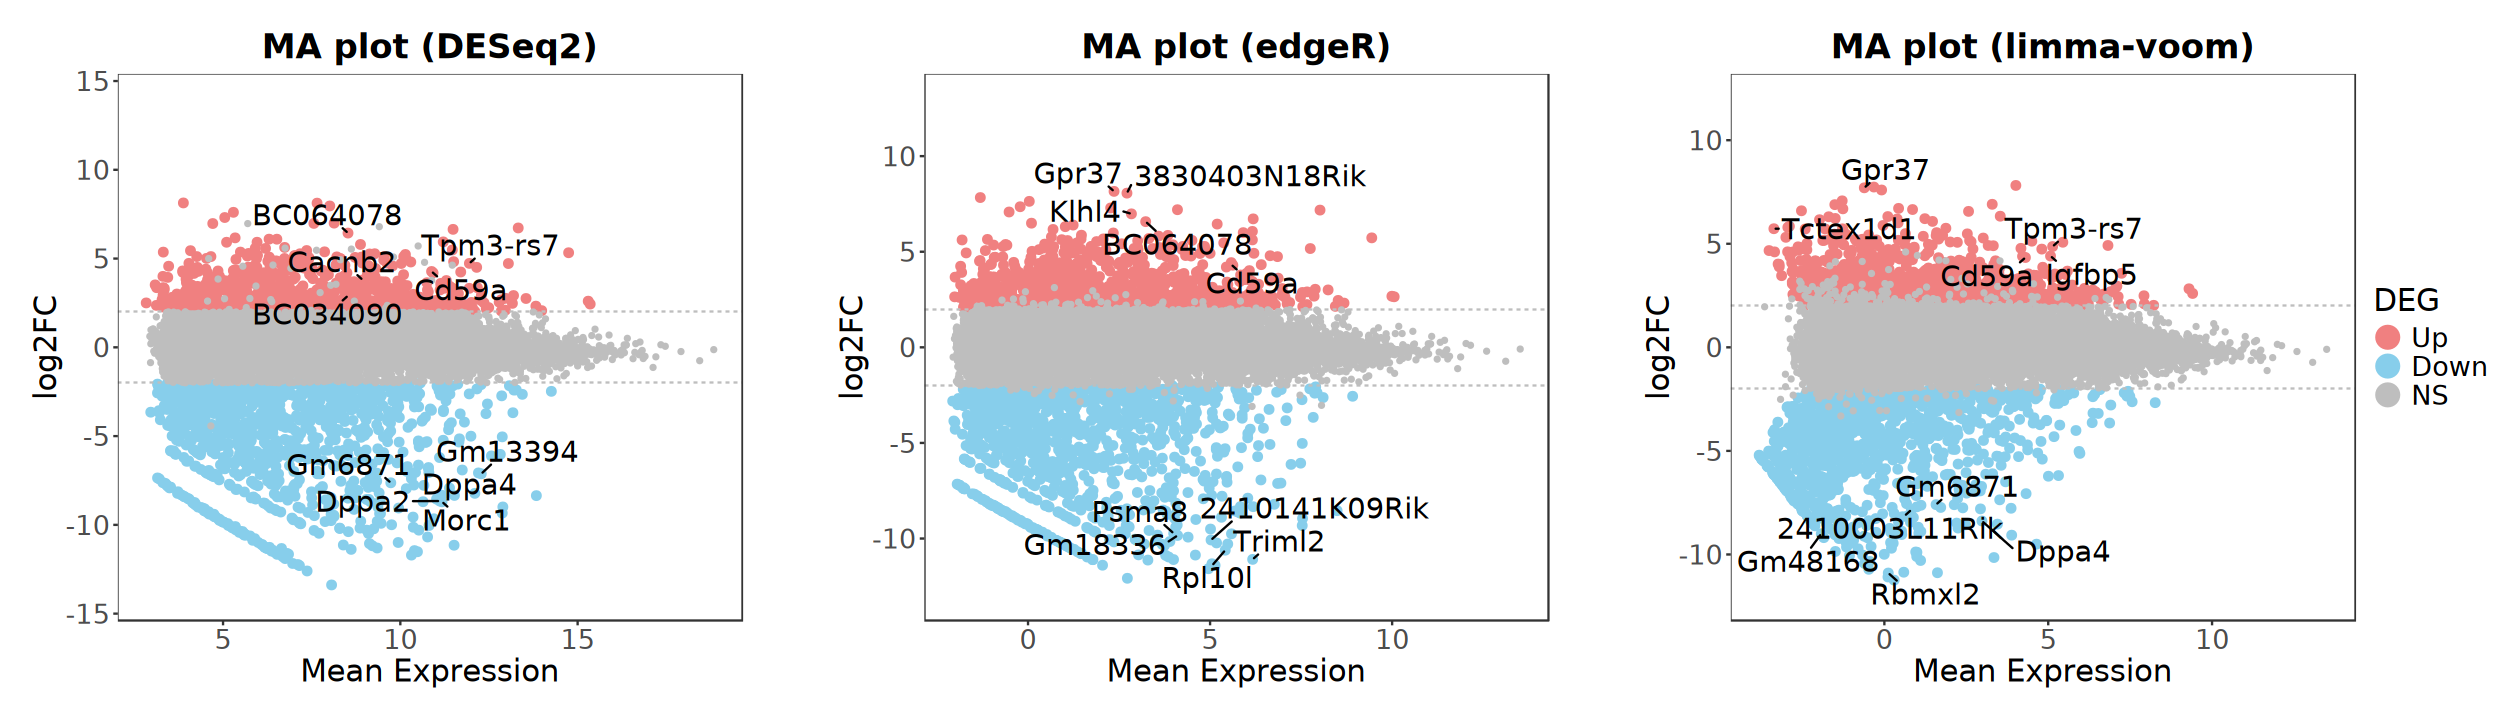

In [120]:
options(repr.plot.width = 21, repr.plot.height = 6)

p1 + plot_spacer() + p2 + plot_spacer() + p3 +
    plot_layout(
        nrow = 1, guides = "collect", 
        widths = c(1, 0.05, 1, 0.05, 1))

### Volcano

In [121]:
ggplot_volcano <- function(plot_df, title = NULL) {
    max_logfc <- plot_df$logFC |> abs() |> 
        max(na.rm = TRUE) |> ceiling()
    min_padj <- plot_df$padj |> pmax(1e-300) |> 
        (\(x) -log10(x))() |> max(na.rm = TRUE) |> 
        (\(x) ceiling(x / 5) * 5)()

    ggplot(plot_df, aes(x = logFC, y = -log10(pmax(padj, 1e-300)))) +
        geom_point(
            aes(color = result, size = result), na.rm = TRUE) +
        geom_hline(
            yintercept = -log10(p_cutoff), 
            linetype = "dashed", color = "gray") + 
        geom_vline(
            xintercept = c(-logfc_cutoff, logfc_cutoff),
            linetype = "dashed", color = "gray") +
        ggrepel::geom_text_repel(
            aes(label = label), color = "black", na.rm = TRUE, size = 4, 
            min.segment.length = 0, segment.size = 0.5, max.overlaps = Inf) +
        scale_x_continuous(
            expand = c(0.1, 0), limits = c(-max_logfc, max_logfc)) +
        scale_y_continuous(
            expand = expansion(mult = c(0, 0.1)), limits = c(0, min_padj)) + 
        scale_color_manual(
            values = c(Up = "LightCoral", Down = "SkyBlue", NS = "gray")) +
        scale_size_manual(
            values = c(Up = 2, Down = 2, NS = 1), guide = "none") +
        labs(
            title = paste0("Volcano (", title,")"), , color = "DEG",
            x = "log2FC", y = expression(-log[10](P.adjust))) +
        guides(
            color = guide_legend(override.aes = list(size = 6))) +
        theme_test() + 
        theme(
            plot.title = element_text(size = 20, face = "bold", hjust = 0.5), 
            plot.margin = unit(c(1, 1, 1, 1), "line"),
            legend.title = element_text(size = 18), 
            legend.text = element_text(size = 16),
            axis.title = element_text(size = 18), 
            axis.text = element_text(size = 16))
}

In [122]:
p1 <- ggplot_volcano(deseq2_result, title = "DESeq2")
p2 <- ggplot_volcano(edger_result, title = "edgeR")
p3 <- ggplot_volcano(limma_result, title = "limma-voom")

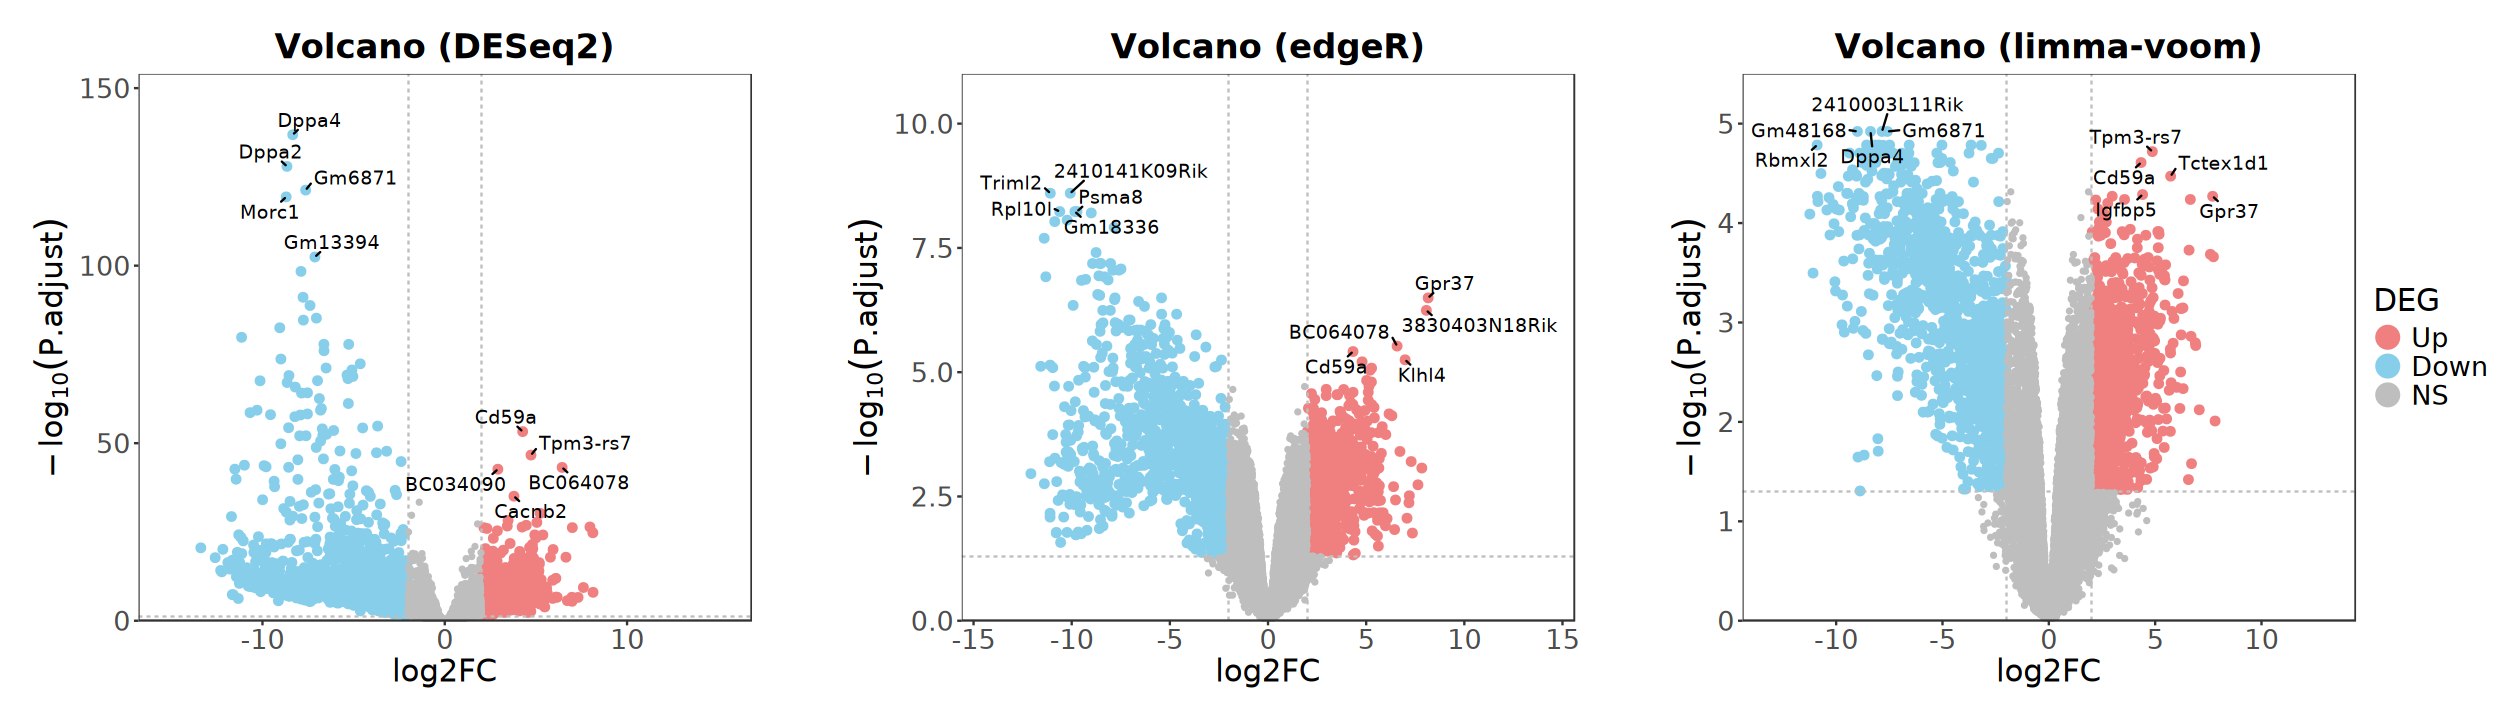

In [123]:
options(repr.plot.width = 21, repr.plot.height = 6)

p1 + plot_spacer() + p2 + plot_spacer() + p3 +
    plot_layout(
        nrow = 1, guides = "collect", 
        widths = c(1, 0.05, 1, 0.05, 1))

### Venn

In [124]:
suppressPackageStartupMessages(library(ggVennDiagram))

In [125]:
genes_up <- list(
    DESeq2 = deseq2_result |> filter(result == "Up") |> 
        pull(symbol) |> unique(),
    edgeR = edger_result |> filter(result == "Up") |> 
        pull(symbol) |> unique(),
    limma = limma_result |> filter(result == "Up") |> 
        pull(symbol) |> unique())

genes_down <- list(
    DESeq2 = deseq2_result |> filter(result == "Down") |> 
        pull(symbol) |> unique(),
    edgeR = edger_result |> filter(result == "Down") |> 
        pull(symbol) |> unique(),
    limma = limma_result |> filter(result == "Down") |> 
        pull(symbol) |> unique())

In [126]:
p1 <- ggVennDiagram(
    genes_up, set_color = "grey", set_size = 6, 
    label_color = "firebrick", label_size = 5) +
    scale_fill_distiller(palette = "Reds", direction = 1)

p2 <- ggVennDiagram(
    genes_down, set_color = "grey", set_size = 6, 
    label_color = "firebrick", label_size = 5) +
    scale_fill_distiller(palette = "Reds", direction = 1)

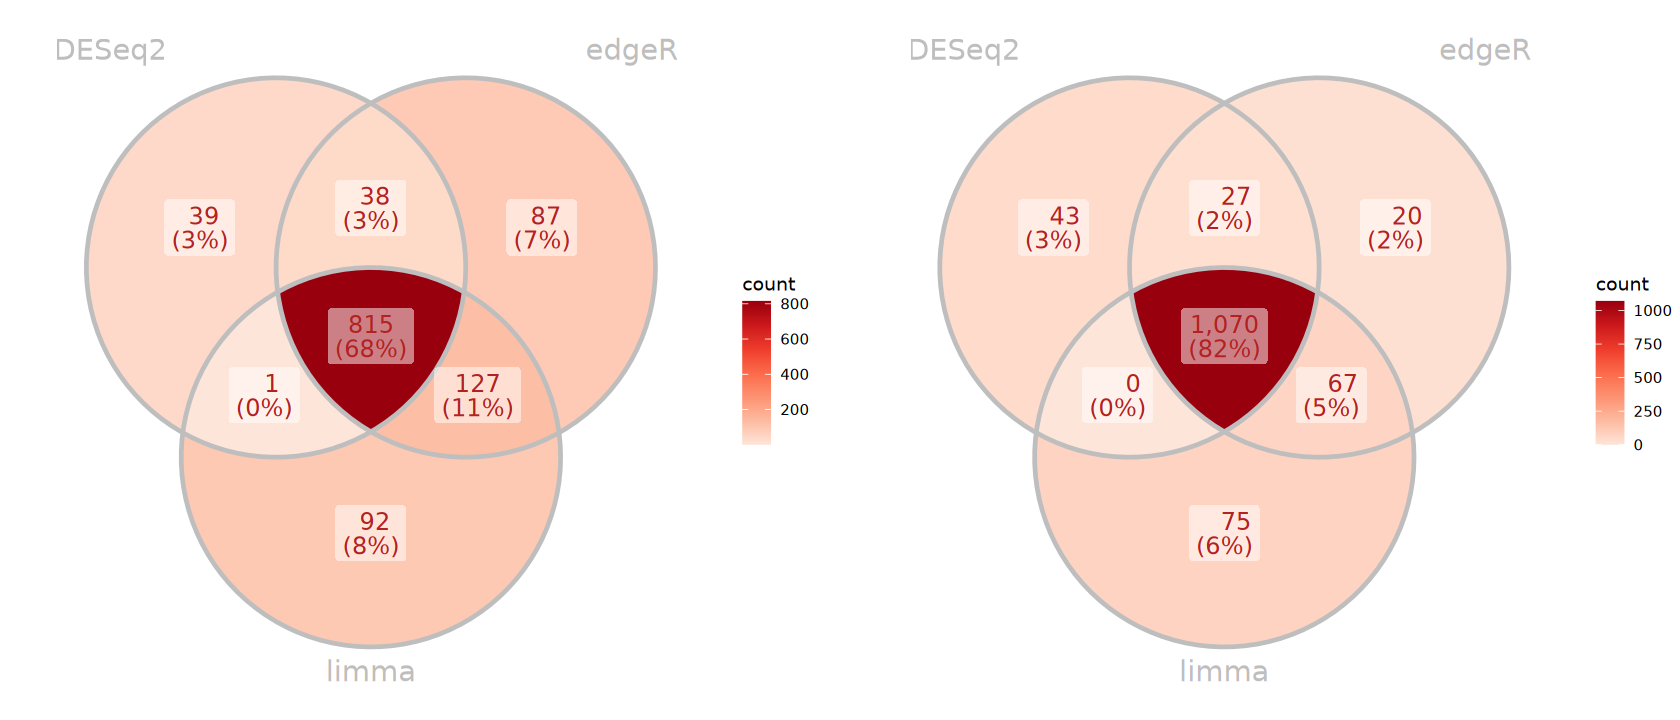

In [127]:
options(repr.plot.width = 14, repr.plot.height = 6)

p1 + plot_spacer() + p2 +
    plot_layout(nrow = 1, widths = c(1, 0.05, 1))

### Upset

In [128]:
suppressPackageStartupMessages(library(UpSetR))

Warning message:
"Using `size` aesthetic for lines was deprecated in ggplot2 3.4.0.
ℹ Please use `linewidth` instead.
ℹ The deprecated feature was likely used in the UpSetR package.
  Please report the issue to the authors."
Warning message:
"The `size` argument of `element_line()` is deprecated as of ggplot2 3.4.0.
ℹ Please use the `linewidth` argument instead.
ℹ The deprecated feature was likely used in the UpSetR package.
  Please report the issue to the authors."


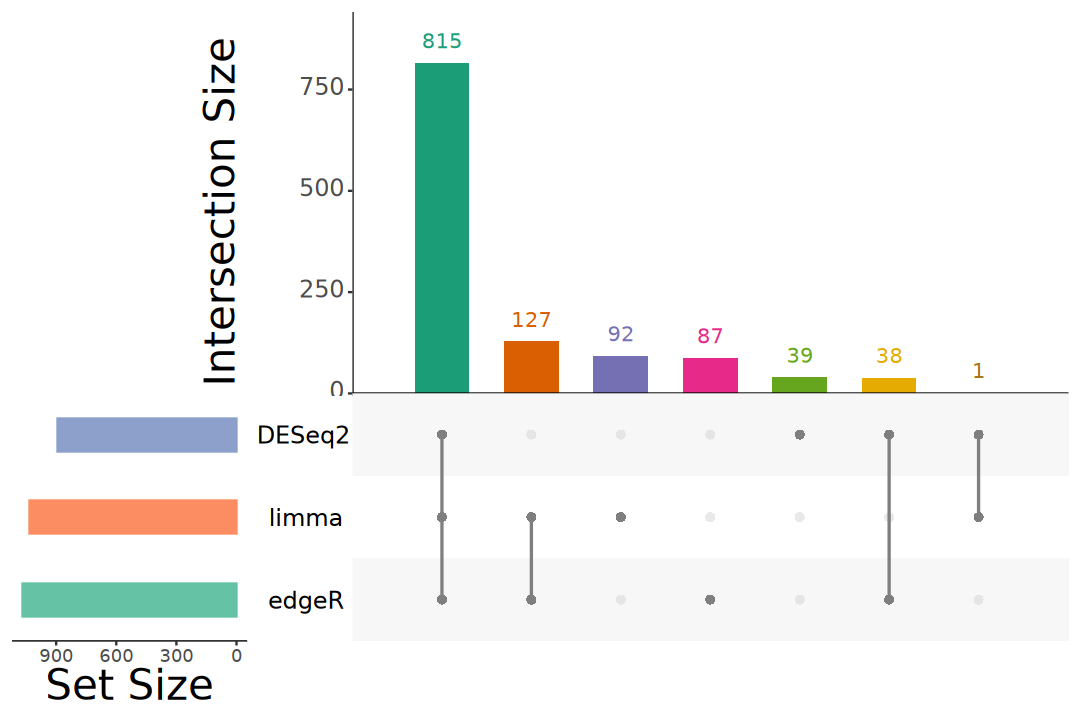

In [129]:
options(repr.plot.width = 9, repr.plot.height = 6)
UpSetR::upset(
    fromList(genes_up), mb.ratio = c(0.55, 0.45),
    order.by = "freq", decreasing = TRUE,
    sets.bar.color = brewer.pal(n = 3, name = "Set2"),
    main.bar.color = brewer.pal(n = 7, name = "Dark2"),
    matrix.color = "grey50",
    text.scale = c(3, 2, 3, 1.5, 2, 2))

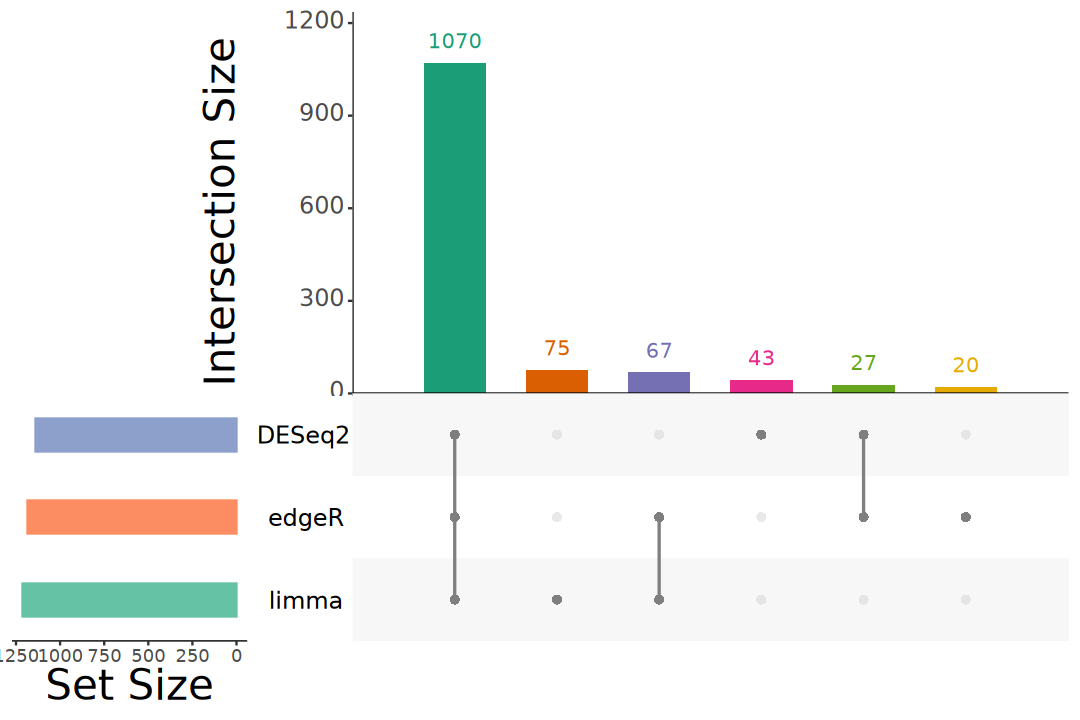

In [130]:
options(repr.plot.width = 9, repr.plot.height = 6)
UpSetR::upset(
    fromList(genes_down), mb.ratio = c(0.55, 0.45),
    order.by = "freq", decreasing = TRUE,
    sets.bar.color = brewer.pal(n = 3, name = "Set2"),
    main.bar.color = brewer.pal(n = 6, name = "Dark2"),
    matrix.color = "grey50",
    text.scale = c(3, 2, 3, 1.5, 2, 2))

## DEGs Visualization

In [131]:
res_lfc <- lfcShrink(dds, coef = "Cell_mEpiSC_vs_mESC", type = "apeglm")
summary(res_lfc)

using 'apeglm' for LFC shrinkage. If used in published research, please cite:
    Zhu, A., Ibrahim, J.G., Love, M.I. (2018) Heavy-tailed prior distributions for
    sequence count data: removing the noise and preserving large differences.
    Bioinformatics. https://doi.org/10.1093/bioinformatics/bty895




out of 18636 with nonzero total read count
adjusted p-value < 0.1
LFC > 0 (up)       : 4016, 22%
LFC < 0 (down)     : 4101, 22%
outliers [1]       : 101, 0.54%
low counts [2]     : 0, 0%
(mean count < 6)
[1] see 'cooksCutoff' argument of ?results
[2] see 'independentFiltering' argument of ?results



In [132]:
degs_result <- res_lfc |> as.data.frame() |> 
    rownames_to_column("gene_id") |>
    dplyr::rename(logFC = log2FoldChange) |>
    mutate(
        result = case_when(
            padj < p_cutoff & logFC >  logfc_cutoff ~ "Up",
            padj < p_cutoff & logFC < -logfc_cutoff ~ "Down",
            TRUE ~ "NS") |> 
            factor(levels = c("Up", "Down", "NS"))) |>
    left_join(
        rowData(dds) |> 
            as.data.frame() |> 
            dplyr::select(symbol, type, basepairs) |>
            rownames_to_column("gene_id"), 
        by = "gene_id") |>
    group_by(result) |>
    arrange(padj, logFC |> abs() |> desc()) |>
    mutate(
        label = ifelse(
            type == "protein_coding" & 
                result %in% c("Up", "Down") & 
                row_number() <= 5, 
            symbol, NA_character_)) |>
    ungroup() |>
    column_to_rownames("gene_id")

table(degs_result$result)
head(degs_result)


   Up  Down    NS 
  893  1141 16602 

,baseMean,logFC,lfcSE,pvalue,padj,result,symbol,type,basepairs,label
,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<fct>,<chr>,<chr>,<int>,<chr>
ENSMUSG00000058550.15,2947.4999,-8.340557,0.3313476,7.100296e-142,1.316040e-137,Down,Dppa4,protein_coding,1662,Dppa4
ENSMUSG00000072419.5,2213.7329,-8.656427,0.3539367,1.202151e-132,1.114094e-128,Down,Dppa2,protein_coding,2447,Dppa2
ENSMUSG00000090744.7,848.9307,-7.629416,0.3209088,8.338753e-126,5.151960e-122,Down,Gm6871,protein_coding,1892,Gm6871
ENSMUSG00000022652.7,2313.3107,-8.699530,0.3694317,8.996791e-124,4.168888e-120,Down,Morc1,protein_coding,6479,Morc1
ENSMUSG00000083773.4,4982.0756,-7.123343,0.3262588,9.748801e-107,3.613881e-103,Down,Gm13394,processed_pseudogene,1000,NA
ENSMUSG00000085860.1,545.9716,-7.886594,0.3659176,1.323990e-102,4.090025e-99,Down,2410003L11Rik,lncRNA,1144,NA


In [133]:
max_logfc <- degs_result$logFC |> abs() |> 
    max(na.rm = TRUE) |> 
    ceiling()

min_padj <- degs_result$padj |> pmax(1e-300) |>
    (\(x) -log10(x))() |>
    max(na.rm = TRUE) |>
    (\(x) ceiling(x / 5) * 5)()

### MA Plot

> - Mean-Difference plot
> - Bland-Altman plot

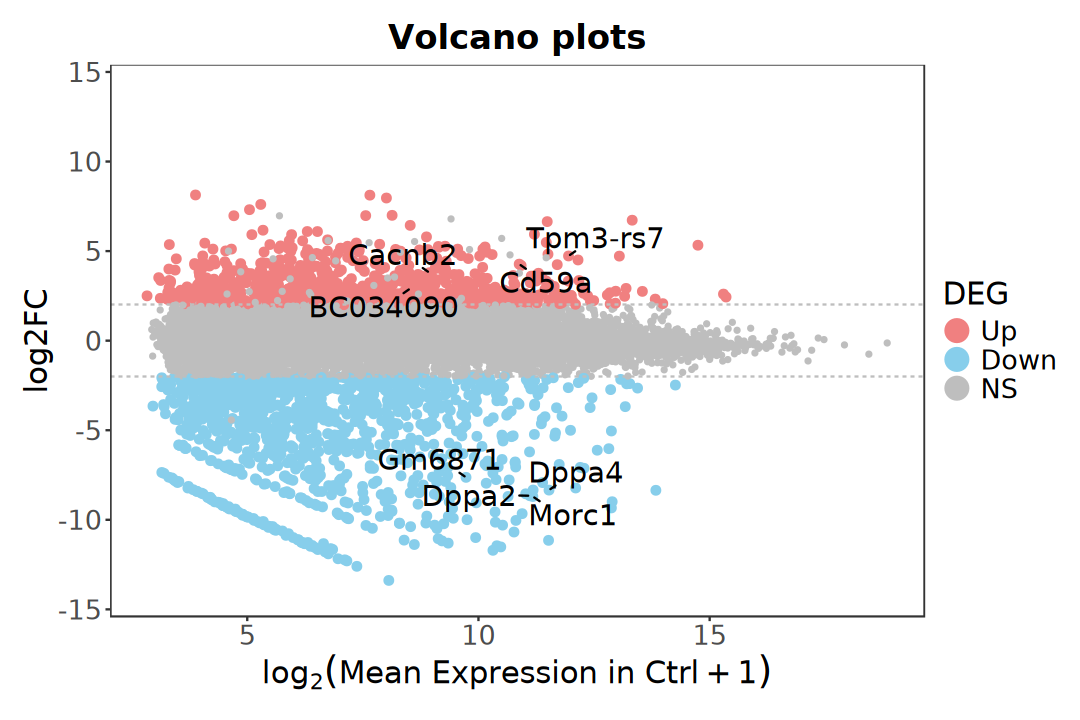

In [134]:
options(repr.plot.width = 9, repr.plot.height = 6)

ggplot(degs_result, aes(x = log2(baseMean + 1), y = logFC)) +
    geom_point(
        aes(color = result, size = result), na.rm = TRUE) +
    geom_hline(
        yintercept = c(-logfc_cutoff, logfc_cutoff),
        linetype = "dashed", color = "gray") +
    geom_text_repel(
        aes(label = label), color = "black", na.rm = TRUE, size = 6, 
        min.segment.length = 0, segment.size = 0.5, max.overlaps = Inf) +
    scale_y_continuous(limits = c(-max_logfc, max_logfc)) +
    scale_color_manual(
        values = c(Up = "LightCoral", Down = "SkyBlue", NS = "gray")) +
    scale_size_manual(
        values = c(Up = 2, Down = 2, NS = 1), guide = "none") +
    guides(
        color = guide_legend(override.aes = list(size = 6))) +
    labs(
        title = "Volcano plots", color = "DEG",
        x = expression(log[2]("Mean Expression in Ctrl" + 1)),
        y = "log2FC") +
    theme_test() + 
    theme(
        plot.title = element_text(size = 20, face = "bold", hjust = 0.5), 
        plot.margin = unit(c(1, 1, 1, 1), "line"),
        legend.title = element_text(size = 18), 
        legend.text = element_text(size = 16),
        axis.title = element_text(size = 18),
        axis.text = element_text(size = 16))

### Volcano

In [135]:
p1 <- ggplot(degs_result, aes(x = logFC, y = -log10(pmax(padj, 1e-300)))) +
    geom_point(
        aes(color = result, size = result), na.rm = TRUE) +
    geom_hline(
        yintercept = -log10(p_cutoff), 
        linetype = "dashed", color = "gray") + 
    geom_vline(
        xintercept = c(-logfc_cutoff, logfc_cutoff),
        linetype = "dashed", color = "gray") +
    geom_text_repel(
        aes(label = label), color = "black", na.rm = TRUE, size = 6, 
        min.segment.length = 0, segment.size = 0.5, max.overlaps = Inf) +
    scale_x_continuous(
        expand = c(0.1, 0), limits = c(-max_logfc, max_logfc)) +
    scale_y_continuous(
        expand = expansion(mult = c(0, 0.1)), limits = c(0, min_padj)) + 
    scale_color_manual(
        values = c(
            Up = "LightCoral", Down = "SkyBlue", NS = "gray")) +
    scale_size_manual(
        values = c(
            Up = 2, Down = 2, NS = 1), guide = "none") +
    guides(
        color = guide_legend(override.aes = list(size = 6))) +
    labs(
        title = "Volcano plots", color = "DEG",
        x = "log2FC", y = expression(-log[10](P.adjust))) +
    theme_test() + 
    theme(
        plot.title = element_text(size = 20, face = "bold", hjust = 0.5), 
        plot.margin = unit(c(1, 1, 1, 1), "line"),
        legend.title = element_text(size = 18), 
        legend.text = element_text(size = 16),
        axis.title = element_text(size = 18),
        axis.text = element_text(size = 16))

In [136]:
p2 <- ggplot(degs_result, aes(x = logFC, y = -log10(pmax(padj, 1e-300)))) +
    geom_point(
        aes(color = logFC, size = logFC), 
        na.rm = TRUE, alpha = 1) +
    geom_hline(
        yintercept = -log10(p_cutoff), 
        linetype = "dashed", color = "gray") + 
    geom_vline(
        xintercept = c(-logfc_cutoff, logfc_cutoff),
        linetype = "dashed", color = "gray") +
    geom_text_repel(
        aes(label = label), color = "black", na.rm = TRUE, size = 6, 
        min.segment.length = 0, segment.size = 0.5, max.overlaps = Inf) +
    scale_x_continuous(
        expand = c(0.1, 0), limits = c(-max_logfc, max_logfc)) +
    scale_y_continuous(
        expand = expansion(mult = c(0, 0.1)), limits = c(0, min_padj)) + 
    scale_color_gradientn(
        colours = brewer.pal(11, 'RdYlBu') |> rev(), 
        limits = c(-max_logfc, max_logfc)) +
    scale_size_continuous(range = c(1, 3), guide = "none") +
    labs(
        title = "Volcano plots",
        x = "log2FC", y = expression(-log[10](P.adjust))) +
    theme_test() + 
    theme(
        plot.title = element_text(size = 20, face = "bold", hjust = 0.5), 
        plot.margin = unit(c(1, 1, 1, 1), "line"),
        legend.title = element_text(size = 18), 
        legend.text = element_text(size = 16),
        axis.title = element_text(size = 18),
        axis.text = element_text(size = 16))

In [137]:
p3 <- degs_result |>
    mutate(
        neglog10_padj = -log10(pmax(padj, 1e-300)), 
        neglog10_padj_m = ifelse(
            logFC < 0, -neglog10_padj, neglog10_padj)) |>
    ggplot(aes(x = logFC, y = neglog10_padj)) +
        geom_point(
            aes(color = neglog10_padj_m, size = neglog10_padj), na.rm = TRUE) +
        geom_hline(
            yintercept = -log10(p_cutoff), 
            linetype = "dashed", color = "gray") + 
        geom_vline(
            xintercept = c(-logfc_cutoff, logfc_cutoff),
            linetype = "dashed", color = "gray") +
        geom_text_repel(
            aes(label = label), color = "black", na.rm = TRUE, size = 6, 
            min.segment.length = 0, segment.size = 0.5, max.overlaps = Inf) +
        scale_x_continuous(
            expand = c(0.1, 0), limits = c(-max_logfc, max_logfc)) +
        scale_y_continuous(
            expand = expansion(mult = c(0, 0.1)), limits = c(0, min_padj)) + 
        scale_color_gradientn(
            name = expression(-log[10](P.adjust)),
            colours = brewer.pal(11, 'RdBu') |> rev(), 
            limits = c(-min_padj, min_padj),
            breaks = c(-min_padj, 0, min_padj),
            labels = c(min_padj, 0, min_padj)) +
        scale_size_continuous(range = c(1, 3), guide = "none") +
        labs(
            title = "Volcano plots", color = "DEG",
            x = "log2FC", y = expression(-log[10](P.adjust))) +
        theme_test() + 
        theme(
            plot.title = element_text(size = 20, face = "bold", hjust = 0.5), 
            plot.margin = unit(c(1, 1, 1, 1), "line"),
            legend.title = element_text(size = 18), 
            legend.text = element_text(size = 16),
            legend.key.size = unit(1, "cm"),
            axis.title = element_text(size = 18),
            axis.text = element_text(size = 16))

In [138]:
p4 <- ggplot(degs_result, aes(x = logFC, y = -log10(pmax(padj, 1e-300)))) +
    geom_point(
        aes(color = -log10(pmax(padj, 1e-300)), size = -log10(pmax(padj, 1e-300))),
        na.rm = TRUE, alpha = 0.8) +
    geom_hline(
        yintercept = -log10(p_cutoff), 
        linetype = "dashed", color = "gray") + 
    geom_vline(
        xintercept = c(-logfc_cutoff, logfc_cutoff),
        linetype = "dashed", color = "gray") +
    geom_text_repel(
        aes(label = label), color = "black", na.rm = TRUE, size = 6, 
        min.segment.length = 0, segment.size = 0.5, max.overlaps = Inf) +
    scale_x_continuous(
        expand = c(0.1, 0), limits = c(-max_logfc, max_logfc)) +
    scale_y_continuous(
        expand = expansion(mult = c(0, 0.1)), limits = c(0, min_padj)) +  
    # scale_color_viridis_c(
    #     option = "turbo", begin = 0.1, end = 0.9) + 
    # scale_color_gradientn(
    #     colours = brewer.pal(11, 'RdYlBu') |> rev())+
    # scale_color_gradientn(
    #     colors = c("#39489f","#39bbec","#f9ed36","#f38466","#b81f25")) +
    scale_color_gradientn(
        colors = c(
            "#5E4FA2", "#3288BD", "#66C2A5", "#ABDDA4", 
            "#E6F598", "#FFFFBF", "#FEE08B", "#FDAE61", 
            "#F46D43", "#D53E4F", "#9C2007", "#9E0142")) +
    scale_size_continuous(range = c(1, 3), guide = "none") +
    labs(
        title = "Volcano plots", 
        color = expression(-log[10](P.adjust)),
        x = "log2FC", y = expression(-log[10](P.adjust))) +
    theme_test() + 
    theme(
        plot.title = element_text(size = 20, face = "bold", hjust = 0.5), 
        plot.margin = unit(c(1, 1, 1, 1), "line"),
        legend.title = element_text(size = 18), 
        legend.text = element_text(size = 16),
        legend.key.size = unit(1, "cm"),
        axis.title = element_text(size = 18),
        axis.text = element_text(size = 16))

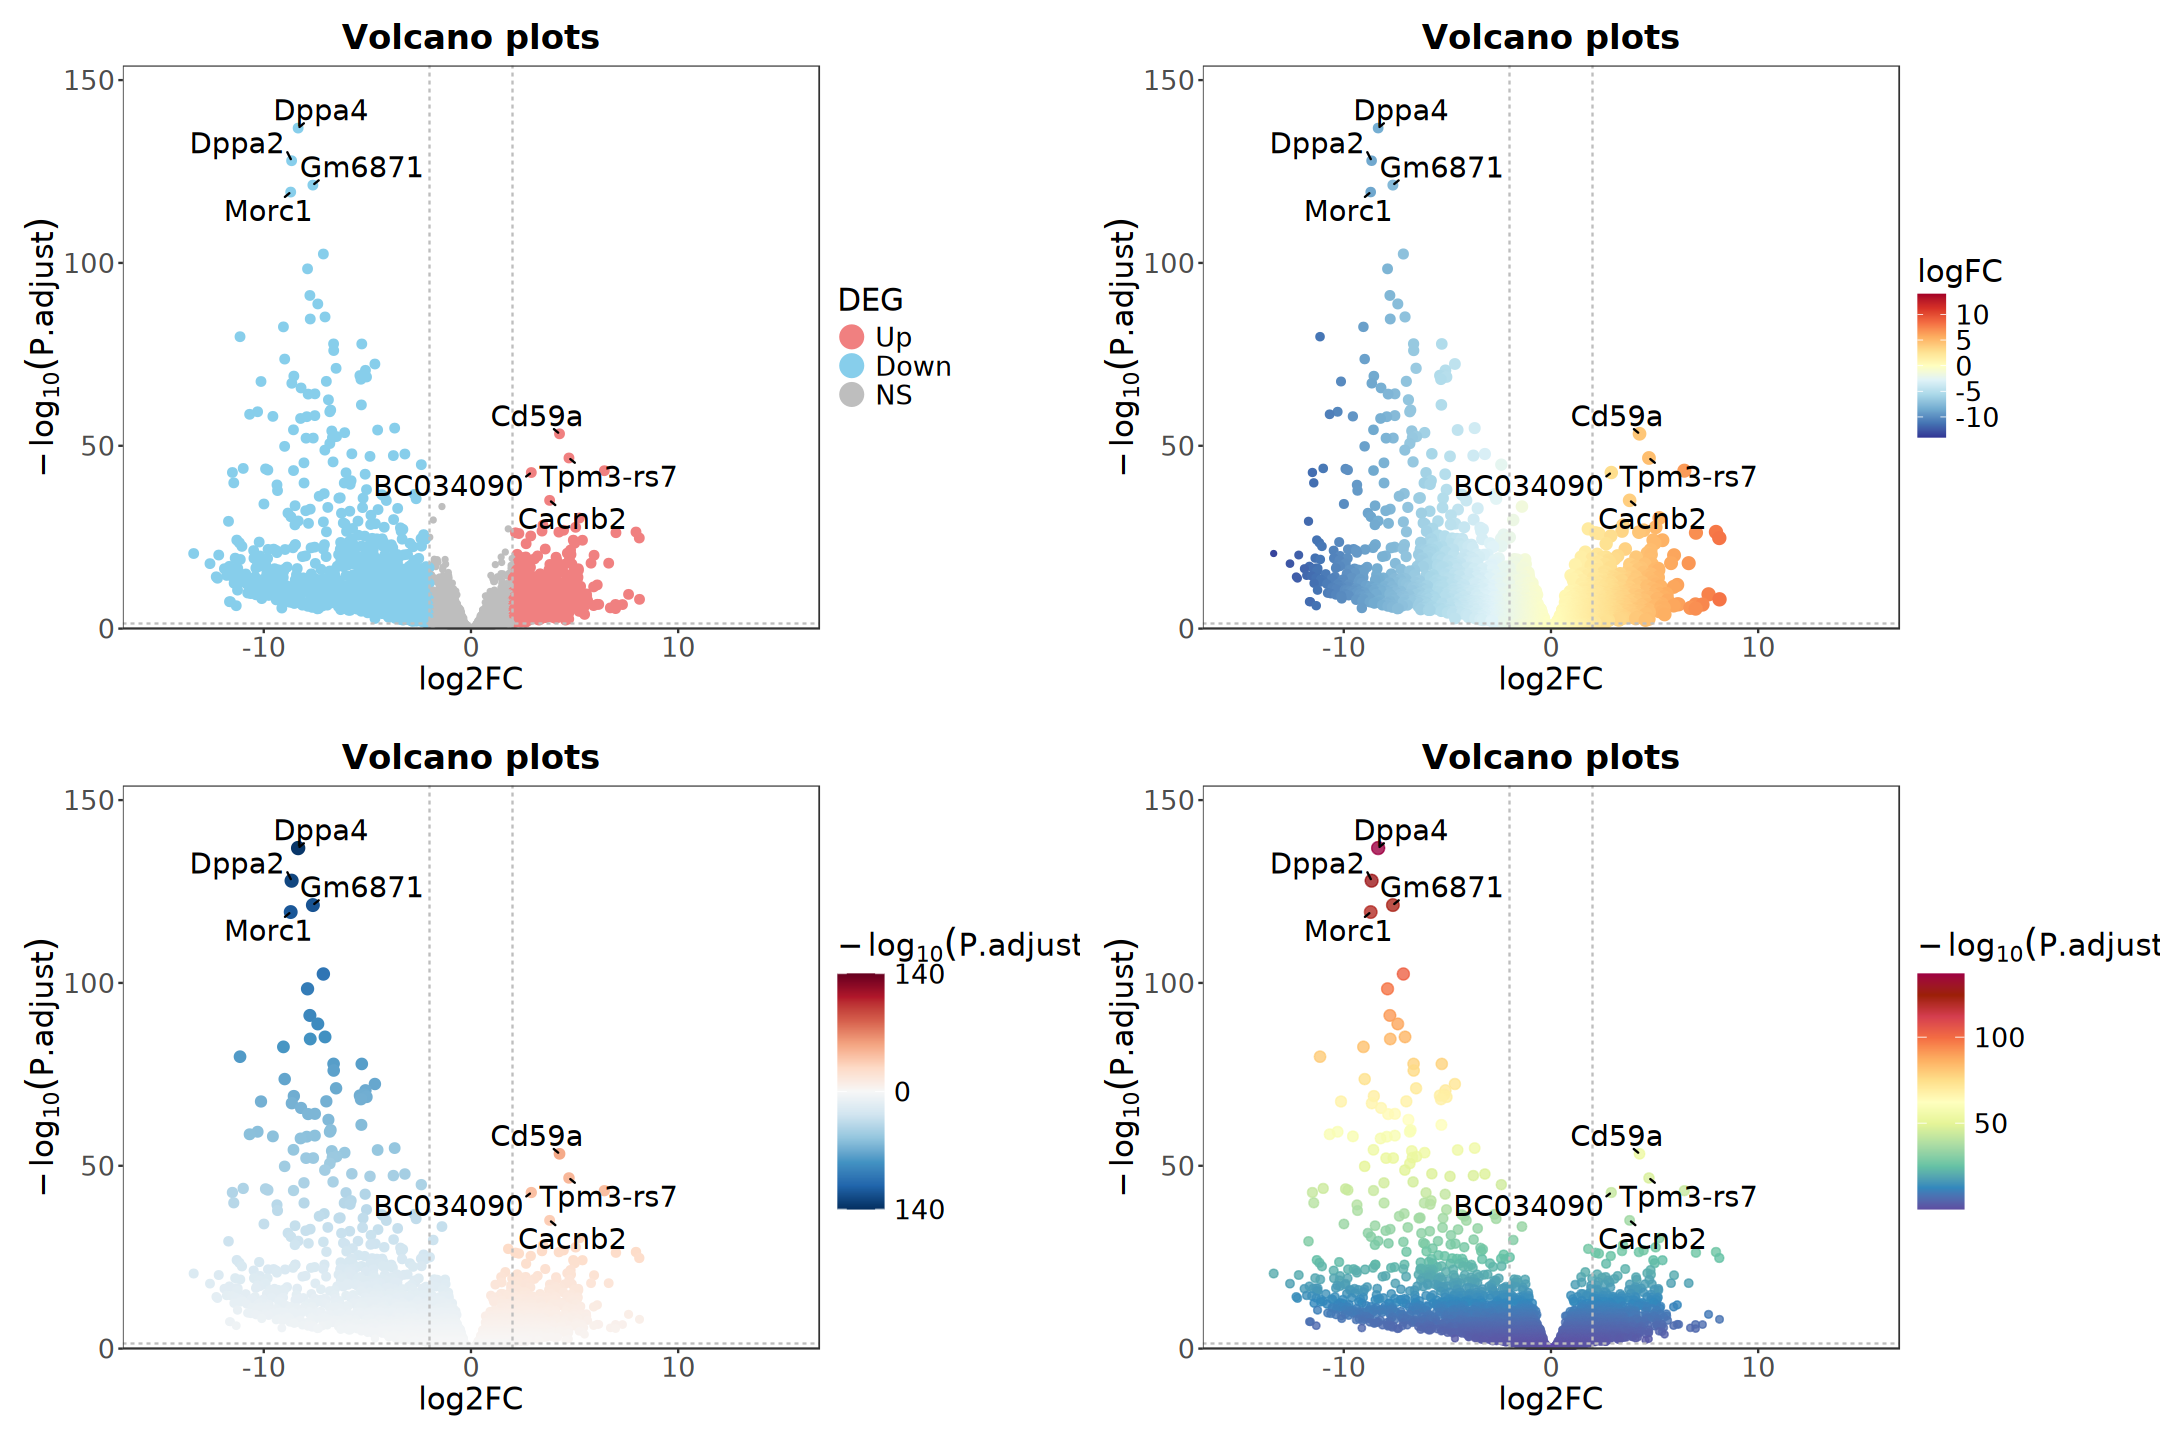

In [139]:
options(repr.plot.width = 18, repr.plot.height = 12)
cowplot::plot_grid(
    p1, p2, p3, p4, nrow = 2, align = "hv", axis = "tblr")

### Scatter Plot

In [140]:
ctrl_samples <- colnames(dds)[dds$Cell == "mESC"]
treat_samples <- colnames(dds)[dds$Cell == "mEpiSC"]

mean_expr <- dds |> 
    counts(normalized = TRUE) |> 
    as.data.frame() |> 
    rownames_to_column(var = "gene_id") |> 
    mutate(
        Ctrl_Mean = rowMeans(across(all_of(ctrl_samples))),
        Treat_Mean = rowMeans(across(all_of(treat_samples)))) |> 
    dplyr::select(gene_id, Ctrl_Mean, Treat_Mean)

In [141]:
plot_df <- degs_result |> 
    rownames_to_column(var = "gene_id") |> 
    inner_join(mean_expr, by = "gene_id") |> 
    mutate(
        log2_Ctrl = log2(Ctrl_Mean + 1),
        log2_Treat = log2(Treat_Mean + 1)) |> 
    drop_na(log2_Ctrl, log2_Treat)

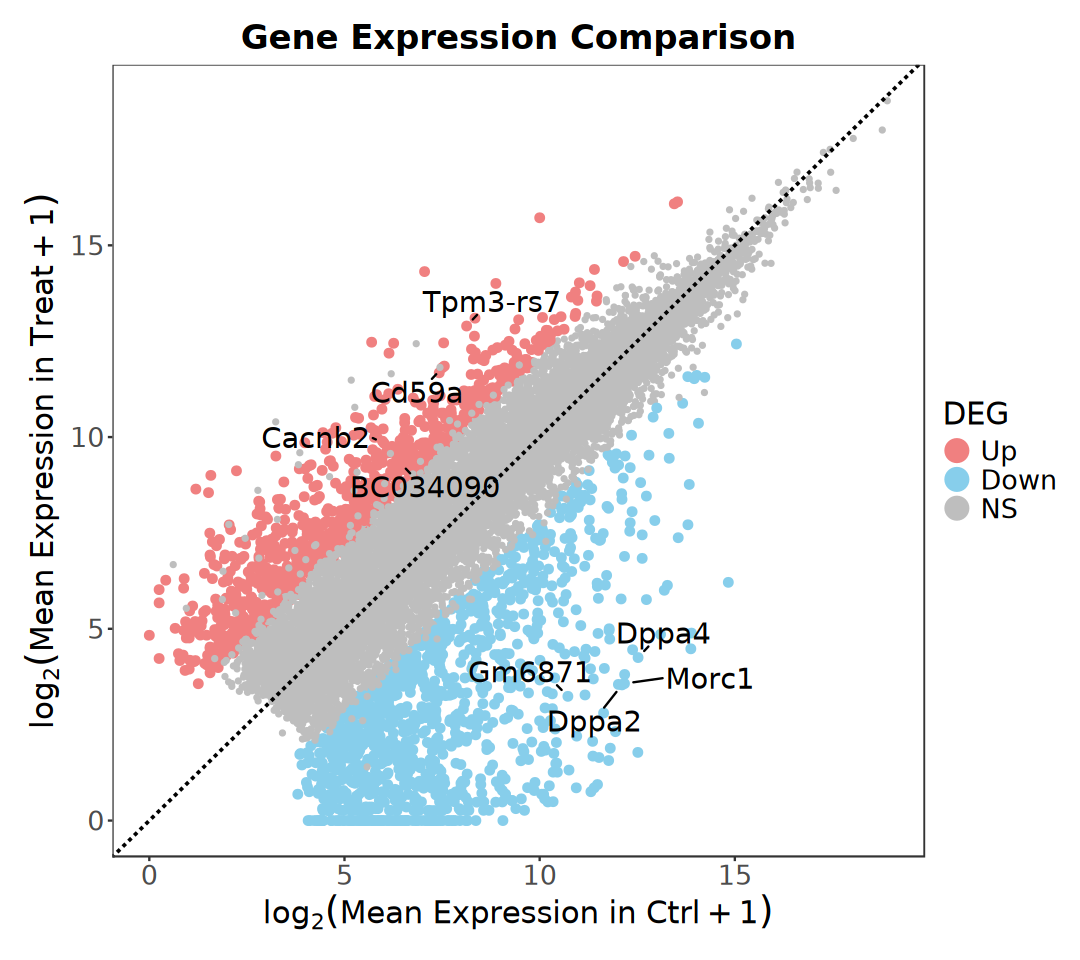

In [142]:
options(repr.plot.width = 9, repr.plot.height = 8)

ggplot(plot_df, aes(x = log2_Ctrl, y = log2_Treat)) +
    geom_point(
        aes(color = result, size = result), na.rm = TRUE) +
    geom_abline(
        intercept = 0, slope = 1, linetype = "dashed", 
        color = "black", linewidth = 0.8) +
    geom_text_repel(
        aes(label = label), color = "black", na.rm = TRUE, size = 6, 
        box.padding = 0.5, point.padding = 0.3,
        min.segment.length = 0, segment.size = 0.5, max.overlaps = Inf) +
    scale_color_manual(
        values = c(Up = "LightCoral", Down = "SkyBlue", NS = "gray")) +
    scale_size_manual(
        values = c(Up = 2, Down = 2, NS = 1), guide = "none") +
    guides(
        color = guide_legend(override.aes = list(size = 6))) +
    labs(
        title = "Volcano plots", color = "DEG",
        x = "log2FC", y = expression(-log[10](P.adjust))) +
    labs(
        title = "Gene Expression Comparison",
        x = expression(log[2]("Mean Expression in Ctrl" + 1)),
        y = expression(log[2]("Mean Expression in Treat" + 1))) + 
    theme_test() + 
    theme(
        plot.title = element_text(size = 20, face = "bold", hjust = 0.5), 
        plot.margin = unit(c(1, 1, 1, 1), "line"),
        legend.title = element_text(size = 18), 
        legend.text = element_text(size = 16),
        axis.title = element_text(size = 18),
        axis.text = element_text(size = 16))

### Heatmap

In [143]:
heatmap_dat <- degs_result |>
    filter(result %in% c("Up", "Down")) |>
    rownames() |>
    (\(idx) norm_mat[idx, ])()

In [144]:
ar <- degs_result |> 
    dplyr::select(DEG = result, logFC)

ac <- colData(dds) |> as.data.frame() |>
    dplyr::select(Replicate, Cell)

In [145]:
group_colors <- setNames(
    scales::brewer_pal(palette = "Set1")(nlevels(dds$Cell)),
    levels(dds$Cell))
replicate_colors <- setNames(
    scales::brewer_pal(palette = "Set2")(nlevels(dds$Replicate)),
    levels(dds$Replicate))
deg_colors <- c(Up = "LightCoral", Down = "SkyBlue", NS = "grey")

anno_colors <- list(
    Cell = group_colors, Replicate = replicate_colors, DEG = deg_colors, 
    logFC = colorRampPalette(brewer.pal(9, "PiYG"))(255) |> rev())

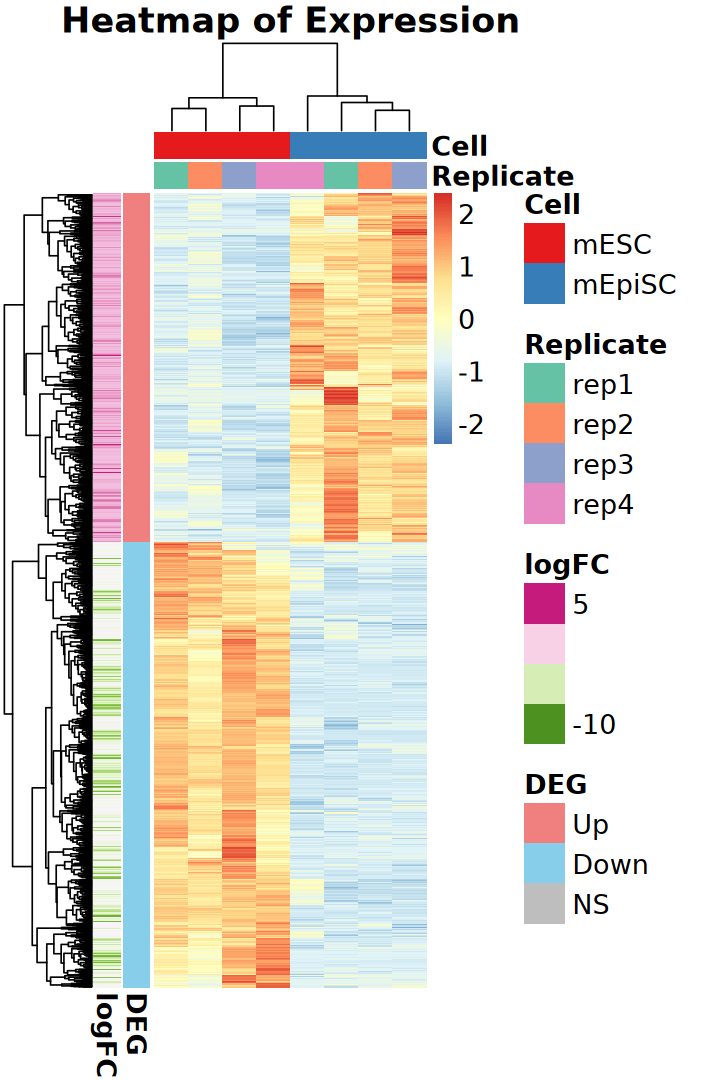

In [146]:
options(repr.plot.width = 6, repr.plot.height = 9)

pheatmap::pheatmap(
    heatmap_dat, scale = "row",
    annotation_row = ar, annotation_col = ac, 
    annotation_colors = anno_colors, 
    main = "Heatmap of Expression", fontsize = 16, 
    show_colnames = FALSE, show_rownames = FALSE)

In [147]:
lr <- degs_result |>
    rownames_to_column("gene_id") |>
    filter(gene_id %in% rownames(heatmap_dat)) |>
    arrange(factor(gene_id, levels = rownames(heatmap_dat))) |>
    pull(label) |>
    replace_na("")

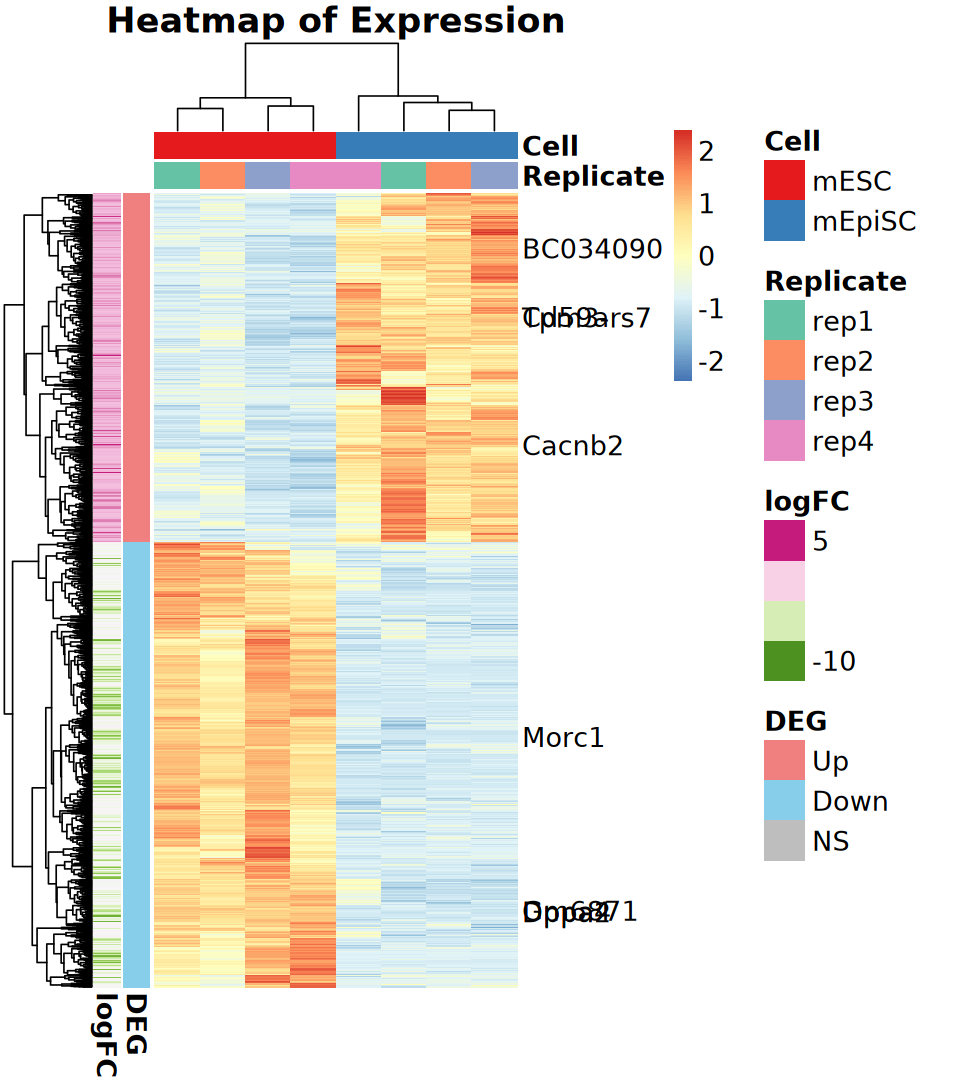

In [148]:
options(repr.plot.width = 8, repr.plot.height = 9)

pheatmap::pheatmap(
    heatmap_dat, scale = "row",
    annotation_row = ar, annotation_col = ac, 
    annotation_colors = anno_colors, labels_row = lr,
    main = "Heatmap of Expression", fontsize = 16, 
    show_colnames = FALSE, show_rownames = TRUE)

### ComplexHeatmap

In [149]:
# suppressPackageStartupMessages(library(circlize))
suppressPackageStartupMessages(library(ComplexHeatmap))

In [150]:
heatmap_dat <- degs_result |>
    filter(result %in% c("Up", "Down")) |>
    rownames() |>
    (\(idx) norm_mat[idx, ])()

In [151]:
heatmap_col <- circlize::colorRamp2(
    breaks = c(-2, 0, 2), 
    colors = brewer.pal(n = 11, name = "RdYlBu")[c(3,6,9)] |> rev())

group_colors <- setNames(
    scales::brewer_pal(palette = "Set1")(nlevels(dds$Cell)),
    levels(dds$Cell))
replicate_colors <- setNames(
    scales::brewer_pal(palette = "Set2")(nlevels(dds$Replicate)),
    levels(dds$Replicate))

deg_colors <- c(Up = "LightCoral", Down = "SkyBlue", NS = "grey")

In [152]:
ac <- colData(dds) |> as.data.frame() |>
    dplyr::select(Cell, Replicate)

top_anno <- HeatmapAnnotation(
    df = ac, col = list(
        Cell = group_colors, 
        Replicate = replicate_colors))

In [153]:
ar <- degs_result |> 
    dplyr::select(logFC, DEG = result) |>
    rownames_to_column("gene_id") |>
    filter(gene_id %in% rownames(heatmap_dat)) |>
    column_to_rownames("gene_id")

anno_colors <- list(
    DEG = deg_colors, 
    logFC = circlize::colorRamp2(
        breaks = c(-5, 0, 5),
        colors = rev(brewer.pal(n = 3, name = "PiYG"))))

left_anno <- rowAnnotation(
    df = ar, col = anno_colors, show_legend = FALSE)

In [154]:
right_anno <- rowAnnotation(
    foo = anno_mark(
        at = which(!is.na(degs_result$label)),
        labels = degs_result$symbol[which(!is.na(degs_result$label))],
        labels_gp = gpar(fontsize = 12)))

In [155]:
ar <- degs_result |> 
    dplyr::select(DEG = result, logFC)

ac <- colData(dds) |> as.data.frame() |>
    dplyr::select(Replicate, Cell)

In [156]:
lg_heatmap <- Legend(
    title = "Expression (z-score)", col_fun = heatmap_col)
lg_group <- Legend(
    title = "Cell", labels = levels(dds$Cell))
lg_replicate <- Legend(
    title = "Replicate", labels = levels(dds$Replicate))
lg_logfc <- Legend(
    title = "logFC", col_fun = anno_colors$logFC)
lg_deg <- Legend(
    labels = levels(degs_result$result), title = "DEG", 
    legend_gp = gpar(fill = deg_colors))

combined_leg <- list(lg_heatmap, lg_group, lg_replicate) |>
    packLegend(direction = "vertical")

In [157]:
ht <- heatmap_dat |> t() |> scale() |> t() |>
    Heatmap(
        name = "Expression", col = heatmap_col,
        top_annotation = top_anno,
        left_annotation = left_anno, 
        right_annotation = right_anno,
        show_row_names = FALSE, show_column_names = FALSE)

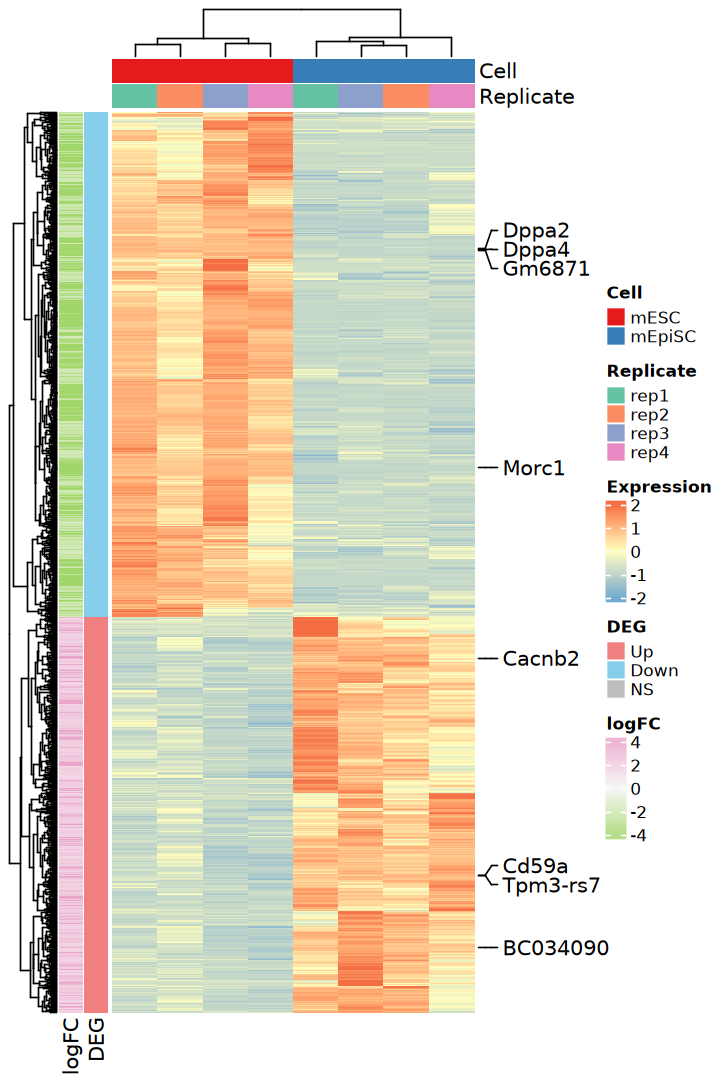

In [158]:
options(repr.plot.width = 6, repr.plot.height = 9)

draw(
    ht + combined_leg, merge_legend = TRUE,
    annotation_legend_list = list(lg_deg, lg_logfc), 
    legend_title_gp = gpar(fontsize = 12, fontface = "bold"),
    legend_labels_gp = gpar(fontsize = 10), 
    padding = unit(c(2, 2, 2, 5), "mm"))

# 6. Functional Enrichment Analysis

In [159]:
suppressPackageStartupMessages(library(org.Mm.eg.db))
suppressPackageStartupMessages(library(clusterProfiler))

## 1). ORA

> Over-Representation Analysis

In [160]:
add_ENTREZID <- function(
    res, orgdb, fromType = "SYMBOL", toType = "ENTREZID", 
    ignoreVersion = FALSE) {
    
    gene_ids <- rownames(res)

    if(fromType == "ENSEMBL" & ignoreVersion) {
        gene_ids <- sub("\\..*$", "", gene_ids)
    }

    gene_map <- clusterProfiler::bitr(
        gene_ids, OrgDb = orgdb, drop = FALSE, 
        fromType = fromType, toType = toType)
    
    idx <- match(gene_ids, gene_map[[fromType]])

    for (col in toType) {
        res[[col]] <- gene_map[[col]][idx]
    }
    
    return(res)
}

In [161]:
deseq2_result <- add_ENTREZID(
    deseq2_result, org.Mm.eg.db, fromType = "ENSEMBL", 
    toType = c("SYMBOL", "ENTREZID"), ignoreVersion = TRUE)
edger_result <- add_ENTREZID(
    edger_result, org.Mm.eg.db, fromType = "ENSEMBL", 
    toType = c("SYMBOL", "ENTREZID"), ignoreVersion = TRUE)
limma_result <- add_ENTREZID(
    limma_result, org.Mm.eg.db, fromType = "ENSEMBL", 
    toType = c("SYMBOL", "ENTREZID"), ignoreVersion = TRUE)

'select()' returned 1:many mapping between keys and columns

Warning message in clusterProfiler::bitr(gene_ids, OrgDb = orgdb, drop = FALSE, :
"13.18% of input gene IDs are fail to map..."
'select()' returned 1:many mapping between keys and columns

Warning message in clusterProfiler::bitr(gene_ids, OrgDb = orgdb, drop = FALSE, :
"12.67% of input gene IDs are fail to map..."
'select()' returned 1:many mapping between keys and columns

Warning message in clusterProfiler::bitr(gene_ids, OrgDb = orgdb, drop = FALSE, :
"12.67% of input gene IDs are fail to map..."


In [162]:
extract_gene_lists <- function(
    results_map, gene_col = "SYMBOL", result_col = "result", 
    directions = c("Up", "Down")) {
        
    lapply(names(results_map), function(method) {
        lapply(directions, function(dir) {
            df <- results_map[[method]]
            df[[gene_col]][df[[result_col]] == dir]
        })
    }) |>
    unlist(recursive = FALSE) |>
    setNames(
        nm = as.vector(t(outer(
            names(results_map), directions, paste, sep = "-"))))
}

In [163]:
results_map <- list(
    DESeq2 = deseq2_result, 
    edgeR  = edger_result,
    limma  = limma_result)

genes_list <- extract_gene_lists(
    results_map, gene_col = "symbol", result_col = "result")

In [164]:
ego_compare <- compareCluster(
    geneCluster = genes_list, fun = enrichGO, 
    universe = unique(c(deseq2_result$SYMBOL, edger_result$SYMBOL)), 
    OrgDb = org.Mm.eg.db, ont = "ALL", 
    keyType = 'SYMBOL', pAdjustMethod = "BH",
    pvalueCutoff = 0.01, qvalueCutoff = 0.05, 
    minGSSize = 10, maxGSSize = 500, readable = TRUE)

In [165]:
ego_compare |> dplyr::select(-one_of("geneID")) |> head()

,Cluster,ONTOLOGY,ID,Description,GeneRatio,BgRatio,RichFactor,FoldEnrichment,zScore,pvalue,p.adjust,qvalue,Count
,<fct>,<chr>,<chr>,<chr>,<chr>,<chr>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<int>
1,DESeq2-Up,BP,GO:0045165,cell fate commitment,55/762,256/14618,0.2148438,4.121504,11.81583,9.096302e-20,4.201582e-16,2.983587e-16,55
2,DESeq2-Up,BP,GO:0072001,renal system development,62/762,344/14618,0.1802326,3.457532,10.81666,4.445820e-18,1.026762e-14,7.291144e-15,62
3,DESeq2-Up,BP,GO:0060537,muscle tissue development,71/762,440/14618,0.1613636,3.095556,10.46660,8.186137e-18,1.260392e-14,8.950177e-15,71
4,DESeq2-Up,BP,GO:0007389,pattern specification process,70/762,443/14618,0.1580135,3.031289,10.18122,4.461474e-17,5.151887e-14,3.658408e-14,70
5,DESeq2-Up,BP,GO:0098742,cell-cell adhesion via plasma-membrane adhesion molecules,44/762,197/14618,0.2233503,4.284690,10.88473,1.028637e-16,9.502552e-14,6.747861e-14,44
6,DESeq2-Up,BP,GO:0001822,kidney development,58/762,332/14618,0.1746988,3.351374,10.16303,2.464513e-16,1.897264e-13,1.347267e-13,58


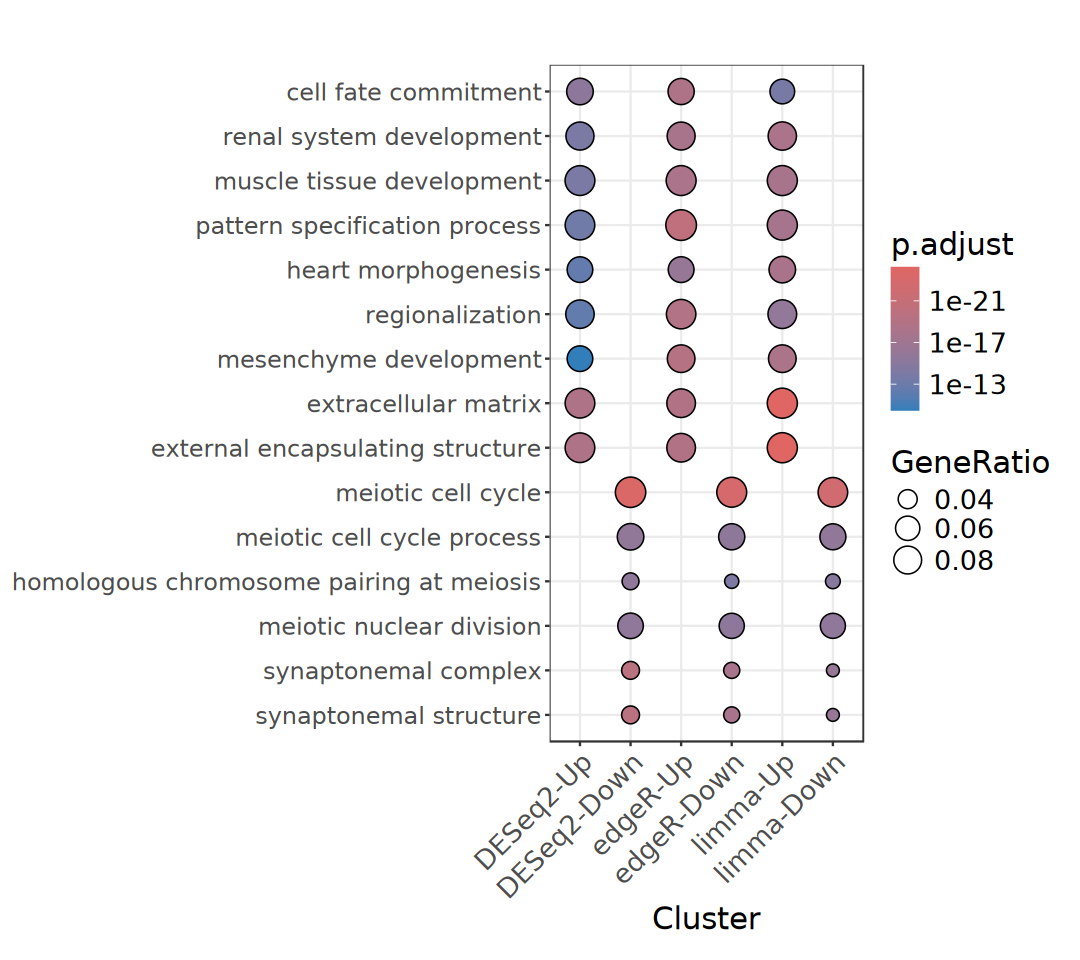

In [166]:
options(repr.plot.width = 9, repr.plot.height = 8)

dotplot(ego_compare, showCategory = 5, label_format = 50) + 
    theme_bw() +
    theme(
        plot.title = element_text(size = 20, face = "bold", hjust = 0.5), 
        plot.margin = unit(c(1, 1, 1, 1), "line"),
        legend.title = element_text(size = 18), 
        legend.text = element_text(size = 16),
        axis.title = element_text(size = 18), 
        axis.text.x = element_text(size = 16, angle = 45, hjust = 1), 
        axis.text.y = element_text(size = 14))

In [167]:
genes_list <- extract_gene_lists(
    results_map, gene_col = "ENTREZID", result_col = "result")

In [168]:
ekegg_compare <- compareCluster(
    geneCluster = genes_list, fun = enrichKEGG, 
    universe = unique(c(deseq2_result$ENTREZID, edger_result$ENTREZID)), 
    organism = "mmu", pAdjustMethod = "BH",
    pvalueCutoff = 0.01, qvalueCutoff = 0.05, 
    minGSSize = 10, maxGSSize = 500)

In [169]:
ekegg_compare |> dplyr::select(-one_of("geneID")) |> head()

,Cluster,category,subcategory,ID,Description,GeneRatio,BgRatio,RichFactor,FoldEnrichment,zScore,pvalue,p.adjust,qvalue,Count
,<fct>,<chr>,<chr>,<chr>,<chr>,<chr>,<chr>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<int>
1,DESeq2-Up,Environmental Information Processing,Signaling molecules and interaction,mmu04519,Cadherin signaling,40/381,296/6583,0.1351351,2.334894,5.824336,3.065865e-07,8.891008e-05,7.487165e-05,40
2,DESeq2-Up,Environmental Information Processing,Signaling molecules and interaction,mmu04514,Cell adhesion molecule (CAM) interaction,20/381,123/6583,0.1626016,2.809466,5.020677,2.180859e-05,3.162246e-03,2.662944e-03,20
3,DESeq2-Up,Environmental Information Processing,Signaling molecules and interaction,mmu04518,Integrin signaling,20/381,136/6583,0.1470588,2.540914,4.500332,9.545807e-05,7.815145e-03,6.581175e-03,20
4,DESeq2-Up,Environmental Information Processing,Signal transduction,mmu04020,Calcium signaling pathway,26/381,204/6583,0.1274510,2.202125,4.322790,1.077951e-04,7.815145e-03,6.581175e-03,26
5,DESeq2-Up,Human Diseases,Cardiovascular disease,mmu05414,Dilated cardiomyopathy,15/381,88/6583,0.1704545,2.945150,4.552820,1.350837e-04,7.834854e-03,6.597772e-03,15
6,DESeq2-Up,Human Diseases,Cancer: overview,mmu05202,Transcriptional misregulation in cancer,21/381,154/6583,0.1363636,2.356120,4.220485,1.927246e-04,9.315020e-03,7.844228e-03,21


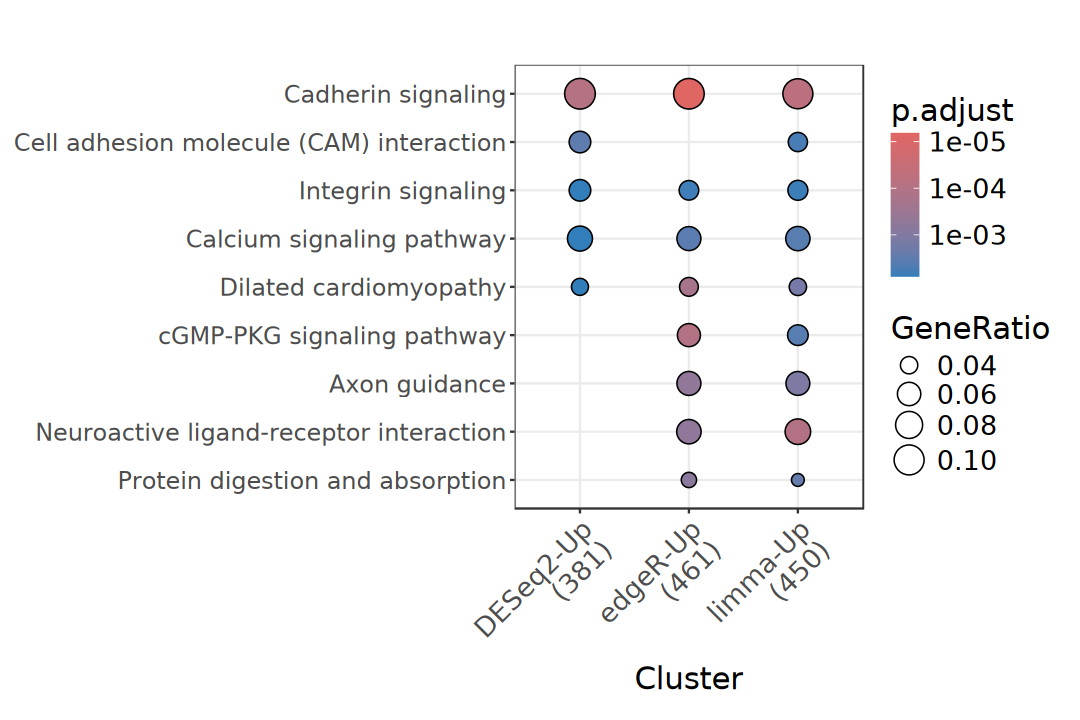

In [170]:
options(repr.plot.width = 9, repr.plot.height = 6)

dotplot(ekegg_compare, showCategory = 5, label_format = 50) + 
    theme_bw() +
    theme(
        plot.title = element_text(size = 20, face = "bold", hjust = 0.5), 
        plot.margin = unit(c(1, 1, 1, 1), "line"),
        legend.title = element_text(size = 18), 
        legend.text = element_text(size = 16),
        axis.title = element_text(size = 18), 
        axis.text.x = element_text(size = 16, angle = 45, hjust = 1), 
        axis.text.y = element_text(size = 14))

## 2). GSEA

> Gene Set Enrichment Analysis

# Reference

> 1. Law CW, Alhamdoosh M, Su S, Dong X, Tian L, Smyth GK, Ritchie ME (2018). “RNA-seq analysis is easy as 1-2-3 with limma, Glimma and edgeR.” F1000Research, 5, 1408. https://f1000research.com/articles/5-1408/v3. [RNA-seq analysis is easy as 1-2-3 with limma, Glimma and edgeR](https://www.bioconductor.org/packages/release/workflows/html/RNAseq123.html)
> 2. Law CW, Zeglinski K, Dong X, Alhamdoosh M, Smyth GK, Ritchie ME (2020). “A guide to creating design matrices for gene expression experiments.” F1000Research, 9, 1444. https://f1000research.com/articles/9-1444. [A guide to creating design matrices for gene expression experiments](https://www.bioconductor.org/packages/release/workflows/vignettes/RNAseq123/inst/doc/designmatrices.html)
> 2. Love MI, Anders S, Kim V, Huber W (2016). “RNA-Seq workflow: gene-level exploratory analysis and differential expression.” F1000Research. doi:10.12688/f1000research.7035.2. [RNA-seq workflow: gene-level exploratory analysis and differential expression](https://www.bioconductor.org/packages/release/workflows/html/rnaseqGene.html)
> 3. Chen Y, Lun ATL, Smyth GK (2016). “From reads to genes to pathways: differential expression analysis of RNA-Seq experiments using Rsubread and the edgeR quasi-likelihood pipeline.” F1000Research, 5, 1438. http://f1000research.com/articles/5-1438. [Gene-level RNA-seq differential expression and pathway analysis using Rsubread and the edgeR quasi-likelihood pipeline](https://www.bioconductor.org/packages/release/workflows/html/RnaSeqGeneEdgeRQL.html)